# Journal campaign: measured evidence review

This is a portable CPU-only companion to a retrieved Kaggle campaign. It embeds measured records, selection metadata and figure snapshots. It does not train a model, access the network or require Kaggle credentials. Validation and frozen test estimates stay separate. Partial campaigns and incomplete blocks remain explicit. The independent interval arithmetic below checks the reported approximate t intervals; this is not an image bootstrap or an adjusted significance analysis.


In [1]:
import base64, hashlib, json, math, statistics
from IPython.display import display, Markdown, Image, HTML
from html import escape
def table(records,columns=None):
    if not records: return Markdown('_No records._')
    columns=columns or list(dict.fromkeys(key for row in records for key in row))
    header=''.join('<th>'+escape(str(key))+'</th>' for key in columns)
    body=''.join('<tr>'+''.join('<td>'+escape(json.dumps(row.get(key)) if isinstance(row.get(key),(list,dict)) else str(row.get(key,'')))+'</td>' for key in columns)+'</tr>' for row in records)
    return HTML('<div style="overflow-x:auto"><table><thead><tr>'+header+'</tr></thead><tbody>'+body+'</tbody></table></div>')
payload='{"results": [{"run_id": "journal-wildlife-AdamW-s42-43716c611b6a", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T22:49:36.714621+00:00", "optimizer": "AdamW", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "47bb5f0ecab82f4cba3643fb3c77fd477245bf8e9ffa91b278ee0de04d731d90", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "43716c611b6a6fb5ccbb04d3f504eb5e36ea1d34b18ed1dfb7dfd6c005bf7d2c", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 118.94472989500002, "training_peak_vram_bytes": 2897803776, "optimizer_steps": 260, "epochs_completed": 20, "images_seen": 4160, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 208, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 208, "exposure_order_sha256": "e069b79b96ce52a2a29b090f5a449d4c80d80a9de50564e717b16d777c045e32", "best_validation_epoch": 20, "best_validation_map50_95": 0.70373, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s42-43716c611b6a/attempt-001/train/weights/best.pt", "best_weights_sha256": "6c7ab620f828d4167f7c274b28d540c4d34e0f3a7a0dad1c849d9325cfe7dea4", "validation_seconds": 1.703351586999986, "val_map50_95": 0.699993833170178, "val_map50": 0.8952965289353941, "val_precision": 0.8674161458408767, "val_recall": 0.8158866475377755, "val_per_class_map50_95": [0.7336452325554353, 0.6399627267420821, 0.7040080162684161, 0.7223593571147782], "lr0": 0.001, "finished_utc": "2026-10-24T22:51:37.769547+00:00", "run_call_seconds": 121.05389059999999, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "a54004a2c417", "roles": ["variable_exposure_control"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s42-c1be1dfa00f4", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T22:51:38.124917+00:00", "optimizer": "MuSGD", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "47bb5f0ecab82f4cba3643fb3c77fd477245bf8e9ffa91b278ee0de04d731d90", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "c1be1dfa00f402e44233bd7ad761534d54ede13d4640f84fb88dde72bcac347a", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 92.09538518700003, "training_peak_vram_bytes": 2937375232, "optimizer_steps": 260, "epochs_completed": 20, "images_seen": 4160, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 208, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 208, "exposure_order_sha256": "e069b79b96ce52a2a29b090f5a449d4c80d80a9de50564e717b16d777c045e32", "best_validation_epoch": 20, "best_validation_map50_95": 0.70117, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s42-c1be1dfa00f4/attempt-001/train/weights/best.pt", "best_weights_sha256": "9be3758c7eff870ec4fa96e382efa9fc3ed079d43734f5486dd5b96a31d6357a", "validation_seconds": 1.3932593220000626, "val_map50_95": 0.6984273616162175, "val_map50": 0.8933770149126948, "val_precision": 0.8630251049484141, "val_recall": 0.8126584213940251, "val_per_class_map50_95": [0.6680427110646301, 0.6670090340149792, 0.7678799803222941, 0.6907777210629668], "lr0": 0.01, "finished_utc": "2026-10-24T22:53:11.772061+00:00", "run_call_seconds": 93.64391525999997, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "34a1743a1cd9", "roles": ["variable_exposure_control"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s42-80cc28a85686", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T22:53:12.223862+00:00", "optimizer": "MuSGD", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "80cc28a8568614a5f24d484462f2f6051551dd0ee93ec79ce145f543125c45ae", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 94.15632479299995, "training_peak_vram_bytes": 2936811520, "optimizer_steps": 260, "epochs_completed": 20, "images_seen": 4160, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 208, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 208, "exposure_order_sha256": "e069b79b96ce52a2a29b090f5a449d4c80d80a9de50564e717b16d777c045e32", "best_validation_epoch": 20, "best_validation_map50_95": 0.6623, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s42-80cc28a85686/attempt-001/train/weights/best.pt", "best_weights_sha256": "b42d9859dae93b2b84b0aa7f405ec20a4f0d300df8f1ddadaad06a5f78fe8a1f", "validation_seconds": 1.4401010190000534, "val_map50_95": 0.6633104270134675, "val_map50": 0.8652896515934514, "val_precision": 0.896473616365105, "val_recall": 0.7678663181578339, "val_per_class_map50_95": [0.6323068462681716, 0.6465823556705919, 0.7138809379645553, 0.660471568150551], "lr0": 0.01, "finished_utc": "2026-10-24T22:54:47.976961+00:00", "run_call_seconds": 95.75206939400005, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "34a1743a1cd9", "roles": ["variable_exposure_control"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s42-8a5f4286e981", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T22:54:48.346348+00:00", "optimizer": "AdamW", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "8a5f4286e9817b0ce2ed9f61c7158ff22be967b0f84fc5c0bafd0ded565bc9c7", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 92.34406011099998, "training_peak_vram_bytes": 2937136128, "optimizer_steps": 260, "epochs_completed": 20, "images_seen": 4160, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 208, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 208, "exposure_order_sha256": "e069b79b96ce52a2a29b090f5a449d4c80d80a9de50564e717b16d777c045e32", "best_validation_epoch": 20, "best_validation_map50_95": 0.68657, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s42-8a5f4286e981/attempt-001/train/weights/best.pt", "best_weights_sha256": "6050813ab2534b3921dcf01ced5da261f157d0d9092608987b2b8d6accae1d8c", "validation_seconds": 1.4382255809999833, "val_map50_95": 0.6849229925623093, "val_map50": 0.8711031085512301, "val_precision": 0.8362530839467247, "val_recall": 0.8219051647554079, "val_per_class_map50_95": [0.6995790327112352, 0.6349652936318558, 0.7023305408332803, 0.7028171030728657], "lr0": 0.001, "finished_utc": "2026-10-24T22:56:22.289418+00:00", "run_call_seconds": 93.94193777800001, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "a54004a2c417", "roles": ["variable_exposure_control"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s42-26d6aee9e7a9", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T22:56:23.185702+00:00", "optimizer": "AdamW", "seed": 42, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "26d6aee9e7a9f6df24bbde2b8a550b2f108e5a0a80781f52ec057de70407e166", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 313.92058952699995, "training_peak_vram_bytes": 2960807936, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "02d82c72ef55eabb48f5b45abb6fe56ee20b74c987a725a6f6eef4e47ace2fb7", "best_validation_epoch": 19, "best_validation_map50_95": 0.77878, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s42-26d6aee9e7a9/attempt-001/train/weights/best.pt", "best_weights_sha256": "4bb09496ddf1378d8de19f8ab56a2536035e848a84638f9424f84b2a865a804e", "validation_seconds": 1.4610945739998442, "val_map50_95": 0.7794272898926609, "val_map50": 0.9461540962095885, "val_precision": 0.9232217313406815, "val_recall": 0.8973172807289452, "val_per_class_map50_95": [0.8096273074033189, 0.7406486602937687, 0.8171174535903154, 0.7503157382832406], "lr0": 0.001, "finished_utc": "2026-10-24T23:01:38.720928+00:00", "run_call_seconds": 315.53417199699993, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "a54004a2c417", "roles": ["variable_exposure_control", "fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s42-6b446ab51f73", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:01:39.084378+00:00", "optimizer": "MuSGD", "seed": 42, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "6b446ab51f7372dd6675c58fdc3c1b1447dd53b3a779cfafa293d61a35b2a182", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 336.6929932570001, "training_peak_vram_bytes": 2960483328, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "02d82c72ef55eabb48f5b45abb6fe56ee20b74c987a725a6f6eef4e47ace2fb7", "best_validation_epoch": 20, "best_validation_map50_95": 0.76428, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s42-6b446ab51f73/attempt-001/train/weights/best.pt", "best_weights_sha256": "b313df435573c7a58ec966598e5d2e39f6a1a6f29954942336d9f110030d743c", "validation_seconds": 1.449954354000056, "val_map50_95": 0.7666388470925829, "val_map50": 0.9290818474469853, "val_precision": 0.9394061703251202, "val_recall": 0.8692995276871835, "val_per_class_map50_95": [0.7964278881112316, 0.7311610217603277, 0.7976443684310504, 0.7413221100677216], "lr0": 0.01, "finished_utc": "2026-10-24T23:07:17.388542+00:00", "run_call_seconds": 338.3029161029999, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "34a1743a1cd9", "roles": ["variable_exposure_control", "fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s42-2dbd732f206a", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:07:18.171456+00:00", "optimizer": "MuSGD", "seed": 42, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.1920212765957447, "variant_fingerprint": "97fe2dcc9f38c015450ba3dc7dfd8504be90bf36f860d52515c392a019dda598", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "2dbd732f206a9a65b3aa1b5f1d27ae8f499542d5ed068289cfa12227b0b0a8e7", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 337.27295985599994, "training_peak_vram_bytes": 2958680064, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "02d82c72ef55eabb48f5b45abb6fe56ee20b74c987a725a6f6eef4e47ace2fb7", "best_validation_epoch": 20, "best_validation_map50_95": 0.75309, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s42-2dbd732f206a/attempt-001/train/weights/best.pt", "best_weights_sha256": "6a216f4b82a3b9c6223e7fcccf6a41a7965c05fc7227c5f82cf553453d9699c2", "validation_seconds": 1.4407538919999752, "val_map50_95": 0.7527470818785102, "val_map50": 0.9295376482223934, "val_precision": 0.9078166003891069, "val_recall": 0.8611142139626953, "val_per_class_map50_95": [0.7465510586371744, 0.7098873833075843, 0.8168000839944382, 0.7377498015748444], "lr0": 0.01, "finished_utc": "2026-10-24T23:12:57.048958+00:00", "run_call_seconds": 338.87650188500015, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "34a1743a1cd9", "roles": ["variable_exposure_control", "fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s42-f8e9a61157b1", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:12:57.424146+00:00", "optimizer": "AdamW", "seed": 42, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.1920212765957447, "variant_fingerprint": "97fe2dcc9f38c015450ba3dc7dfd8504be90bf36f860d52515c392a019dda598", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "f8e9a61157b1214d1a2c9b81dc74d89172efc49650e1a1aa85d7a278c07e5468", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 315.25910837100014, "training_peak_vram_bytes": 2959004672, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "02d82c72ef55eabb48f5b45abb6fe56ee20b74c987a725a6f6eef4e47ace2fb7", "best_validation_epoch": 20, "best_validation_map50_95": 0.76711, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s42-f8e9a61157b1/attempt-001/train/weights/best.pt", "best_weights_sha256": "06bd14d76b68d3cfe786f2b95b12f9e50623a6579747decd16a5a1dcefb10b62", "validation_seconds": 1.4822106629999325, "val_map50_95": 0.7648202627892415, "val_map50": 0.9362016358447243, "val_precision": 0.9394373855725058, "val_recall": 0.8552877662837015, "val_per_class_map50_95": [0.7827179447071455, 0.7119052594440264, 0.8289829226470677, 0.7356749243587263], "lr0": 0.001, "finished_utc": "2026-10-24T23:18:14.326960+00:00", "run_call_seconds": 316.9013139409999, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "a54004a2c417", "roles": ["variable_exposure_control", "fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s42-787130ee3c6e", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:18:14.724918+00:00", "optimizer": "AdamW", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "47bb5f0ecab82f4cba3643fb3c77fd477245bf8e9ffa91b278ee0de04d731d90", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "787130ee3c6ecd50ebd5a19d9b3e43fbab743791954eaa2e836552cf598435eb", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 313.641670084, "training_peak_vram_bytes": 2939273216, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "9dfa8be7cc2e9d860748434c3b10689d5e619da99b9bc2c440dd4d2090918fbc", "best_validation_epoch": 20, "best_validation_map50_95": 0.73351, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s42-787130ee3c6e/attempt-001/train/weights/best.pt", "best_weights_sha256": "efa197355197eaf792a1f24b165698df943b4531f34a9084a57bd813759d43a6", "validation_seconds": 1.40913713000009, "val_map50_95": 0.7303441685494644, "val_map50": 0.9074423159306348, "val_precision": 0.892949524217813, "val_recall": 0.8342559168250644, "val_per_class_map50_95": [0.7259135140648951, 0.6836605102243222, 0.7782178645544506, 0.7335847853541895], "lr0": 0.001, "finished_utc": "2026-10-24T23:23:29.942316+00:00", "run_call_seconds": 315.2162486520001, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "a54004a2c417", "roles": ["fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s42-daab69f2aafc", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:23:30.311847+00:00", "optimizer": "MuSGD", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "47bb5f0ecab82f4cba3643fb3c77fd477245bf8e9ffa91b278ee0de04d731d90", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "daab69f2aafcc16302c6d30b58330a17b120f21dff6caaf79e191171f9563cb0", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 335.54486644200006, "training_peak_vram_bytes": 2938948608, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "9dfa8be7cc2e9d860748434c3b10689d5e619da99b9bc2c440dd4d2090918fbc", "best_validation_epoch": 20, "best_validation_map50_95": 0.70115, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s42-daab69f2aafc/attempt-001/train/weights/best.pt", "best_weights_sha256": "7c110415aa2f7e348e0b00ba96a538fb5d8aff50043f628845a6d88085d3a037", "validation_seconds": 1.426766017999853, "val_map50_95": 0.7019480565328684, "val_map50": 0.8681658475266903, "val_precision": 0.8694777979242512, "val_recall": 0.8010662246009824, "val_per_class_map50_95": [0.6636540604047658, 0.6563933249184679, 0.7788766687913059, 0.7088681720169341], "lr0": 0.01, "finished_utc": "2026-10-24T23:29:07.451152+00:00", "run_call_seconds": 337.138053186, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "34a1743a1cd9", "roles": ["fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s42-289ca089d7ea", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:29:07.824807+00:00", "optimizer": "SGD", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "47bb5f0ecab82f4cba3643fb3c77fd477245bf8e9ffa91b278ee0de04d731d90", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "289ca089d7eaa79dffc0ca984f41e31c6494672a3a6e52b51185bb180217f01e", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9784, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9832, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 311.6043963950001, "training_peak_vram_bytes": 2928684032, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "9dfa8be7cc2e9d860748434c3b10689d5e619da99b9bc2c440dd4d2090918fbc", "best_validation_epoch": 18, "best_validation_map50_95": 0.74032, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s42-289ca089d7ea/attempt-001/train/weights/best.pt", "best_weights_sha256": "011d09745bf6181da6869e27a0d5b73a93164ff509e82f6d5c8af030c72f2f76", "validation_seconds": 1.408594149000237, "val_map50_95": 0.7395286233013147, "val_map50": 0.9148532248445498, "val_precision": 0.9092905660116151, "val_recall": 0.8261247464497483, "val_per_class_map50_95": [0.7407417009308307, 0.7047651006589535, 0.7934615964810651, 0.7191460951344097], "lr0": 0.01, "finished_utc": "2026-10-24T23:34:20.999535+00:00", "run_call_seconds": 313.1735936699997, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "7beee6af13ee", "roles": ["fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s42-925ffdbff252", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:34:21.362093+00:00", "optimizer": "SGD", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "925ffdbff252f29b2837b29ea2f9f7ecccdf7a6e4bbbd40b3914b6782b26f9a1", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9784, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9832, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 312.01788673600004, "training_peak_vram_bytes": 2916688384, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "9dfa8be7cc2e9d860748434c3b10689d5e619da99b9bc2c440dd4d2090918fbc", "best_validation_epoch": 18, "best_validation_map50_95": 0.67889, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s42-925ffdbff252/attempt-001/train/weights/best.pt", "best_weights_sha256": "3ddb0bccfc4ca6744ec8d7885a9233bcad0edaf972092d7788cf6bb3a4666767", "validation_seconds": 1.4463541439999972, "val_map50_95": 0.6789250365324441, "val_map50": 0.8537337197575712, "val_precision": 0.8451852340213193, "val_recall": 0.7672003511084258, "val_per_class_map50_95": [0.6419374869520833, 0.6311094179075225, 0.7553190030682709, 0.6873342382018994], "lr0": 0.01, "finished_utc": "2026-10-24T23:39:34.983236+00:00", "run_call_seconds": 313.620083756, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "7beee6af13ee", "roles": ["fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s42-495d62c794d2", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:39:35.338966+00:00", "optimizer": "MuSGD", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "495d62c794d2a254ffb12379295e0629a32d7533446a57abe8ff39765fe0c134", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 335.2741458669998, "training_peak_vram_bytes": 2927936000, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "9dfa8be7cc2e9d860748434c3b10689d5e619da99b9bc2c440dd4d2090918fbc", "best_validation_epoch": 20, "best_validation_map50_95": 0.64918, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s42-495d62c794d2/attempt-001/train/weights/best.pt", "best_weights_sha256": "4a95e257f73607dfe37c05b5ab2e9b304596ffacaa91448ba723b9828366b040", "validation_seconds": 1.3889703830000144, "val_map50_95": 0.6483732036783317, "val_map50": 0.835255861953782, "val_precision": 0.8970646658830193, "val_recall": 0.7696566215146825, "val_per_class_map50_95": [0.6374114880793575, 0.6160298684503757, 0.6695870586918249, 0.6704643994917688], "lr0": 0.01, "finished_utc": "2026-10-24T23:45:12.156640+00:00", "run_call_seconds": 336.8166121869999, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "34a1743a1cd9", "roles": ["fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s42-3cca49362752", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:45:12.522069+00:00", "optimizer": "AdamW", "seed": 42, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "3cca49362752f7467d1a58f28f3a9dcb0c504234bb86df45506bc41e326b077d", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 314.0284820439997, "training_peak_vram_bytes": 2936886784, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "9dfa8be7cc2e9d860748434c3b10689d5e619da99b9bc2c440dd4d2090918fbc", "best_validation_epoch": 20, "best_validation_map50_95": 0.67891, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s42-3cca49362752/attempt-001/train/weights/best.pt", "best_weights_sha256": "f820cabec0648ab62d14410586406e73d51349bfa6e5758a73b1bc81b65f0fa7", "validation_seconds": 1.392639962999965, "val_map50_95": 0.6796095057323619, "val_map50": 0.863530856377841, "val_precision": 0.9027042476051098, "val_recall": 0.7354190063825354, "val_per_class_map50_95": [0.6947426618693815, 0.6364691651805967, 0.7129777138236318, 0.6742484820558375], "lr0": 0.001, "finished_utc": "2026-10-24T23:50:28.101057+00:00", "run_call_seconds": 315.57785050899975, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "a54004a2c417", "roles": ["fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s42-db3e43265fdb", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:50:28.476428+00:00", "optimizer": "SGD", "seed": 42, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "db3e43265fdbbc527045de5ce033ea47953cea78f97467a3478c2b40d5daa63d", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9784, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9832, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 311.6054353319996, "training_peak_vram_bytes": 2950286336, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "02d82c72ef55eabb48f5b45abb6fe56ee20b74c987a725a6f6eef4e47ace2fb7", "best_validation_epoch": 20, "best_validation_map50_95": 0.79842, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s42-db3e43265fdb/attempt-001/train/weights/best.pt", "best_weights_sha256": "e4d1c937b84837aa6246c11234fb1911ee1078ca0eedf4358dad8ca56c89daaa", "validation_seconds": 1.4203101080001943, "val_map50_95": 0.798144238344396, "val_map50": 0.9449088697160021, "val_precision": 0.9509424246233837, "val_recall": 0.8743272144017098, "val_per_class_map50_95": [0.8138228939152578, 0.783496554033896, 0.8360951528184536, 0.7591623526099767], "lr0": 0.01, "finished_utc": "2026-10-24T23:55:41.660552+00:00", "run_call_seconds": 313.1832067759997, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "7beee6af13ee", "roles": ["fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s42-69dae5dab330", "attempt": 1, "status": "completed", "started_utc": "2026-10-24T23:55:42.037231+00:00", "optimizer": "SGD", "seed": 42, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.1920212765957447, "variant_fingerprint": "97fe2dcc9f38c015450ba3dc7dfd8504be90bf36f860d52515c392a019dda598", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "69dae5dab3306d0406f6f0fddd912b58624a76afc6aab3d81544e8b306b5a9b3", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9784, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9832, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "training_seconds": 311.69057095599965, "training_peak_vram_bytes": 2938413056, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "02d82c72ef55eabb48f5b45abb6fe56ee20b74c987a725a6f6eef4e47ace2fb7", "best_validation_epoch": 20, "best_validation_map50_95": 0.76476, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s42-69dae5dab330/attempt-001/train/weights/best.pt", "best_weights_sha256": "9ce308ea1f6e30716704194843dd1e55a609be78988eff8bbcd9e5beb7a3e866", "validation_seconds": 1.4366637500006618, "val_map50_95": 0.7661014809219729, "val_map50": 0.9354001090265229, "val_precision": 0.9572011333798208, "val_recall": 0.8497177802662952, "val_per_class_map50_95": [0.7753729079240207, 0.7166293548344507, 0.8203839549360499, 0.7520197059933702], "lr0": 0.01, "finished_utc": "2026-10-25T00:00:55.327037+00:00", "run_call_seconds": 313.28872634600066, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "7beee6af13ee", "roles": ["fixed_exposure_defaults"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-684783e670f8", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:00:55.707189+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "684783e670f82a47f8855e90df28cad60231c0ad97cb5c531200c532e6a06b5f", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.80858212099974, "training_peak_vram_bytes": 2950413312, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.80817, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-684783e670f8/attempt-001/train/weights/best.pt", "best_weights_sha256": "a9534b704fd09a2d7914e367cd7f4339c209f90586f078047621347c4b020583", "validation_seconds": 1.4302187130006132, "val_map50_95": 0.808606119971277, "val_map50": 0.9566752308744763, "val_precision": 0.9302718802902865, "val_recall": 0.901056778486753, "val_per_class_map50_95": [0.8209343337933295, 0.8030167063861592, 0.8253633912315195, 0.7851100484740992], "lr0": 0.0003, "finished_utc": "2026-10-25T00:03:36.099613+00:00", "run_call_seconds": 160.39150750800036, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "7555534c5a8e", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-6954e3e21e56", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:03:36.461458+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "6954e3e21e561cb5fcd2607d65e01ff84bd8acbab152e46be27a0dcf5e116d1e", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.38817469199967, "training_peak_vram_bytes": 2937591296, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.72678, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-6954e3e21e56/attempt-001/train/weights/best.pt", "best_weights_sha256": "07973848b60c0a08fb45d8a03246817b34e64be5f17e1a1a4542d98d75cac439", "validation_seconds": 1.4099739509993015, "val_map50_95": 0.7236498083277201, "val_map50": 0.8983082445167213, "val_precision": 0.8734039272755045, "val_recall": 0.8304589206583272, "val_per_class_map50_95": [0.6717634544785387, 0.7376924288389213, 0.7433047890683759, 0.7418385609250449], "lr0": 0.0003, "finished_utc": "2026-10-25T00:06:16.421149+00:00", "run_call_seconds": 159.958581805, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "7555534c5a8e", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-121fe76d19da", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:06:16.783094+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "121fe76d19da79287e6927b3cb78ad8e46956db65cdff61559e6a0c3bec394a9", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.30539370000042, "training_peak_vram_bytes": 2960219136, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.81469, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-121fe76d19da/attempt-001/train/weights/best.pt", "best_weights_sha256": "0fed3855db55d0972a069c2517688496a7d78e7b247fe9abe897ab1b4402e782", "validation_seconds": 1.4065745640000387, "val_map50_95": 0.8132552827839152, "val_map50": 0.9589993618342775, "val_precision": 0.9598957408381524, "val_recall": 0.8784116800628249, "val_per_class_map50_95": [0.8238870992551346, 0.8051530040640053, 0.844347427140509, 0.7796336006760123], "lr0": 0.003, "finished_utc": "2026-10-25T00:09:07.651142+00:00", "run_call_seconds": 170.86704916000053, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "eddb709374b2", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-126d4ffc3001", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:09:08.014996+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "126d4ffc3001a81bd54082c83800bfc567178e935ae8b4887201a7146fd7463e", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.15288772199983, "training_peak_vram_bytes": 2940481024, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.73554, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-126d4ffc3001/attempt-001/train/weights/best.pt", "best_weights_sha256": "f9e2f08c5005bc3c892b93d9c8e9344a0b65ace9bd1c14926e79352fbdfc4f17", "validation_seconds": 1.3844120759995349, "val_map50_95": 0.7351404674211354, "val_map50": 0.9097244576562387, "val_precision": 0.8976133714489288, "val_recall": 0.8254785115468535, "val_per_class_map50_95": [0.7085542903769215, 0.7140539551640055, 0.8015847343660093, 0.7163688897776052], "lr0": 0.003, "finished_utc": "2026-10-25T00:11:58.705926+00:00", "run_call_seconds": 170.68984857099986, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "eddb709374b2", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-99155deefa63", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:11:59.062443+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "99155deefa634c25d3c9fdd0c4da556f7a4e1248bde132266a1b555e2840f1b3", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.47196234200055, "training_peak_vram_bytes": 2953758720, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.82648, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-99155deefa63/attempt-001/train/weights/best.pt", "best_weights_sha256": "a3ccd83f570e438865b203fd3f4467e39c64a9f72636bb34e1a2d806e5594446", "validation_seconds": 1.4582823089995145, "val_map50_95": 0.8249458386297596, "val_map50": 0.9626804510336638, "val_precision": 0.9504483316290779, "val_recall": 0.9106495846712623, "val_per_class_map50_95": [0.8279533423570605, 0.8211227449438525, 0.8585644365790621, 0.792142830639063], "lr0": 0.003, "finished_utc": "2026-10-25T00:14:38.152248+00:00", "run_call_seconds": 159.0887609650008, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-9d2e5b8a69d4", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:14:38.514440+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "9d2e5b8a69d4ae4a1746618727cbc5877df05cd8a5a6d981b105216fc045fd34", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.25605108000036, "training_peak_vram_bytes": 2917723648, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.74516, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-9d2e5b8a69d4/attempt-001/train/weights/best.pt", "best_weights_sha256": "8cb45d362df066c815cfa1935438db08d038b61dd9519170777527c9cbaf844b", "validation_seconds": 1.4113209749993985, "val_map50_95": 0.7482405224469451, "val_map50": 0.9096290386046496, "val_precision": 0.9163287157885044, "val_recall": 0.8101900581239919, "val_per_class_map50_95": [0.7330501842863912, 0.738919343163903, 0.7996479179951023, 0.7213446443423835], "lr0": 0.003, "finished_utc": "2026-10-25T00:17:17.336523+00:00", "run_call_seconds": 158.82099486600055, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-ce1208ebdb62", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:17:17.698713+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "ce1208ebdb62a4cf9cb588e33b81b1bb684fc000a145066af7b531071fa8a8cb", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.6950917439999, "training_peak_vram_bytes": 2950282240, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 8, "best_validation_map50_95": 0.81651, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-ce1208ebdb62/attempt-001/train/weights/best.pt", "best_weights_sha256": "1e7d9effd8af5abfeb8faaf987985b79a6b7ed7595022b7599445501d19df73d", "validation_seconds": 1.3932946139993874, "val_map50_95": 0.8176629004855659, "val_map50": 0.9659945062900299, "val_precision": 0.9555212552008979, "val_recall": 0.9019764191706188, "val_per_class_map50_95": [0.8374313265688157, 0.8087176361178778, 0.8381734891761571, 0.7863291500794134], "lr0": 0.0003, "finished_utc": "2026-10-25T00:19:57.942970+00:00", "run_call_seconds": 160.24323763699977, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-e8f1c2c8816c", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:19:58.310937+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "e8f1c2c8816c7372461ad6562f17216ef0e260cebf49165b1391868c3246c184", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.57215519700003, "training_peak_vram_bytes": 2938639872, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 7, "best_validation_map50_95": 0.73748, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-e8f1c2c8816c/attempt-001/train/weights/best.pt", "best_weights_sha256": "91d57f919c2e0646da1d58cf537dc335e15a29789b5b0dbfa3f71ec5ecafefda", "validation_seconds": 1.4203624689998833, "val_map50_95": 0.7380763803428776, "val_map50": 0.9031618786279061, "val_precision": 0.8938302928930418, "val_recall": 0.8178765992909873, "val_per_class_map50_95": [0.7036009593334336, 0.7317473846420598, 0.7906054787139004, 0.7263516986821164], "lr0": 0.0003, "finished_utc": "2026-10-25T00:22:38.460139+00:00", "run_call_seconds": 160.14822183200067, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-27b96f06abaa", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:22:38.823962+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "27b96f06abaa15a9f0bda65395d4d181c35ec6200555fb06e93f2a79dd12f9a4", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.9004064870005, "training_peak_vram_bytes": 2960481280, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.82222, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-27b96f06abaa/attempt-001/train/weights/best.pt", "best_weights_sha256": "335a9f852dc9abdade2503bc3eaed4caefc669f143df434b55e23567e73f2ada", "validation_seconds": 1.404539773999204, "val_map50_95": 0.8231134070584597, "val_map50": 0.9566574158409046, "val_precision": 0.9409567669737484, "val_recall": 0.8971300443023077, "val_per_class_map50_95": [0.817448337250422, 0.8241771059055226, 0.8665908893239855, 0.7842372957539083], "lr0": 0.003, "finished_utc": "2026-10-25T00:25:30.287563+00:00", "run_call_seconds": 171.46245500700024, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-78db064150c1", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:25:30.665105+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "78db064150c1e7b6865fbd4d341f1319d6992d359a4dc2ba0abf08a9f2de485a", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.25997867099977, "training_peak_vram_bytes": 2936811008, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 9, "best_validation_map50_95": 0.73324, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-78db064150c1/attempt-001/train/weights/best.pt", "best_weights_sha256": "84de0874d30e79403c7a589ce770e61a8d00c4e64a154b383ae9e54da9379be0", "validation_seconds": 1.4233348850002585, "val_map50_95": 0.7345606141534515, "val_map50": 0.9069923536846025, "val_precision": 0.8861729215615544, "val_recall": 0.8282357484566644, "val_per_class_map50_95": [0.7155883555951796, 0.7147082228450842, 0.7739136918019718, 0.7340321863715706], "lr0": 0.003, "finished_utc": "2026-10-25T00:28:21.510562+00:00", "run_call_seconds": 170.8443077869997, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-3d2ed7f9c459", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:28:21.874462+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "3d2ed7f9c45923682d02128c25662b2f2f15eb9ddaea68da61c595bd1ae6fdab", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.85798799700024, "training_peak_vram_bytes": 2950088704, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.81516, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-3d2ed7f9c459/attempt-001/train/weights/best.pt", "best_weights_sha256": "0d456a084f2e835668b6595ce6599b9507521ba2c71e4523a17cf0f50494d4d7", "validation_seconds": 1.4280394190000152, "val_map50_95": 0.8163789490269597, "val_map50": 0.959473314949998, "val_precision": 0.9596664789626419, "val_recall": 0.8944036972473475, "val_per_class_map50_95": [0.8213745117268253, 0.8296993070618086, 0.8405579490616294, 0.7738840282575753], "lr0": 0.003, "finished_utc": "2026-10-25T00:31:01.323546+00:00", "run_call_seconds": 159.4480361140004, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "4b6e48b45621", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-a0f457d8be6c", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:31:01.687186+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "a0f457d8be6c906de83b25cac30ff083ed68a2781c23c75bd89c63b486910855", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.69979561699984, "training_peak_vram_bytes": 2916675072, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.74129, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-a0f457d8be6c/attempt-001/train/weights/best.pt", "best_weights_sha256": "99592819d30f44fe21ff0c2ca0e0ce2e3004a6fa7e148fe91836bbae948d9cd9", "validation_seconds": 1.433660504000727, "val_map50_95": 0.7385803655406789, "val_map50": 0.8988250785441478, "val_precision": 0.9018530682382944, "val_recall": 0.8313604171379109, "val_per_class_map50_95": [0.7076108773065056, 0.7324413599376826, 0.7715190471907468, 0.7427501777277803], "lr0": 0.003, "finished_utc": "2026-10-25T00:33:40.980131+00:00", "run_call_seconds": 159.2919226570002, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "4b6e48b45621", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-004a91a00094", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:33:41.366767+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "004a91a000945f7aff1ae0edbcba35e1540d76a2aa1ee4dfaaf6671db90e8020", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 159.0934103740001, "training_peak_vram_bytes": 2951592960, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.76517, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-004a91a00094/attempt-001/train/weights/best.pt", "best_weights_sha256": "3fbfb11a9a5aa15b8d7038a424cd78c96d8163afc08574402e23a9227b6b9f95", "validation_seconds": 1.4171185320001314, "val_map50_95": 0.7629017907574606, "val_map50": 0.9374287178804973, "val_precision": 0.9347776798629859, "val_recall": 0.8578020085619582, "val_per_class_map50_95": [0.7804427869561056, 0.7157364685684957, 0.8123800231286319, 0.7430478843766092], "lr0": 0.001, "finished_utc": "2026-10-25T00:36:22.049468+00:00", "run_call_seconds": 160.68134099599956, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "1543a592cd37", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-76ae91cf05dd", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:36:22.423020+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "76ae91cf05ddc6ea76422ed86dfe64f39f785cf8fc94cada1176f1c8e9b5ffca", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.65484555799958, "training_peak_vram_bytes": 2937198080, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 9, "best_validation_map50_95": 0.66663, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-76ae91cf05dd/attempt-001/train/weights/best.pt", "best_weights_sha256": "0a5a32fad0252cde768f3749edce68e351cbc53d6fa6f2ed7c2b823c69d52b81", "validation_seconds": 1.4132295199997316, "val_map50_95": 0.668431151807533, "val_map50": 0.8643185651611571, "val_precision": 0.8263891137188379, "val_recall": 0.757844757892469, "val_per_class_map50_95": [0.6511356670088012, 0.6140444284818901, 0.7207072390786862, 0.6878372726607543], "lr0": 0.001, "finished_utc": "2026-10-25T00:39:02.647624+00:00", "run_call_seconds": 160.22359364500062, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "1543a592cd37", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-9c33db504b5e", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:39:03.022529+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "9c33db504b5e54623146b03dba399c431b99fed42c40bb3a0628427d200fa798", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 170.10021563699956, "training_peak_vram_bytes": 2961792000, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.76164, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-9c33db504b5e/attempt-001/train/weights/best.pt", "best_weights_sha256": "1a27eabb39b0acca31a7f0df1a732a01f2001d69fa7b771e13e11d3067fe5c4c", "validation_seconds": 1.4743239219997122, "val_map50_95": 0.761591438798438, "val_map50": 0.9372445162303726, "val_precision": 0.9403255621125884, "val_recall": 0.8702294666510952, "val_per_class_map50_95": [0.7814896032659591, 0.7152556731171508, 0.8121458006633754, 0.7374746781472666], "lr0": 0.01, "finished_utc": "2026-10-25T00:41:54.756291+00:00", "run_call_seconds": 171.73268520799957, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "ba12245969f5", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-5a9bd7ed8d2b", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:41:55.153892+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "5a9bd7ed8d2b5cb6316338cf2152dbb32d67952fefe612cfc357af45a848afde", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.89684401399973, "training_peak_vram_bytes": 2936548864, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.6518, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-5a9bd7ed8d2b/attempt-001/train/weights/best.pt", "best_weights_sha256": "8f2ec99449f66e36cdb579e3b50566643c2f8e0301c1d9a49b3d2ba1100cd923", "validation_seconds": 1.4238328410001486, "val_map50_95": 0.6501367970964302, "val_map50": 0.8389419916762106, "val_precision": 0.8095981756611692, "val_recall": 0.7780035722954084, "val_per_class_map50_95": [0.6060230287596104, 0.6252287809594169, 0.6990800020537746, 0.6702153766129191], "lr0": 0.01, "finished_utc": "2026-10-25T00:44:46.643191+00:00", "run_call_seconds": 171.48813691400028, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "ba12245969f5", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-1b7c385c5fe5", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:44:47.014919+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "1b7c385c5fe5a024ea1e658a2e597ed0dc8015aee94fdc9b5f253ba465b546cd", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9784, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9832, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.05401196000003, "training_peak_vram_bytes": 2951268352, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.78939, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-1b7c385c5fe5/attempt-001/train/weights/best.pt", "best_weights_sha256": "3610ce34f01030e1ec27185fd19c781684059d78a2c17a522a66d03de0119809", "validation_seconds": 1.417746129999614, "val_map50_95": 0.7900610862811694, "val_map50": 0.9490485873614283, "val_precision": 0.9378390509474385, "val_recall": 0.885253885958044, "val_per_class_map50_95": [0.8123765383438399, 0.7615895091704121, 0.8396339898346653, 0.74664430777576], "lr0": 0.01, "finished_utc": "2026-10-25T00:47:26.645019+00:00", "run_call_seconds": 159.62899515199933, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "12d5e422d264", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-26511b0bc78b", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:47:27.013442+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "26511b0bc78b460a4342ec57bde320de4a0d23b6ea7fe573b73c2005ff942a8e", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9784, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9832, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.45506886299972, "training_peak_vram_bytes": 2917723648, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.70375, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-26511b0bc78b/attempt-001/train/weights/best.pt", "best_weights_sha256": "a32d7022e1eac0d2bc03468389db70a50508d37ba8c47b69edbcaebf52362520", "validation_seconds": 1.4143675620007343, "val_map50_95": 0.7068113107037295, "val_map50": 0.8808119349532136, "val_precision": 0.8805072730562109, "val_recall": 0.7909419607260703, "val_per_class_map50_95": [0.6969936746867235, 0.6657335800865425, 0.7397435159043824, 0.7247744721372696], "lr0": 0.01, "finished_utc": "2026-10-25T00:50:06.037381+00:00", "run_call_seconds": 159.02298414300003, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "12d5e422d264", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-3bc524349c24", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:50:06.405739+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "3bc524349c24ad48ddc0035348f2cb5d583848d5b17bdaaee074b482176dde30", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.77904489699995, "training_peak_vram_bytes": 2950282240, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.77618, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-3bc524349c24/attempt-001/train/weights/best.pt", "best_weights_sha256": "8291d163041cbec099348b1f0e90a1c5e74e03951e590d07676b1f79c490db08", "validation_seconds": 1.4345901759998014, "val_map50_95": 0.7725968080916482, "val_map50": 0.937183689873221, "val_precision": 0.9203472471743328, "val_recall": 0.8721882293174479, "val_per_class_map50_95": [0.7909360214811096, 0.7309214569650768, 0.8113465177789442, 0.7571832361414628], "lr0": 0.001, "finished_utc": "2026-10-25T00:52:46.778519+00:00", "run_call_seconds": 160.37167358199986, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "a54004a2c417", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-806ec3ef5317", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:52:47.149329+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "806ec3ef53174f733c01a71dad3a82d0ab47f02bb012cb80c67dd513d9f0d964", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9784, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}, {"parameters": 9832, "lr": 0.001, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.001}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.41085229999953, "training_peak_vram_bytes": 2938639872, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.65906, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-806ec3ef5317/attempt-001/train/weights/best.pt", "best_weights_sha256": "c4afe2036ffd643bbdeddf053e2fa864c9fe057d5760f3f82342c4bc23e8ccd3", "validation_seconds": 1.4114105290000225, "val_map50_95": 0.6549326341020355, "val_map50": 0.8391982307303367, "val_precision": 0.8510807842838378, "val_recall": 0.7378698958046381, "val_per_class_map50_95": [0.6259042327644939, 0.6003215214115311, 0.7059177980127365, 0.6875869842193808], "lr0": 0.001, "finished_utc": "2026-10-25T00:55:27.131396+00:00", "run_call_seconds": 159.98109219099933, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "a54004a2c417", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-2b56dd85058e", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:55:27.500733+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "2b56dd85058ef18cdad2ce3ae8c018d2f97a7a6112ebae950b8bc8f84a59bdf4", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.92614861600032, "training_peak_vram_bytes": 2960481280, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.76811, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-2b56dd85058e/attempt-001/train/weights/best.pt", "best_weights_sha256": "f7d6333f7a3b538781e4a4bc4b3029101bc73ecc33c1715513aa9b67a547d45c", "validation_seconds": 1.4038617189999059, "val_map50_95": 0.764835996310918, "val_map50": 0.9352119514053342, "val_precision": 0.9231884947597038, "val_recall": 0.8724046196218447, "val_per_class_map50_95": [0.7983046386362828, 0.7080445347383153, 0.8090068822693708, 0.7439879295997034], "lr0": 0.01, "finished_utc": "2026-10-25T00:58:18.988240+00:00", "run_call_seconds": 171.48646491099953, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "34a1743a1cd9", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-48a35f95c30d", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T00:58:19.355980+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "48a35f95c30d798e8ac6d8c53ddb5f809533d49ee37645e44dca4b762f6afc03", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 0, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2336, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 7448, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.01}, {"parameters": 2360, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 7472, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.01}, {"parameters": 124384, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}, {"parameters": 2391344, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.01}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.07149194499925, "training_peak_vram_bytes": 2936811008, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.63858, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-48a35f95c30d/attempt-001/train/weights/best.pt", "best_weights_sha256": "471c1ba9b9ec4e9d00d5bbed77f610128e7b9d686dc75f66939eb4b76f2841b1", "validation_seconds": 1.4253309129999252, "val_map50_95": 0.6381573021289725, "val_map50": 0.8467888496399828, "val_precision": 0.8279786866831055, "val_recall": 0.7830805674146942, "val_per_class_map50_95": [0.5768333906338206, 0.5947646063308694, 0.7083868010772723, 0.6726444104739281], "lr0": 0.01, "finished_utc": "2026-10-25T01:01:10.008572+00:00", "run_call_seconds": 170.65156211199974, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "34a1743a1cd9", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-a8010e579566", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:01:10.375426+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "a8010e57956691844028b55123cba3be48d2da29ad674b79357bb12a2a2447a2", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9784, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9832, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.5587880990006, "training_peak_vram_bytes": 2950088704, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.77383, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-a8010e579566/attempt-001/train/weights/best.pt", "best_weights_sha256": "fd7bbaddffd9ecd4dbe70afee56e9eb35c0beb55ad53f56c3e5f1ac5dc4ee559", "validation_seconds": 1.4127184089993534, "val_map50_95": 0.773212863345101, "val_map50": 0.9414929522141939, "val_precision": 0.941673966357609, "val_recall": 0.8810715469086985, "val_per_class_map50_95": [0.7865241317890542, 0.7378945198608976, 0.8149028313820021, 0.75352997034845], "lr0": 0.01, "finished_utc": "2026-10-25T01:03:49.503516+00:00", "run_call_seconds": 159.12705704600012, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "7beee6af13ee", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-76c686c5a86a", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:03:49.878774+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "76c686c5a86a8d0fc28b15858c7df5685f2c0cc8bd8ed1ae148d201591834dfa", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9784, "lr": 0.01, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}, {"parameters": 9832, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.01}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.32833406100144, "training_peak_vram_bytes": 2916675072, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.69204, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-76c686c5a86a/attempt-001/train/weights/best.pt", "best_weights_sha256": "91a6ffeb7ae816f8a8809539cbed9abf269de1eaf0f5dbdd3c2dfbab12e90757", "validation_seconds": 1.4015273830009392, "val_map50_95": 0.6899489254700427, "val_map50": 0.8831943767773415, "val_precision": 0.8755864066698344, "val_recall": 0.8047852013792169, "val_per_class_map50_95": [0.6591033149336611, 0.6223841919740746, 0.7577100171610255, 0.7205981778114092], "lr0": 0.01, "finished_utc": "2026-10-25T01:06:28.766619+00:00", "run_call_seconds": 158.886737118999, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "7beee6af13ee", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-6956aa092e9a", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:06:29.138854+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "6956aa092e9af03069ab201330bea6739d130de7eea2bb780675593256d18669", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 159.47889248799947, "training_peak_vram_bytes": 2951592960, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.44901, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-6956aa092e9a/attempt-001/train/weights/best.pt", "best_weights_sha256": "53d4c31b1f0e0524f1328267812ef1854ea316d3e7bea74b071c8336c1612e2e", "validation_seconds": 1.4630191430005652, "val_map50_95": 0.4491071638958896, "val_map50": 0.6906321951427344, "val_precision": 0.621869658025885, "val_recall": 0.5960645154171029, "val_per_class_map50_95": [0.46317411810108744, 0.44773850072382493, 0.35404725243845386, 0.5314687843201923], "lr0": 0.003, "finished_utc": "2026-10-25T01:09:10.242047+00:00", "run_call_seconds": 161.10207619299945, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "3a07159f60a4", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-968b2e7d00d0", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:09:10.621893+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "968b2e7d00d0f857489951a4e4e257b9c1a930bd40f532a3e9b7acebc7849339", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.7745939560009, "training_peak_vram_bytes": 2937198080, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.42887, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-968b2e7d00d0/attempt-001/train/weights/best.pt", "best_weights_sha256": "563133a169b9ea0af11bffc18ecb926b82e7dc35acbe74369f024b5c88444f72", "validation_seconds": 1.4426618369998323, "val_map50_95": 0.4269972951849838, "val_map50": 0.6679098854048545, "val_precision": 0.605250643251293, "val_recall": 0.6568401741471281, "val_per_class_map50_95": [0.43255427440813854, 0.40450557323328684, 0.36165410377032836, 0.5092752293281815], "lr0": 0.003, "finished_utc": "2026-10-25T01:11:50.997278+00:00", "run_call_seconds": 160.37440151599912, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "3a07159f60a4", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-e5712d62bf0c", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:11:51.361965+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "e5712d62bf0c41b85c5b1ff84fe3814821a8bbaa327780a454702e7cda6cf742", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.09}, {"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 2336, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.09}, {"parameters": 7448, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 2360, "lr": 0.09, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.09}, {"parameters": 7472, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 124384, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.09}, {"parameters": 2391344, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 170.26203949400042, "training_peak_vram_bytes": 2961792000, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.32982, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-e5712d62bf0c/attempt-001/train/weights/best.pt", "best_weights_sha256": "db102d152debe6fae99b171f272d7a768e8087d5bd6e8cf19f27492eb60fbea3", "validation_seconds": 1.4590404099999432, "val_map50_95": 0.3281559123322362, "val_map50": 0.5813755720846459, "val_precision": 0.6647421569647025, "val_recall": 0.4914538255177572, "val_per_class_map50_95": [0.36557945161993527, 0.2689770242781861, 0.2992776974826344, 0.3787894759481888], "lr0": 0.03, "finished_utc": "2026-10-25T01:14:43.246885+00:00", "run_call_seconds": 171.88389870100036, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "62e5c47f3a75", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-74a8ab0fb5df", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:14:43.622434+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "74a8ab0fb5dfc94456bda10766c3a1fd0c84ee160b258982074395a8a4c427fd", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.09}, {"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 2336, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.09}, {"parameters": 7448, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 2360, "lr": 0.09, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.09}, {"parameters": 7472, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 124384, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.09}, {"parameters": 2391344, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 170.4018004240006, "training_peak_vram_bytes": 2936548864, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.1881, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-74a8ab0fb5df/attempt-001/train/weights/best.pt", "best_weights_sha256": "a06a77b64a05ddd78f4254cfa9446e85b08579886b43e260b2001e179b383c54", "validation_seconds": 1.4734854210000776, "val_map50_95": 0.19012396743197074, "val_map50": 0.4030503256614187, "val_precision": 0.4630821656218149, "val_recall": 0.38316996776667755, "val_per_class_map50_95": [0.23646453519547603, 0.14513294941381252, 0.12652686767804905, 0.25237151744054537], "lr0": 0.03, "finished_utc": "2026-10-25T01:17:35.657986+00:00", "run_call_seconds": 172.0344260210004, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "62e5c47f3a75", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-63f9f94c1f85", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:17:36.039995+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "63f9f94c1f85a2dd9f19a7dc9f78ee4a2f64dbb3f97d470159ca2e1701cb67ad", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}, {"parameters": 9784, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}, {"parameters": 9832, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.47391178900034, "training_peak_vram_bytes": 2951268352, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.58442, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-63f9f94c1f85/attempt-001/train/weights/best.pt", "best_weights_sha256": "49472fb4450d0a4cab0aaf80eea9ba2244b76dd36e374b5fd9e80e216f22cc10", "validation_seconds": 1.489757239998653, "val_map50_95": 0.5835719391552223, "val_map50": 0.8099338430946712, "val_precision": 0.809151673551717, "val_recall": 0.7096341861040573, "val_per_class_map50_95": [0.6213538728385583, 0.524541183393509, 0.5937742334050253, 0.5946184669837968], "lr0": 0.03, "finished_utc": "2026-10-25T01:20:15.163252+00:00", "run_call_seconds": 159.1221384140008, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "96be94f087f4", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-2a686e2aa8fb", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:20:15.543998+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "2a686e2aa8fb5f4c43d4dae6af748cad3331926bf4f6ac7d95ba5d655e7dd511", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}, {"parameters": 9784, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}, {"parameters": 9832, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.73940380599925, "training_peak_vram_bytes": 2917723648, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.40518, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-2a686e2aa8fb/attempt-001/train/weights/best.pt", "best_weights_sha256": "5c654116ba4b871316e1088b7193d80a3b6753b5292f3d667799c2ba50be1b6a", "validation_seconds": 1.5039661549999437, "val_map50_95": 0.4115952150022421, "val_map50": 0.646104283070013, "val_precision": 0.6613398891293493, "val_recall": 0.5788887772742767, "val_per_class_map50_95": [0.3686414904968466, 0.38420432786822145, 0.3911743997266256, 0.502360641917275], "lr0": 0.03, "finished_utc": "2026-10-25T01:22:54.943932+00:00", "run_call_seconds": 159.39893419599866, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "96be94f087f4", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-efb23d14ddbb", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:22:55.326968+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "efb23d14ddbbf63b3ad3279e97377f2b361f3a287f5ea1130672dabd1eb407be", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 159.09248794299856, "training_peak_vram_bytes": 2950282240, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.4859, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-efb23d14ddbb/attempt-001/train/weights/best.pt", "best_weights_sha256": "411cd8d8192cdd2acc30a335d842e69b4914eff9b05256230cefa0535110bca0", "validation_seconds": 1.487847996999335, "val_map50_95": 0.4864939648801128, "val_map50": 0.7233770155855167, "val_precision": 0.7120899348834914, "val_recall": 0.6267633731819545, "val_per_class_map50_95": [0.4985399774494946, 0.450412598480749, 0.4857099141298692, 0.5113133694603386], "lr0": 0.003, "finished_utc": "2026-10-25T01:25:36.063111+00:00", "run_call_seconds": 160.7350055729985, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "84fae146d963", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s11-3d216439b8de", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:25:36.444209+00:00", "optimizer": "AdamW", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "3d216439b8dec2bf806818fb3bce69a02a7a2c757879ca61c68419862af87909", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.46474786300132, "training_peak_vram_bytes": 2938639872, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.43061, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s11-3d216439b8de/attempt-001/train/weights/best.pt", "best_weights_sha256": "01efc368144e91dca727bfd6cf063a84920e7e3f34960a0285df6ebf86cbb770", "validation_seconds": 1.384725158000947, "val_map50_95": 0.4306265830946477, "val_map50": 0.6698613641052831, "val_precision": 0.6396658855876871, "val_recall": 0.6379414206758475, "val_per_class_map50_95": [0.4133503778642337, 0.4451788337304234, 0.3525532560645185, 0.5114238647194151], "lr0": 0.003, "finished_utc": "2026-10-25T01:28:16.449459+00:00", "run_call_seconds": 160.00426094899922, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "84fae146d963", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-0b2b6ec80397", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:28:16.818851+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "0b2b6ec80397ffdc7722b0f79fec975539a870b83cd6c52bea756ecbc16d966c", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.09}, {"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 2336, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.09}, {"parameters": 7448, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 2360, "lr": 0.09, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.09}, {"parameters": 7472, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 124384, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.09}, {"parameters": 2391344, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.89593895100006, "training_peak_vram_bytes": 2960481280, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.3936, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-0b2b6ec80397/attempt-001/train/weights/best.pt", "best_weights_sha256": "879ab7c237bedfcf49f57f2d1969915694ea620d53a3f1b14a2965956222ddcd", "validation_seconds": 1.4549363360001735, "val_map50_95": 0.39796996295532894, "val_map50": 0.6609569484178374, "val_precision": 0.6643394992905223, "val_recall": 0.6038761205428758, "val_per_class_map50_95": [0.4305334157809225, 0.3599869934074753, 0.38594818443464207, 0.41541125819827596], "lr0": 0.03, "finished_utc": "2026-10-25T01:31:08.326306+00:00", "run_call_seconds": 171.50656191300004, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "77d398fe1ac2", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s11-22f01a54222c", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:31:08.705454+00:00", "optimizer": "MuSGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "22f01a54222c4d8a3f420bd9e73e25783ecb28d26cdf4378fd729c6295254083", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.09}, {"parameters": 0, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.03}, {"parameters": 2336, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.09}, {"parameters": 7448, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.03}, {"parameters": 2360, "lr": 0.09, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.09}, {"parameters": 7472, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.03}, {"parameters": 124384, "lr": 0.09, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.09}, {"parameters": 2391344, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.03}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 169.68434923399946, "training_peak_vram_bytes": 2936811008, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.31112, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s11-22f01a54222c/attempt-001/train/weights/best.pt", "best_weights_sha256": "61fb89dbd33ae2a42c7d1c3377e259ea74314861fea166388e2a4f195b6a8569", "validation_seconds": 1.3927079170007346, "val_map50_95": 0.3094590092684485, "val_map50": 0.5615937645883785, "val_precision": 0.6407980340171848, "val_recall": 0.504654197185922, "val_per_class_map50_95": [0.31003401098525324, 0.28533768457861636, 0.2789308464668109, 0.3635334950431135], "lr0": 0.03, "finished_utc": "2026-10-25T01:33:59.941071+00:00", "run_call_seconds": 171.234588704001, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "77d398fe1ac2", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-8cd3cec78ff9", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:34:00.312397+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "f4eca61714d60e3a6c97de45bd824fb82263044fc4d5fe666bb05259a831e905", "train_images": 1020, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "8cd3cec78ff9440f5c7e3d2b1a087e57e720840f6499378db076585573dfb872", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}, {"parameters": 9784, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}, {"parameters": 9832, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 158.29833196300024, "training_peak_vram_bytes": 2950088704, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4a97293f69e3b6f76d32b0dabe7819385b1a1ce618191f6d0ccd4f0c8c9656cb", "best_validation_epoch": 10, "best_validation_map50_95": 0.56887, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-8cd3cec78ff9/attempt-001/train/weights/best.pt", "best_weights_sha256": "8f77ef24966a1ef584827f34a05020bd37b48cbc312047233ee5ea4bc142a475", "validation_seconds": 1.4188740909994522, "val_map50_95": 0.5663015974636647, "val_map50": 0.7868103394558497, "val_precision": 0.7712861155452888, "val_recall": 0.7179823668450069, "val_per_class_map50_95": [0.6082494530151789, 0.4807841864196562, 0.5710688151829302, 0.6051039352368934], "lr0": 0.03, "finished_utc": "2026-10-25T01:36:40.184357+00:00", "run_call_seconds": 159.8709145339999, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "71f348f7fc67", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s11-5dd00e831bae", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:36:40.561046+00:00", "optimizer": "SGD", "seed": 11, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.1875, "variant_fingerprint": "5b5658b27c41c67b18b7d65171ed39134b07e3ea6d80889c6c3c5763333d895f", "train_images": 204, "epochs_budget": 10, "test_evaluated": false, "spec_sha256": "5dd00e831bae279b7d40d724256151d131c103814e2803090892f86b883e96ce", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}, {"parameters": 9784, "lr": 0.03, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}, {"parameters": 9832, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.03}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "cada03cec3fd09519b09d9bd28076743361bd884a186fe8a39620d303c5312fb", "training_seconds": 157.34705347099953, "training_peak_vram_bytes": 2916675072, "optimizer_steps": 640, "epochs_completed": 10, "images_seen": 10240, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "76db3d422568bc1e406b6edfe09e0386ac7002dfd2d1599e20e74eb4e8382731", "best_validation_epoch": 10, "best_validation_map50_95": 0.3687, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s11-5dd00e831bae/attempt-001/train/weights/best.pt", "best_weights_sha256": "a30839b583a71d180e17c142b43071a87074974db8174edc5f1b0c9a0efc5158", "validation_seconds": 1.4130469789997733, "val_map50_95": 0.3683392113980551, "val_map50": 0.6013961096856008, "val_precision": 0.5769404932924631, "val_recall": 0.6150709928960126, "val_per_class_map50_95": [0.39705092028174915, 0.29295510513201495, 0.30957722708565694, 0.47377359309279915], "lr0": 0.03, "finished_utc": "2026-10-25T01:39:19.477440+00:00", "run_call_seconds": 158.9153828840008, "dataset": "wildlife", "subset_seed": 2026, "corruption_seed": 2027, "hyperparameters": {"optimizer": "SGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "71f348f7fc67", "roles": ["tuning"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s101-065a344b0c31", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:39:19.973645+00:00", "optimizer": "SGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "60510a54c2655122e82293bb37e3c6ee7163b5b28731388ff0c787197ce93d1b", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "065a344b0c31e9db3acc88b91e8d03b1806f81d54f3649c7b26b3fb58f8b95cb", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 312.3632487240011, "training_peak_vram_bytes": 2941071360, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "cb69354482c2f7f1196b41dc57218a88c99b76214e7affba1c1cd2799140dcd5", "best_validation_epoch": 19, "best_validation_map50_95": 0.7761, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s101-065a344b0c31/attempt-001/train/weights/best.pt", "best_weights_sha256": "66ab94fcfaaba2537d34d1cedc871dbded2d85662c35807560f1e22cdc18c46f", "validation_seconds": 1.4379783109998243, "val_map50_95": 0.7766527689083249, "val_map50": 0.9189377265141464, "val_precision": 0.8682511137425238, "val_recall": 0.8608355773244997, "val_per_class_map50_95": [0.7562531920768442, 0.7639992028205841, 0.8255350387763176, 0.7608236419595534], "lr0": 0.003, "finished_utc": "2026-10-25T01:44:33.929037+00:00", "run_call_seconds": 313.9543812369993, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-b28c1f74adeb", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:44:34.323680+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "60510a54c2655122e82293bb37e3c6ee7163b5b28731388ff0c787197ce93d1b", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "b28c1f74adeb65bc129ef6e54f8138f16845642d925a73b42760a7d8cea75c3a", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 335.0382500320011, "training_peak_vram_bytes": 2949959680, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "cb69354482c2f7f1196b41dc57218a88c99b76214e7affba1c1cd2799140dcd5", "best_validation_epoch": 18, "best_validation_map50_95": 0.76727, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-b28c1f74adeb/attempt-001/train/weights/best.pt", "best_weights_sha256": "e6e38174d2b33db7f38c3a5a30ceebf465303abf0668203cade501e9313d3e08", "validation_seconds": 1.370665619000647, "val_map50_95": 0.76898107273043, "val_map50": 0.9182725121923998, "val_precision": 0.9169902944012144, "val_recall": 0.8562635979471347, "val_per_class_map50_95": [0.7862900766451, 0.7581261272902343, 0.7939532026185414, 0.7375548843678444], "lr0": 0.003, "finished_utc": "2026-10-25T01:50:10.893245+00:00", "run_call_seconds": 336.5683497760001, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s101-52949b142cc1", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:50:11.269265+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "60510a54c2655122e82293bb37e3c6ee7163b5b28731388ff0c787197ce93d1b", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "52949b142cc19e3a891c527ca363cdd6c1fbb4642df455b18adf525a3c670d4c", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 313.1010964980014, "training_peak_vram_bytes": 2961794048, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "cb69354482c2f7f1196b41dc57218a88c99b76214e7affba1c1cd2799140dcd5", "best_validation_epoch": 11, "best_validation_map50_95": 0.7812, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s101-52949b142cc1/attempt-001/train/weights/best.pt", "best_weights_sha256": "21be5d7f4807ce7f4e3f762b53c61f02b827c4685eaef05325a15375831d8a6d", "validation_seconds": 1.4236030179999943, "val_map50_95": 0.7799847787534946, "val_map50": 0.9378318198359716, "val_precision": 0.9350201121205013, "val_recall": 0.8628858637800223, "val_per_class_map50_95": [0.74994993036059, 0.7729162829204979, 0.8430553593828854, 0.7540175423500051], "lr0": 0.0003, "finished_utc": "2026-10-25T01:55:25.955369+00:00", "run_call_seconds": 314.6849319840003, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s101-a54276b340b4", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T01:55:26.410991+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.24210526315789474, "variant_fingerprint": "943b5cd65ef423097297642142dd5a5dcc275cec9597c16bb4cf2e2658d3ef1d", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "a54276b340b429abbf73596637a9a18e818d14c12d850f8ebf7b6868f73e94cb", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 313.1499724719997, "training_peak_vram_bytes": 2956140032, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "cb69354482c2f7f1196b41dc57218a88c99b76214e7affba1c1cd2799140dcd5", "best_validation_epoch": 18, "best_validation_map50_95": 0.73909, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s101-a54276b340b4/attempt-001/train/weights/best.pt", "best_weights_sha256": "f540c28fd3ab2cce0d12d4bfaaf3c8601201085a8add01f79dc06c53c3aae931", "validation_seconds": 1.416139220000332, "val_map50_95": 0.7344201047074046, "val_map50": 0.894219521167716, "val_precision": 0.9030451656279711, "val_recall": 0.8029259156170956, "val_per_class_map50_95": [0.7481993971720791, 0.7289004393374628, 0.7722877071683127, 0.6882928751517637], "lr0": 0.0003, "finished_utc": "2026-10-25T02:00:41.129464+00:00", "run_call_seconds": 314.7175499199984, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-0858f11dc137", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:00:41.504399+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.24210526315789474, "variant_fingerprint": "943b5cd65ef423097297642142dd5a5dcc275cec9597c16bb4cf2e2658d3ef1d", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "0858f11dc1377f77762236f5401320b546a9918ff6ce083c97d0f7026033396c", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 335.14619871099967, "training_peak_vram_bytes": 2957390336, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "cb69354482c2f7f1196b41dc57218a88c99b76214e7affba1c1cd2799140dcd5", "best_validation_epoch": 20, "best_validation_map50_95": 0.71413, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-0858f11dc137/attempt-001/train/weights/best.pt", "best_weights_sha256": "ae793a291e9318ec7cba1b8c00def6e60b5257948fb6a1ee17f3c133d47cabe1", "validation_seconds": 1.3819406010006787, "val_map50_95": 0.7133315517845487, "val_map50": 0.8672131530610945, "val_precision": 0.863968832100487, "val_recall": 0.7833409854717981, "val_per_class_map50_95": [0.7349047127815375, 0.697024023459605, 0.7620457422742015, 0.659351728622851], "lr0": 0.003, "finished_utc": "2026-10-25T02:06:18.194004+00:00", "run_call_seconds": 336.6882756599989, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s101-684fd74da7c4", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:06:18.585771+00:00", "optimizer": "SGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.24210526315789474, "variant_fingerprint": "943b5cd65ef423097297642142dd5a5dcc275cec9597c16bb4cf2e2658d3ef1d", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "684fd74da7c4ead82b067977b9caebb45cfff58da05725055e1ef0ce61f09d80", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 311.1309761020002, "training_peak_vram_bytes": 2945422848, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "cb69354482c2f7f1196b41dc57218a88c99b76214e7affba1c1cd2799140dcd5", "best_validation_epoch": 19, "best_validation_map50_95": 0.74288, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s101-684fd74da7c4/attempt-001/train/weights/best.pt", "best_weights_sha256": "7c10dcd3e1de13232025f8d74e936d1a7c99feb7e32d53b542e36e19af6897b7", "validation_seconds": 1.4086128219987586, "val_map50_95": 0.7396286171193803, "val_map50": 0.8845176463819316, "val_precision": 0.8585076710283779, "val_recall": 0.8012085586538062, "val_per_class_map50_95": [0.7523576307081716, 0.7351823228020897, 0.7833975041541755, 0.6875770108130845], "lr0": 0.003, "finished_utc": "2026-10-25T02:11:31.287621+00:00", "run_call_seconds": 312.70084546999897, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s101-f68a925bf3b1", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:11:32.175037+00:00", "optimizer": "SGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "521a930244c72164c94873f0154016ff67fba70e2e09ca2aac2e441f3e2fe6cc", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "f68a925bf3b1e6705ca90d055ba6208ac0b115c61f3d994bea7bff88aaf7e678", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 312.674492492999, "training_peak_vram_bytes": 2941076480, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e536a82179353763a0ed6e4a65304c6d950c45f7c2cb4c208fdd24893935e192", "best_validation_epoch": 20, "best_validation_map50_95": 0.82953, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s101-f68a925bf3b1/attempt-001/train/weights/best.pt", "best_weights_sha256": "773238086a74fa6f9689e4adcf4064d534fd21a7a78a7fa63731ed45b815ab94", "validation_seconds": 1.3835241319993656, "val_map50_95": 0.8294324319084485, "val_map50": 0.9607033408795819, "val_precision": 0.9296979772526393, "val_recall": 0.9169479042795541, "val_per_class_map50_95": [0.8218758939719766, 0.8302292740314418, 0.8629642302151259, 0.8026603294152492], "lr0": 0.003, "finished_utc": "2026-10-25T02:16:46.388202+00:00", "run_call_seconds": 314.2121560609994, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-7edd8c369971", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:16:46.761089+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "521a930244c72164c94873f0154016ff67fba70e2e09ca2aac2e441f3e2fe6cc", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "7edd8c36997132ba44be5785c74ec35f300fc1010f8f8a20d47525018c9963bf", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 335.35277179399964, "training_peak_vram_bytes": 2949964800, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e536a82179353763a0ed6e4a65304c6d950c45f7c2cb4c208fdd24893935e192", "best_validation_epoch": 19, "best_validation_map50_95": 0.82041, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-7edd8c369971/attempt-001/train/weights/best.pt", "best_weights_sha256": "56cee2acfc9217d984666207325785b4e139af229c45e0f2d0c4630c3e88514a", "validation_seconds": 1.4235610870000528, "val_map50_95": 0.8192917754111912, "val_map50": 0.9485071591673659, "val_precision": 0.9482665334036999, "val_recall": 0.8847745792135802, "val_per_class_map50_95": [0.811956735669002, 0.8089729393691959, 0.8615404687141812, 0.7946969578923857], "lr0": 0.003, "finished_utc": "2026-10-25T02:22:23.701027+00:00", "run_call_seconds": 336.9388104919999, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s101-5ffef6486b7d", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:22:24.099670+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "521a930244c72164c94873f0154016ff67fba70e2e09ca2aac2e441f3e2fe6cc", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "5ffef6486b7d283fa3cb574589f2bb6ed372ceecf7e9f89483ed505b3e68b95f", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 313.3519844729999, "training_peak_vram_bytes": 2961799168, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e536a82179353763a0ed6e4a65304c6d950c45f7c2cb4c208fdd24893935e192", "best_validation_epoch": 20, "best_validation_map50_95": 0.82542, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s101-5ffef6486b7d/attempt-001/train/weights/best.pt", "best_weights_sha256": "a9976b3e9172d71df853b54b3c1078b5e3c4f958768ce9f36365314309501a93", "validation_seconds": 1.434771173999252, "val_map50_95": 0.8249851882530577, "val_map50": 0.9617477281952318, "val_precision": 0.9484739892377899, "val_recall": 0.8907297143629127, "val_per_class_map50_95": [0.834148963315662, 0.8257041446448943, 0.8459511460976372, 0.7941364989540369], "lr0": 0.0003, "finished_utc": "2026-10-25T02:27:39.045523+00:00", "run_call_seconds": 314.94411337900056, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s101-b28f15a74498", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:27:39.837750+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.2154255319148936, "variant_fingerprint": "92f50ec23fc1afc476f8f0d5d880f7cfc9662ef65bdf1be5aec54b412099b145", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "b28f15a744981eefdd7faec62ceaa95ad3448c4032e1d483a623007f121ca761", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 315.0906748969992, "training_peak_vram_bytes": 2956155392, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e536a82179353763a0ed6e4a65304c6d950c45f7c2cb4c208fdd24893935e192", "best_validation_epoch": 19, "best_validation_map50_95": 0.80408, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s101-b28f15a74498/attempt-001/train/weights/best.pt", "best_weights_sha256": "57a8c96a51ef43bdf0f82455c6847c9a78e5314f348f561421a083e599e784a3", "validation_seconds": 1.4592326269994373, "val_map50_95": 0.7991070828730553, "val_map50": 0.9500498054262814, "val_precision": 0.9125800189921465, "val_recall": 0.8803429710381444, "val_per_class_map50_95": [0.7777971382765084, 0.7994084041097644, 0.8334908707938353, 0.7857319183121131], "lr0": 0.0003, "finished_utc": "2026-10-25T02:32:56.546663+00:00", "run_call_seconds": 316.707737101, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-c111cdc335e2", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:32:56.934301+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.2154255319148936, "variant_fingerprint": "92f50ec23fc1afc476f8f0d5d880f7cfc9662ef65bdf1be5aec54b412099b145", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "c111cdc335e2c9e0e6e24e3235d3505076f95f2e4e8bb113fc104ddc11e7c941", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 335.8127566300009, "training_peak_vram_bytes": 2957403648, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e536a82179353763a0ed6e4a65304c6d950c45f7c2cb4c208fdd24893935e192", "best_validation_epoch": 20, "best_validation_map50_95": 0.80734, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-c111cdc335e2/attempt-001/train/weights/best.pt", "best_weights_sha256": "26a244371b5ba4c086be790696bd959c09386db29e56704302cdb5227bdba899", "validation_seconds": 1.4272580979995837, "val_map50_95": 0.802824503085391, "val_map50": 0.9551049101944129, "val_precision": 0.9091184692319754, "val_recall": 0.8935693226088874, "val_per_class_map50_95": [0.8022519039737178, 0.7940473663793737, 0.8449098399757148, 0.7700889020127575], "lr0": 0.003, "finished_utc": "2026-10-25T02:38:34.328662+00:00", "run_call_seconds": 337.39338082999893, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s101-d005351952a4", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:38:34.707201+00:00", "optimizer": "SGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.2154255319148936, "variant_fingerprint": "92f50ec23fc1afc476f8f0d5d880f7cfc9662ef65bdf1be5aec54b412099b145", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "d005351952a4da76f2cc402c813603102189304b3ee0f3e1a1b440a0b92a1945", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 311.9174547879993, "training_peak_vram_bytes": 2945438208, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e536a82179353763a0ed6e4a65304c6d950c45f7c2cb4c208fdd24893935e192", "best_validation_epoch": 19, "best_validation_map50_95": 0.81499, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s101-d005351952a4/attempt-001/train/weights/best.pt", "best_weights_sha256": "3563692453f36a87a709b4177a77632f084fa7be4faa18c78b9b41d9090cde48", "validation_seconds": 1.4190668139999616, "val_map50_95": 0.8093517206366853, "val_map50": 0.9484137816381142, "val_precision": 0.9351176452509987, "val_recall": 0.8722929781002996, "val_per_class_map50_95": [0.7768878526918672, 0.8157334213429236, 0.8523372069705856, 0.7924484015413649], "lr0": 0.003, "finished_utc": "2026-10-25T02:43:48.205312+00:00", "run_call_seconds": 313.49707167700035, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s102-13195bcfeded", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:43:48.692998+00:00", "optimizer": "AdamW", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "3633c453eeb028490dd156ccfd3c6073b6e556fc63d47a879e84dfcf960caf5e", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "13195bcfededd39f79c5575a3c3f44bf761e9456f0335553fdbc17d0832e017a", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 313.61307021599896, "training_peak_vram_bytes": 2950300160, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e33fc1622ec76a9cc8f31f0022da582584ab08b69275cb649636d8ddac153b3b", "best_validation_epoch": 16, "best_validation_map50_95": 0.78299, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s102-13195bcfeded/attempt-001/train/weights/best.pt", "best_weights_sha256": "9847416f90e3fdfc36929bc4cf3e21edc2c18bb2eaa37e9a196ac067be10ee17", "validation_seconds": 1.406069459999344, "val_map50_95": 0.7792508121126345, "val_map50": 0.9262798855952317, "val_precision": 0.8997522539257885, "val_recall": 0.8761984322883647, "val_per_class_map50_95": [0.7621412403765836, 0.7790276777947811, 0.8243390888412735, 0.7514952414378996], "lr0": 0.0003, "finished_utc": "2026-10-25T02:49:03.865266+00:00", "run_call_seconds": 315.17124662199967, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s102-bb4799d08d80", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:49:04.274787+00:00", "optimizer": "MuSGD", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "3633c453eeb028490dd156ccfd3c6073b6e556fc63d47a879e84dfcf960caf5e", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "bb4799d08d807afcc9151d2b33506f41d1e0dc1b0b96535c355f855029095932", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 335.5452459070002, "training_peak_vram_bytes": 2962465280, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e33fc1622ec76a9cc8f31f0022da582584ab08b69275cb649636d8ddac153b3b", "best_validation_epoch": 19, "best_validation_map50_95": 0.76295, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s102-bb4799d08d80/attempt-001/train/weights/best.pt", "best_weights_sha256": "3247012a5034d4c768f31a7444578a87707ed85ae6e6368a835ba2749e30540e", "validation_seconds": 1.3959898880002584, "val_map50_95": 0.7604084984562588, "val_map50": 0.9125083147650086, "val_precision": 0.8905212104940827, "val_recall": 0.8689059818575703, "val_per_class_map50_95": [0.7581909703124884, 0.7440207602792419, 0.8064872452725182, 0.7329350179607863], "lr0": 0.003, "finished_utc": "2026-10-25T02:54:41.374612+00:00", "run_call_seconds": 337.09873066900036, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s102-b19436d4297b", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:54:41.744436+00:00", "optimizer": "SGD", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "3633c453eeb028490dd156ccfd3c6073b6e556fc63d47a879e84dfcf960caf5e", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "b19436d4297b5cd08eccbff9a0cd942d30a206fb090e280748e0b7501257fb05", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 311.2967061649997, "training_peak_vram_bytes": 2950106624, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e33fc1622ec76a9cc8f31f0022da582584ab08b69275cb649636d8ddac153b3b", "best_validation_epoch": 17, "best_validation_map50_95": 0.78297, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s102-b19436d4297b/attempt-001/train/weights/best.pt", "best_weights_sha256": "848c1fe5c5bae19ab0219998ad195a41bac396c479f070ac834c10006e94b8ca", "validation_seconds": 1.4459697490001417, "val_map50_95": 0.7800426819471891, "val_map50": 0.9235245287693927, "val_precision": 0.9297646632878745, "val_recall": 0.8531971786213912, "val_per_class_map50_95": [0.7638931615635617, 0.7565575826069074, 0.8408623484462172, 0.7588576351720706], "lr0": 0.003, "finished_utc": "2026-10-25T02:59:54.648480+00:00", "run_call_seconds": 312.9029460849997, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s102-5954d7538fa0", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T02:59:55.116738+00:00", "optimizer": "SGD", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.18911917098445596, "variant_fingerprint": "9bf7cecc4210fd6e92eb2db1187216debf08bbd35ecc5061d14dfb807feeb698", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "5954d7538fa07a3405b7213f14073e0e18a509e75c1855f0ad44608dca29608c", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 311.8122932739989, "training_peak_vram_bytes": 2933823488, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e33fc1622ec76a9cc8f31f0022da582584ab08b69275cb649636d8ddac153b3b", "best_validation_epoch": 13, "best_validation_map50_95": 0.72639, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s102-5954d7538fa0/attempt-001/train/weights/best.pt", "best_weights_sha256": "4aa7a408b340f84b5083fb69c36586ed18583285ab24fdaec7e8a4d4221b664a", "validation_seconds": 1.4042873250000412, "val_map50_95": 0.7261795989748115, "val_map50": 0.8949262610181729, "val_precision": 0.9192166793698715, "val_recall": 0.8022021367535683, "val_per_class_map50_95": [0.730523865126018, 0.6800759821891739, 0.7753526178584493, 0.718765930725605], "lr0": 0.003, "finished_utc": "2026-10-25T03:05:08.493841+00:00", "run_call_seconds": 313.3761141220002, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s102-b9600b8bed2c", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:05:08.875360+00:00", "optimizer": "MuSGD", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.18911917098445596, "variant_fingerprint": "9bf7cecc4210fd6e92eb2db1187216debf08bbd35ecc5061d14dfb807feeb698", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "b9600b8bed2cb40b7713645a3be39d870a84cba306912f8fce3a911842343266", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 334.2661198700007, "training_peak_vram_bytes": 2944153600, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e33fc1622ec76a9cc8f31f0022da582584ab08b69275cb649636d8ddac153b3b", "best_validation_epoch": 14, "best_validation_map50_95": 0.71596, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s102-b9600b8bed2c/attempt-001/train/weights/best.pt", "best_weights_sha256": "1d3926dafe465a65ad62e39fb6e0af628735379f5f0811d989a07ad76fe41694", "validation_seconds": 1.4145262120000552, "val_map50_95": 0.7163716661707541, "val_map50": 0.8834899809965768, "val_precision": 0.8829757055968283, "val_recall": 0.801901029354179, "val_per_class_map50_95": [0.7026838165195761, 0.6982691863241367, 0.7856931911651226, 0.6788404706741809], "lr0": 0.003, "finished_utc": "2026-10-25T03:10:44.716618+00:00", "run_call_seconds": 335.8401105949997, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s102-859416b59dfb", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:10:45.093211+00:00", "optimizer": "AdamW", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.18911917098445596, "variant_fingerprint": "9bf7cecc4210fd6e92eb2db1187216debf08bbd35ecc5061d14dfb807feeb698", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "859416b59dfbdb154f94d1cd69e088bc837898c97a3cf45c0784482b0c1eb682", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 313.71593327200026, "training_peak_vram_bytes": 2954546176, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e33fc1622ec76a9cc8f31f0022da582584ab08b69275cb649636d8ddac153b3b", "best_validation_epoch": 16, "best_validation_map50_95": 0.72119, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s102-859416b59dfb/attempt-001/train/weights/best.pt", "best_weights_sha256": "603d75fcde4508681190a39452629fd04860778df885856875689e24e81bbd4a", "validation_seconds": 1.4201865710001584, "val_map50_95": 0.7217724005324717, "val_map50": 0.8868410284985884, "val_precision": 0.8983616675999028, "val_recall": 0.8194800412901992, "val_per_class_map50_95": [0.6856581236267427, 0.694522839067292, 0.788168596286201, 0.718740043149651], "lr0": 0.0003, "finished_utc": "2026-10-25T03:16:00.390972+00:00", "run_call_seconds": 315.29663476099995, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s102-c9afd78c1d9e", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:16:01.302054+00:00", "optimizer": "AdamW", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "a684ab03abc318467c6d2ea1a2a037b4765efd02a5d7151fbf572084cb0ffea6", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "c9afd78c1d9ecd42f22600d34a049968762fae0f0c4349b9d9dcf81811022f73", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 314.64342099900205, "training_peak_vram_bytes": 2960805888, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "42285777d7acb32f253e74ec49468ed0575a80209bbed1588fb195198358db97", "best_validation_epoch": 20, "best_validation_map50_95": 0.82565, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s102-c9afd78c1d9e/attempt-001/train/weights/best.pt", "best_weights_sha256": "a1afef7978df279d30fc51a0078c1571eb6622a58b3d13b2024bcd792995388d", "validation_seconds": 1.4126788309986296, "val_map50_95": 0.8239094378291612, "val_map50": 0.9613732436790703, "val_precision": 0.9476165610710152, "val_recall": 0.9162650161823078, "val_per_class_map50_95": [0.8357052199858297, 0.8301921433364671, 0.8410862075547094, 0.788654180439638], "lr0": 0.0003, "finished_utc": "2026-10-25T03:21:17.524020+00:00", "run_call_seconds": 316.22067890999824, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s102-e1f09d16d958", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:21:17.911578+00:00", "optimizer": "MuSGD", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "a684ab03abc318467c6d2ea1a2a037b4765efd02a5d7151fbf572084cb0ffea6", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "e1f09d16d958b539ecc07e959672c4bb7c9724b73b7d72e432c204e3b27a8dea", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 334.99847971599957, "training_peak_vram_bytes": 2960481280, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "42285777d7acb32f253e74ec49468ed0575a80209bbed1588fb195198358db97", "best_validation_epoch": 20, "best_validation_map50_95": 0.82519, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s102-e1f09d16d958/attempt-001/train/weights/best.pt", "best_weights_sha256": "f6bdf51c5b7fe1a24ff1cbaf41aa20313f6a4a3536d66357fe7aed65ed834815", "validation_seconds": 1.4185427660013374, "val_map50_95": 0.8224747916937669, "val_map50": 0.9543511961235654, "val_precision": 0.9529226367600879, "val_recall": 0.8875579436105467, "val_per_class_map50_95": [0.8330679310140312, 0.8123982154601226, 0.8511641891642278, 0.7932688311366867], "lr0": 0.003, "finished_utc": "2026-10-25T03:26:54.490081+00:00", "run_call_seconds": 336.57739418500205, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s102-6b6ffd8901ea", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:26:54.871166+00:00", "optimizer": "SGD", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "a684ab03abc318467c6d2ea1a2a037b4765efd02a5d7151fbf572084cb0ffea6", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "6b6ffd8901ea7ba98cc44054eeb1f9099eab218950fe2105026e1e8936c3d929", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 311.76692308400015, "training_peak_vram_bytes": 2950088704, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "42285777d7acb32f253e74ec49468ed0575a80209bbed1588fb195198358db97", "best_validation_epoch": 18, "best_validation_map50_95": 0.8412, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s102-6b6ffd8901ea/attempt-001/train/weights/best.pt", "best_weights_sha256": "bf11eb75a38fa00c15a97643b75e48e4906c102a3e43a6ca3f3acb696205fd7a", "validation_seconds": 1.4208731450016785, "val_map50_95": 0.8395593811566286, "val_map50": 0.9674726197158815, "val_precision": 0.9501626303693046, "val_recall": 0.9119496947895879, "val_per_class_map50_95": [0.8572129674352563, 0.8323290055910502, 0.8753896066718374, 0.7933059449283706], "lr0": 0.003, "finished_utc": "2026-10-25T03:32:08.216774+00:00", "run_call_seconds": 313.34459003400116, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s102-9990295494d8", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:32:09.011672+00:00", "optimizer": "SGD", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.19627659574468084, "variant_fingerprint": "08c0b901189091fc432b73ec9dddf82b0798a3202998d3485bb230a826b550c0", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "9990295494d8964beb9d4be2af8cb502361cf62a6151ebf3b2520082f5f682b0", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 311.5736617920011, "training_peak_vram_bytes": 2933806080, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "42285777d7acb32f253e74ec49468ed0575a80209bbed1588fb195198358db97", "best_validation_epoch": 17, "best_validation_map50_95": 0.8072, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s102-9990295494d8/attempt-001/train/weights/best.pt", "best_weights_sha256": "f766fd89ee96dfd6f7a3f09951ffd84f3a2407b3b4551b011d4481bb0b06c642", "validation_seconds": 1.4162501840000914, "val_map50_95": 0.8036737684890486, "val_map50": 0.9537999379457182, "val_precision": 0.9343800739965071, "val_recall": 0.8943548979904808, "val_per_class_map50_95": [0.8092559780402748, 0.8069479378683481, 0.8303092696885204, 0.7681818883590518], "lr0": 0.003, "finished_utc": "2026-10-25T03:37:22.155501+00:00", "run_call_seconds": 313.14283816199895, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s102-f535cf5f4d99", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:37:22.533954+00:00", "optimizer": "MuSGD", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.19627659574468084, "variant_fingerprint": "08c0b901189091fc432b73ec9dddf82b0798a3202998d3485bb230a826b550c0", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "f535cf5f4d99dea13e5712557a28cfa8a623a23cabb708040881fafccb3fedda", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 334.7301851539996, "training_peak_vram_bytes": 2944136192, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "42285777d7acb32f253e74ec49468ed0575a80209bbed1588fb195198358db97", "best_validation_epoch": 17, "best_validation_map50_95": 0.79624, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s102-f535cf5f4d99/attempt-001/train/weights/best.pt", "best_weights_sha256": "3626d45439cc5bf386558fe3b7c5c20fb3a9956fb7bdc22d1c07b199d19eb0e2", "validation_seconds": 1.3823741070009419, "val_map50_95": 0.7938724340328814, "val_map50": 0.9462362575631442, "val_precision": 0.924203021209022, "val_recall": 0.8801609652914593, "val_per_class_map50_95": [0.7953070535986037, 0.7792438299707584, 0.8260128979621595, 0.7749259546000048], "lr0": 0.003, "finished_utc": "2026-10-25T03:42:58.803124+00:00", "run_call_seconds": 336.26807737700074, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s102-9593c7cffb89", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:42:59.184597+00:00", "optimizer": "AdamW", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.19627659574468084, "variant_fingerprint": "08c0b901189091fc432b73ec9dddf82b0798a3202998d3485bb230a826b550c0", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "9593c7cffb89ea828e283d2c484ff0faa442805e5119a08016c243da4dceb040", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "08e086992eaa54301a1aa97f3715826c0fad7e4464cd91e9c09f17c556622d8e", "training_seconds": 313.4513470480015, "training_peak_vram_bytes": 2954528768, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "42285777d7acb32f253e74ec49468ed0575a80209bbed1588fb195198358db97", "best_validation_epoch": 19, "best_validation_map50_95": 0.78895, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s102-9593c7cffb89/attempt-001/train/weights/best.pt", "best_weights_sha256": "c062dbdc2c6bb1be9e5f510178518228979d7bd46051224766adb5133f61ea7f", "validation_seconds": 1.4384350790023746, "val_map50_95": 0.7870889428643302, "val_map50": 0.9389644153096837, "val_precision": 0.9097918614362775, "val_recall": 0.8847334147169295, "val_per_class_map50_95": [0.810568551777745, 0.7823861051075107, 0.8035715424024833, 0.7518295721695816], "lr0": 0.0003, "finished_utc": "2026-10-25T03:48:14.231110+00:00", "run_call_seconds": 315.04537869800333, "dataset": "wildlife", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s103-798239832b59", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:48:14.717920+00:00", "optimizer": "SGD", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "a2fc706bbdf4fb4cde3c98fbf0b440c2b42422f9d4b67a0eb646bb4f8dbb85dc", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "798239832b592eb8d0cab8399ccd559568d91208dfcb7fffbbf187d5c94c84dd", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 311.61197685500156, "training_peak_vram_bytes": 2934525440, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "14cb3e7677fd6846f0fd040e4e86c0aaf9c4ca3a5391098b0f1b1f1bb03d7048", "best_validation_epoch": 17, "best_validation_map50_95": 0.77883, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s103-798239832b59/attempt-001/train/weights/best.pt", "best_weights_sha256": "db3ab45e5bc324a0b19549fd2735a0a82b66985f35a8f2c4d99b932035e40b5f", "validation_seconds": 1.424175505999301, "val_map50_95": 0.7797652863427988, "val_map50": 0.9272181751997706, "val_precision": 0.9050169763284442, "val_recall": 0.8697993145274132, "val_per_class_map50_95": [0.7504014888154393, 0.7881039424016651, 0.8296704017810086, 0.7508853123730824], "lr0": 0.003, "finished_utc": "2026-10-25T03:53:27.916299+00:00", "run_call_seconds": 313.1973973179993, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s103-1a2ac4069efa", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:53:28.296620+00:00", "optimizer": "MuSGD", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "a2fc706bbdf4fb4cde3c98fbf0b440c2b42422f9d4b67a0eb646bb4f8dbb85dc", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "1a2ac4069efadaae490484f6308dcf3096d21e43e3b394718f1656eb9be4ad6d", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 335.53882535999946, "training_peak_vram_bytes": 2934200832, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "14cb3e7677fd6846f0fd040e4e86c0aaf9c4ca3a5391098b0f1b1f1bb03d7048", "best_validation_epoch": 18, "best_validation_map50_95": 0.76545, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s103-1a2ac4069efa/attempt-001/train/weights/best.pt", "best_weights_sha256": "c5a1503f3b07ac27ac55b275bb88845135cfdc5d3d42e16d3aac774d44260607", "validation_seconds": 1.4458594959978655, "val_map50_95": 0.7641709173160274, "val_map50": 0.9156477493223715, "val_precision": 0.8969231257123379, "val_recall": 0.8644345737527531, "val_per_class_map50_95": [0.7429395581458644, 0.7543206019946597, 0.8069305033411617, 0.7524930057824235], "lr0": 0.003, "finished_utc": "2026-10-25T03:59:05.448023+00:00", "run_call_seconds": 337.1502864970025, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s103-60eb206ab1e7", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T03:59:05.825403+00:00", "optimizer": "AdamW", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "a2fc706bbdf4fb4cde3c98fbf0b440c2b42422f9d4b67a0eb646bb4f8dbb85dc", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "60eb206ab1e7fe800303a238a94e77d2676b279e4a92e9450aec79a69f362845", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 313.4318492759994, "training_peak_vram_bytes": 2944855552, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "14cb3e7677fd6846f0fd040e4e86c0aaf9c4ca3a5391098b0f1b1f1bb03d7048", "best_validation_epoch": 16, "best_validation_map50_95": 0.75522, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s103-60eb206ab1e7/attempt-001/train/weights/best.pt", "best_weights_sha256": "1b7c704333df12c61cdf0f0c991fb4c6892a88548747dbe151c293dd58143db4", "validation_seconds": 1.4022948469973926, "val_map50_95": 0.7556092842073505, "val_map50": 0.9161968925085915, "val_precision": 0.9074770315365689, "val_recall": 0.8604137774455278, "val_per_class_map50_95": [0.7145460760289709, 0.7350879835433672, 0.8180350096654145, 0.7547680675916493], "lr0": 0.0003, "finished_utc": "2026-10-25T04:04:20.813500+00:00", "run_call_seconds": 314.987084174998, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s103-cd2499e1209d", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:04:21.274033+00:00", "optimizer": "AdamW", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.16621983914209115, "variant_fingerprint": "ac9418c4c21b0fa85e28c8f20899dfa99e1f1503ea67c49399271bd36c29ade4", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "cd2499e1209de24a9cdda567231f6c10f00da6bc7dd409e1fb1493525f3c0e79", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 312.9863359890005, "training_peak_vram_bytes": 2943754752, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "14cb3e7677fd6846f0fd040e4e86c0aaf9c4ca3a5391098b0f1b1f1bb03d7048", "best_validation_epoch": 20, "best_validation_map50_95": 0.72993, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s103-cd2499e1209d/attempt-001/train/weights/best.pt", "best_weights_sha256": "cfbd14c92103c44dc4f8039558b03a8794446f7e5bd74ba535e067f84d9da8f5", "validation_seconds": 1.418424416999187, "val_map50_95": 0.731667428208471, "val_map50": 0.8909341767694074, "val_precision": 0.8637974944349235, "val_recall": 0.8363690476751349, "val_per_class_map50_95": [0.703413001937646, 0.7127622687157825, 0.8034038439827296, 0.7070905981977258], "lr0": 0.0003, "finished_utc": "2026-10-25T04:09:35.831188+00:00", "run_call_seconds": 314.5561510389998, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s103-14e598cfbbfd", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:09:36.202789+00:00", "optimizer": "MuSGD", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.16621983914209115, "variant_fingerprint": "ac9418c4c21b0fa85e28c8f20899dfa99e1f1503ea67c49399271bd36c29ade4", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "14e598cfbbfd3c690e80033406103f7b19337cbe6fb58010fb76244a0b736208", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 335.4091797589972, "training_peak_vram_bytes": 2943430144, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "14cb3e7677fd6846f0fd040e4e86c0aaf9c4ca3a5391098b0f1b1f1bb03d7048", "best_validation_epoch": 16, "best_validation_map50_95": 0.71709, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s103-14e598cfbbfd/attempt-001/train/weights/best.pt", "best_weights_sha256": "767d297d96fc27d731dc6df1ec458ec44fcffaefac823bb1b023c3e64ec6663b", "validation_seconds": 1.3966785989978234, "val_map50_95": 0.717140751624813, "val_map50": 0.8909824838285108, "val_precision": 0.892601226335237, "val_recall": 0.8003638968857014, "val_per_class_map50_95": [0.7111760749192271, 0.7254515698415855, 0.7396034587909648, 0.6923319029474747], "lr0": 0.003, "finished_utc": "2026-10-25T04:15:13.164550+00:00", "run_call_seconds": 336.96067038600086, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s103-5efcbf91c907", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:15:13.545008+00:00", "optimizer": "SGD", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.16621983914209115, "variant_fingerprint": "ac9418c4c21b0fa85e28c8f20899dfa99e1f1503ea67c49399271bd36c29ade4", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "5efcbf91c907b10cbec4922d78a318b9b214c1e073186be7d36120207c5e1a22", "actual_train_images": 204, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 310.81635343000016, "training_peak_vram_bytes": 2933037568, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "14cb3e7677fd6846f0fd040e4e86c0aaf9c4ca3a5391098b0f1b1f1bb03d7048", "best_validation_epoch": 19, "best_validation_map50_95": 0.7231, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s103-5efcbf91c907/attempt-001/train/weights/best.pt", "best_weights_sha256": "4f4322c1a4b2a68e370ec04e4de601bd461fff3413699892cf87a69b833ae981", "validation_seconds": 1.4330286900003557, "val_map50_95": 0.7222508950321733, "val_map50": 0.8861580830830291, "val_precision": 0.9164799794196576, "val_recall": 0.7996365510903718, "val_per_class_map50_95": [0.7000218099056366, 0.7200129858975528, 0.7803155677805439, 0.68865321654496], "lr0": 0.003, "finished_utc": "2026-10-25T04:20:25.947856+00:00", "run_call_seconds": 312.40183678500034, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s103-7f317a10a6c4", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:20:26.840267+00:00", "optimizer": "SGD", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "cd392b8f25fb02da6c52f070c695f913e912a8628fa82240d3675914e99cc0a1", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "7f317a10a6c48080afb84996eacb19a9ef06e02f35dd736b74996f709c936a09", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 312.15849536600217, "training_peak_vram_bytes": 2941071872, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "be489b9baccd0736553d89e218d50702b1df7ec7b56bb727e5db2ff981402bb0", "best_validation_epoch": 20, "best_validation_map50_95": 0.81605, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s103-7f317a10a6c4/attempt-001/train/weights/best.pt", "best_weights_sha256": "8fa73c6ceaed946042ef9960ab5fd8bdc615513d47c378dd34134d0b471b4280", "validation_seconds": 1.3796537229973183, "val_map50_95": 0.8161824815619818, "val_map50": 0.9565317365999989, "val_precision": 0.9492483307994158, "val_recall": 0.8724185891727887, "val_per_class_map50_95": [0.7998411155967855, 0.8123378747361171, 0.8610574508733488, 0.7914934850416758], "lr0": 0.003, "finished_utc": "2026-10-25T04:25:40.533138+00:00", "run_call_seconds": 313.6918621320001, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s103-c6c92d9d7a43", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:25:40.914137+00:00", "optimizer": "MuSGD", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "cd392b8f25fb02da6c52f070c695f913e912a8628fa82240d3675914e99cc0a1", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "c6c92d9d7a43d5cf36eef1d4574c03f3f2fd229d41ebe7d370abb2500a2f314d", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 335.0194770179987, "training_peak_vram_bytes": 2949960192, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "be489b9baccd0736553d89e218d50702b1df7ec7b56bb727e5db2ff981402bb0", "best_validation_epoch": 19, "best_validation_map50_95": 0.8212, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s103-c6c92d9d7a43/attempt-001/train/weights/best.pt", "best_weights_sha256": "011606326201cb38a9dbf65dae1e5e65db76b8c4894e3d3bb9a247736690ad4c", "validation_seconds": 1.3915041309992375, "val_map50_95": 0.8182426690485457, "val_map50": 0.9549305220037926, "val_precision": 0.9312045305500318, "val_recall": 0.8978542171874648, "val_per_class_map50_95": [0.8117636445661379, 0.8121638498095735, 0.8582630097535136, 0.7907801720649581], "lr0": 0.003, "finished_utc": "2026-10-25T04:31:17.483032+00:00", "run_call_seconds": 336.5678987979991, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s103-f0cae4fccf5d", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:31:17.863603+00:00", "optimizer": "AdamW", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "cd392b8f25fb02da6c52f070c695f913e912a8628fa82240d3675914e99cc0a1", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "f0cae4fccf5dffa084da90c6de4ce6e285e0253cdededf4d68036cc5a34c1112", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 313.14646366099987, "training_peak_vram_bytes": 2961794560, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "be489b9baccd0736553d89e218d50702b1df7ec7b56bb727e5db2ff981402bb0", "best_validation_epoch": 14, "best_validation_map50_95": 0.81829, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s103-f0cae4fccf5d/attempt-001/train/weights/best.pt", "best_weights_sha256": "1e8268e2f5841a00c0d5fd3ab7d925613d89991ca1934d49c124b10a73c6f5ff", "validation_seconds": 1.4289037700000335, "val_map50_95": 0.8163556237087836, "val_map50": 0.9650992203121984, "val_precision": 0.9529410214670324, "val_recall": 0.8958261984510073, "val_per_class_map50_95": [0.8393081489614962, 0.815774063957799, 0.8474684157001594, 0.7628718662156799], "lr0": 0.0003, "finished_utc": "2026-10-25T04:36:32.601718+00:00", "run_call_seconds": 314.73684026499905, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s103-7dc2ab39ed62", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:36:33.408399+00:00", "optimizer": "AdamW", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.20319148936170212, "variant_fingerprint": "c5717b57597ad446a281609970b7f111feba8d9d1d847e13e60d99a906255af8", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "7dc2ab39ed6203d331942a9ce73ffea0101296ed0fbb3fd3f821de2adaa7930b", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 314.3460745119992, "training_peak_vram_bytes": 2954591232, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "be489b9baccd0736553d89e218d50702b1df7ec7b56bb727e5db2ff981402bb0", "best_validation_epoch": 19, "best_validation_map50_95": 0.79324, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s103-7dc2ab39ed62/attempt-001/train/weights/best.pt", "best_weights_sha256": "e0159c840dcb8eb1b2cb4d76f865c967d335ec23d5aca44e71ce2a9307cd3738", "validation_seconds": 1.4497933869970439, "val_map50_95": 0.7921419747082368, "val_map50": 0.9448249952185851, "val_precision": 0.9536963480820565, "val_recall": 0.875138336839978, "val_per_class_map50_95": [0.7871131128337059, 0.792534750778174, 0.8286926477586896, 0.7602273874623775], "lr0": 0.0003, "finished_utc": "2026-10-25T04:41:49.358633+00:00", "run_call_seconds": 315.9491573720006, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s103-4aa00f3e0081", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:41:49.750057+00:00", "optimizer": "MuSGD", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.20319148936170212, "variant_fingerprint": "c5717b57597ad446a281609970b7f111feba8d9d1d847e13e60d99a906255af8", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "4aa00f3e0081c01c367fae9ff66bd8174d6e1877f761057089bcb2e8913623aa", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 335.03361409600257, "training_peak_vram_bytes": 2955839488, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "be489b9baccd0736553d89e218d50702b1df7ec7b56bb727e5db2ff981402bb0", "best_validation_epoch": 19, "best_validation_map50_95": 0.7978, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s103-4aa00f3e0081/attempt-001/train/weights/best.pt", "best_weights_sha256": "83f82c08cbd509004eaaa9cfcee9cd618498119bb4d23535e258a396bbb6215b", "validation_seconds": 1.403130255999713, "val_map50_95": 0.8001847472680463, "val_map50": 0.9438786499161143, "val_precision": 0.9272865604564969, "val_recall": 0.881477274112273, "val_per_class_map50_95": [0.8024422905922097, 0.7873567593895205, 0.8336375967247708, 0.7773023423656841], "lr0": 0.003, "finished_utc": "2026-10-25T04:47:26.348645+00:00", "run_call_seconds": 336.59749745700174, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-SGD-s103-89329bc5f74a", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:47:26.732875+00:00", "optimizer": "SGD", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.20319148936170212, "variant_fingerprint": "c5717b57597ad446a281609970b7f111feba8d9d1d847e13e60d99a906255af8", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "89329bc5f74a4e14225ea41afc2b4bbda6bc0e38999ccfde8743d824ef35a052", "actual_train_images": 1020, "optimizer_details": {"class": "SGD", "groups": [{"parameters": 2515728, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "weight", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9784, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "dampening": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}, {"parameters": 9832, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "dampening": 0, "weight_decay": 0, "maximize": false, "foreach": null, "differentiable": false, "fused": null, "initial_lr": 0.003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "62ed9ca6882cd7147c283e88cb3ce5fcc2952b205a9012b4424d3d7c5f8a36be", "training_seconds": 311.58235832599894, "training_peak_vram_bytes": 2943874048, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "be489b9baccd0736553d89e218d50702b1df7ec7b56bb727e5db2ff981402bb0", "best_validation_epoch": 20, "best_validation_map50_95": 0.79682, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-SGD-s103-89329bc5f74a/attempt-001/train/weights/best.pt", "best_weights_sha256": "f441964020dfb6af01d6e076b5114c008ab2050332c16f10f10a5ebd393277d9", "validation_seconds": 1.393900401002611, "val_map50_95": 0.794971658803455, "val_map50": 0.9457980476028561, "val_precision": 0.9424315969894678, "val_recall": 0.9048005015189314, "val_per_class_map50_95": [0.8014005026463937, 0.7782930620610566, 0.8350077287920497, 0.7651853417143196], "lr0": 0.003, "finished_utc": "2026-10-25T04:52:39.862692+00:00", "run_call_seconds": 313.1288075800003, "dataset": "wildlife", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "candidate_id": "27eba7320c25", "roles": ["wildlife_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-voc2007-MuSGD-s101-e1e87dd429af", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:52:40.531720+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "da32219cf510a58c3cc686a26f9312bb736dcfd843af21d419e50aea9e04c86a", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "e1e87dd429afc77f5d005a7cc1cdbcc2f9a79b9d5123ef0a9fedee21ee3c5073", "actual_train_images": 501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "0b7b0bb9f204c5b1fe9142a2649054d12a9f670106ac072fc1e44f1a69d0ff7c", "training_seconds": 377.71137492300113, "training_peak_vram_bytes": 2985218560, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e91baf0ed81b2d541ece593515485f816b52825558ea5e88422844dfcff40647", "best_validation_epoch": 20, "best_validation_map50_95": 0.49915, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s101-e1e87dd429af/attempt-001/train/weights/best.pt", "best_weights_sha256": "3fd7944d48a7a55c88e1899b6ef61ee603f40e071cf5558629948337f93c3b3d", "validation_seconds": 2.741601265999634, "val_map50_95": 0.4981167078270657, "val_map50": 0.7059608743386068, "val_precision": 0.742217454686457, "val_recall": 0.627175870965681, "val_per_class_map50_95": [0.6446662625351397, 0.39565624287845075, 0.4122318580132315, 0.4050028708848319, 0.34339880647773763, 0.6697816305782032, 0.5416557093697254, 0.5808236903243906, 0.34975270247941087, 0.4932272338332588, 0.41520224893596325, 0.5439508794308093, 0.6123458758117966, 0.670562069367967, 0.5046340512607617, 0.2275785634522768, 0.5182761178225075, 0.5440205900964339, 0.5046350955257793, 0.5849316574626392], "lr0": 0.003, "finished_utc": "2026-10-25T04:59:01.144644+00:00", "run_call_seconds": 380.6116998819998, "dataset": "voc2007", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s101-db8b0bc4bdb6", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T04:59:01.518489+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "da32219cf510a58c3cc686a26f9312bb736dcfd843af21d419e50aea9e04c86a", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "db8b0bc4bdb671d5862938ca7baf434c16feae00176f3fd3e7fb0d0887092e7e", "actual_train_images": 501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "0b7b0bb9f204c5b1fe9142a2649054d12a9f670106ac072fc1e44f1a69d0ff7c", "training_seconds": 350.85303151900007, "training_peak_vram_bytes": 2996864000, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e91baf0ed81b2d541ece593515485f816b52825558ea5e88422844dfcff40647", "best_validation_epoch": 18, "best_validation_map50_95": 0.47736, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s101-db8b0bc4bdb6/attempt-001/train/weights/best.pt", "best_weights_sha256": "4bd5e97b0349bcbe7c9148d0598e4387184024455180df476cedf203582b30a3", "validation_seconds": 2.713005648001854, "val_map50_95": 0.4776468094996794, "val_map50": 0.6832270102649364, "val_precision": 0.7770584639734109, "val_recall": 0.5996484404135344, "val_per_class_map50_95": [0.6003997454853727, 0.4108061894537591, 0.38791286253379165, 0.36856993238366553, 0.3023646405044548, 0.6874615825920196, 0.5206488716550491, 0.654278771301038, 0.3381647672464675, 0.4472865731051465, 0.3801604469155201, 0.49285477709433856, 0.54318850892629, 0.7087370319738742, 0.48902729464500616, 0.22528169876954643, 0.4564695302271372, 0.5199706666539209, 0.5401850825236765, 0.4791672160035124], "lr0": 0.0003, "finished_utc": "2026-10-25T05:04:55.243951+00:00", "run_call_seconds": 353.7243332350008, "dataset": "voc2007", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s101-beca620c6fae", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:04:55.856626+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.2144133412745682, "variant_fingerprint": "fae1a82920667266d91d8438bc8281f04b1949b72ce4aa9d2b2dfdd98fa913db", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "beca620c6fae03115b9ffbe2ed76e0547403b930e196aac174f8e2b635c60812", "actual_train_images": 501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "0b7b0bb9f204c5b1fe9142a2649054d12a9f670106ac072fc1e44f1a69d0ff7c", "training_seconds": 351.44179146999886, "training_peak_vram_bytes": 2988801024, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e91baf0ed81b2d541ece593515485f816b52825558ea5e88422844dfcff40647", "best_validation_epoch": 17, "best_validation_map50_95": 0.43141, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s101-beca620c6fae/attempt-001/train/weights/best.pt", "best_weights_sha256": "64b2040430b2b0626def23d0d3f31bc173e4caec6615c2bb11d8035f59e6c5c5", "validation_seconds": 2.6240919300034875, "val_map50_95": 0.43306430738969726, "val_map50": 0.6248471916588298, "val_precision": 0.7152521642855915, "val_recall": 0.5544016205289943, "val_per_class_map50_95": [0.5554947093752337, 0.4024286059540098, 0.4252041966829692, 0.26974214768132343, 0.3319697072237412, 0.5734265610724135, 0.4930820916783115, 0.6074494486650537, 0.2891323241773833, 0.280822704211404, 0.27514097460831366, 0.47594159032725625, 0.4615878596515845, 0.6371937461064291, 0.46590442932020715, 0.20177865876633772, 0.3871654371885793, 0.4144411871340785, 0.5338890945331791, 0.5794906734361354], "lr0": 0.0003, "finished_utc": "2026-10-25T05:10:50.084745+00:00", "run_call_seconds": 354.227206861, "dataset": "voc2007", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s101-32d0c431f3b2", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:10:50.460631+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.2144133412745682, "variant_fingerprint": "fae1a82920667266d91d8438bc8281f04b1949b72ce4aa9d2b2dfdd98fa913db", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "32d0c431f3b22966550420eb3cd6290b95ab981babdaa8ccbaeb7c7d3b906b2e", "actual_train_images": 501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "0b7b0bb9f204c5b1fe9142a2649054d12a9f670106ac072fc1e44f1a69d0ff7c", "training_seconds": 371.22158058399873, "training_peak_vram_bytes": 2988476416, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e91baf0ed81b2d541ece593515485f816b52825558ea5e88422844dfcff40647", "best_validation_epoch": 19, "best_validation_map50_95": 0.45418, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s101-32d0c431f3b2/attempt-001/train/weights/best.pt", "best_weights_sha256": "37b74e6cc613e662caf2de5d4eba6fba37a32c80cf8cb5d2cdcc9edfa16d3b56", "validation_seconds": 2.724772158999258, "val_map50_95": 0.45139104597495633, "val_map50": 0.6538904609306458, "val_precision": 0.7464559648854616, "val_recall": 0.569301260245589, "val_per_class_map50_95": [0.5790528327363693, 0.37377734565302595, 0.3799141891890746, 0.25540692465877257, 0.3419396831774594, 0.6261442733940648, 0.4952798484585779, 0.6005730093326458, 0.28882852469691284, 0.3758251775689513, 0.36262062736394723, 0.5596769838633057, 0.5135796229230591, 0.6505351528104767, 0.47082658652468085, 0.20266265556300303, 0.4310609225269702, 0.48870052224087185, 0.5597045783111678, 0.4717114585057896], "lr0": 0.003, "finished_utc": "2026-10-25T05:17:04.567168+00:00", "run_call_seconds": 374.10553445799815, "dataset": "voc2007", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s101-ec004384213a", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:17:06.260773+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "8809c5047957f807e84c0682dc8f80fb168b3c0f1b4e7bb45f3a3871f914830e", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "ec004384213a5c8f8574c0e3285cf8210b4704c7442e3f917c5c69dc4626d862", "actual_train_images": 2501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "0b7b0bb9f204c5b1fe9142a2649054d12a9f670106ac072fc1e44f1a69d0ff7c", "training_seconds": 374.88050417600243, "training_peak_vram_bytes": 3013559808, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "d089dd8586dea809d9ad9915b097eda200eabacc8c055cd91222305a85baf8a4", "best_validation_epoch": 20, "best_validation_map50_95": 0.55602, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s101-ec004384213a/attempt-001/train/weights/best.pt", "best_weights_sha256": "b953fdff4015035143ee4fa67f97453253fdf74ac9ca5a81e18df5c65aad10e0", "validation_seconds": 2.7530999179980427, "val_map50_95": 0.5587531652361157, "val_map50": 0.7670574550086222, "val_precision": 0.7990729647507135, "val_recall": 0.6827566981224489, "val_per_class_map50_95": [0.6435741765115042, 0.47028524697307256, 0.5122671297420737, 0.4526291135012306, 0.4120830527242382, 0.7717758768657488, 0.6006598044642526, 0.6665351282259515, 0.40185492151030233, 0.550528773114736, 0.5326254858515324, 0.6785160042245945, 0.6753478857807539, 0.6970032033896925, 0.5529783916636642, 0.24149863708207836, 0.5021167652999405, 0.5947357012009722, 0.6087146598865605, 0.6093333467094156], "lr0": 0.003, "finished_utc": "2026-10-25T05:23:24.048490+00:00", "run_call_seconds": 377.78673328199875, "dataset": "voc2007", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s101-f7f9ad8fc282", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:23:24.444248+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "8809c5047957f807e84c0682dc8f80fb168b3c0f1b4e7bb45f3a3871f914830e", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "f7f9ad8fc2827f91ea51c5113cf979a07dc3c4c8049f1de8d65a57d6443dd90f", "actual_train_images": 2501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "0b7b0bb9f204c5b1fe9142a2649054d12a9f670106ac072fc1e44f1a69d0ff7c", "training_seconds": 352.49232199400285, "training_peak_vram_bytes": 3013884416, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "d089dd8586dea809d9ad9915b097eda200eabacc8c055cd91222305a85baf8a4", "best_validation_epoch": 19, "best_validation_map50_95": 0.55516, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s101-f7f9ad8fc282/attempt-001/train/weights/best.pt", "best_weights_sha256": "de12cfa2224291a35c876cedc36edc54f6c366892f6fc3e4c55eb1a0673f9228", "validation_seconds": 2.8327685620024567, "val_map50_95": 0.5528173070993662, "val_map50": 0.7604442925597361, "val_precision": 0.7835880740490099, "val_recall": 0.6923049157144592, "val_per_class_map50_95": [0.6736914905024479, 0.46566510468570604, 0.45738450741554315, 0.5125704255124919, 0.41339388339191363, 0.7290188367891902, 0.5736065885594481, 0.6820161748433597, 0.3852752846126096, 0.5650912245049489, 0.43235986315167396, 0.6691793149965235, 0.6565723319051785, 0.694667408092204, 0.5466350118319095, 0.27194074347740615, 0.529904145757351, 0.5503915573209955, 0.5979308037779056, 0.6490514408585162], "lr0": 0.0003, "finished_utc": "2026-10-25T05:29:19.927793+00:00", "run_call_seconds": 355.4825852190006, "dataset": "voc2007", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s101-db0d00a476ce", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:29:21.405447+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.20002549719530852, "variant_fingerprint": "d4d3afac5e32091f9c5d7be2bf88bc6ae2506d3d7676e3736a56e0fc1143d7e3", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "db0d00a476ce5e17415da3ff2e6ea3b06224705e2cbd104db6fb07e67b96f0df", "actual_train_images": 2501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "0b7b0bb9f204c5b1fe9142a2649054d12a9f670106ac072fc1e44f1a69d0ff7c", "training_seconds": 352.9282027110021, "training_peak_vram_bytes": 2997086208, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "d089dd8586dea809d9ad9915b097eda200eabacc8c055cd91222305a85baf8a4", "best_validation_epoch": 20, "best_validation_map50_95": 0.53085, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s101-db0d00a476ce/attempt-001/train/weights/best.pt", "best_weights_sha256": "d9d365ca3684602ce191a1c3c04241247b686ed043ae06e409b13714b384606f", "validation_seconds": 2.734220292997634, "val_map50_95": 0.5310865332996615, "val_map50": 0.7393911026358045, "val_precision": 0.7893818847927865, "val_recall": 0.6523187133200106, "val_per_class_map50_95": [0.6241842920426892, 0.47068209610079864, 0.46625291488404025, 0.39523172060369954, 0.3817992446512165, 0.7438104694687447, 0.5479457249696901, 0.6577488210249836, 0.37838248277979825, 0.5124952644826959, 0.4647690608222195, 0.6869562701941747, 0.66618498822635, 0.705460992772091, 0.532727021677376, 0.2699458802201047, 0.4578482701599368, 0.5328312742491278, 0.5699161024617553, 0.5565577742017375], "lr0": 0.0003, "finished_utc": "2026-10-25T05:35:17.220676+00:00", "run_call_seconds": 355.8142420389995, "dataset": "voc2007", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s101-e44491dd7acd", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:35:17.607143+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.20002549719530852, "variant_fingerprint": "d4d3afac5e32091f9c5d7be2bf88bc6ae2506d3d7676e3736a56e0fc1143d7e3", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "e44491dd7acd55dc527cefe01db102942181e7867b85165cd19cd552932011bb", "actual_train_images": 2501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "0b7b0bb9f204c5b1fe9142a2649054d12a9f670106ac072fc1e44f1a69d0ff7c", "training_seconds": 372.7714328479997, "training_peak_vram_bytes": 2996761600, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "d089dd8586dea809d9ad9915b097eda200eabacc8c055cd91222305a85baf8a4", "best_validation_epoch": 20, "best_validation_map50_95": 0.54696, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s101-e44491dd7acd/attempt-001/train/weights/best.pt", "best_weights_sha256": "e7960fb8798c7018b880fd59358a6420443dfead98a85a1e2b7987373d25c8c0", "validation_seconds": 2.775389066999196, "val_map50_95": 0.5484946277803536, "val_map50": 0.7652440112809423, "val_precision": 0.7870580972072552, "val_recall": 0.6952025153625423, "val_per_class_map50_95": [0.6527061864759597, 0.4334378412005925, 0.5408677179934941, 0.4750487134056809, 0.3840447846998642, 0.7196529668798637, 0.5491593010201453, 0.6663345613246252, 0.38236496724150654, 0.6124962591235493, 0.47048824890876084, 0.6773120003918076, 0.6697976803073858, 0.7154029772856279, 0.5413860415255656, 0.25344980103951775, 0.5452279691984476, 0.5131831762964622, 0.6013663497444668, 0.5661650115437491], "lr0": 0.003, "finished_utc": "2026-10-25T05:41:33.314405+00:00", "run_call_seconds": 375.7061816109999, "dataset": "voc2007", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_101"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s102-85c47be03a6f", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:41:34.007485+00:00", "optimizer": "AdamW", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "7555203b5e80a1400c65e4de2013a76d2743ff5c37308d5b7e7f0ab6dcf282a3", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "85c47be03a6fbd1ad82687cd93465cc54154bb4a0af625bf9b0024b343d8eb85", "actual_train_images": 501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "a2ca04273859fce93e77a9f196cce81af257eeec88012e5131b4a3a0ae13b4d6", "training_seconds": 352.2281241790006, "training_peak_vram_bytes": 2991662592, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "2f6cd1555efb18d3096828d2afc201e3e9fdc87142c840b7b55df1f5c1692b55", "best_validation_epoch": 20, "best_validation_map50_95": 0.47707, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s102-85c47be03a6f/attempt-001/train/weights/best.pt", "best_weights_sha256": "43cbaad0555e47bf10ef876fad568fba72558470a03dd710f3d613a9fd34cfd4", "validation_seconds": 2.699343496002257, "val_map50_95": 0.47638267656591227, "val_map50": 0.6760648710601465, "val_precision": 0.719880305824249, "val_recall": 0.6211121826205275, "val_per_class_map50_95": [0.5778007575154482, 0.4709218168937254, 0.46182857256979376, 0.3256159878205132, 0.3029218738900853, 0.6698937637993209, 0.5388020714513175, 0.6920850538021213, 0.31629370573725274, 0.2910620181197273, 0.39812662361291284, 0.5908108175852185, 0.5927954426400623, 0.6167525550744418, 0.5007596057231728, 0.12388141763176977, 0.5044500740582681, 0.510295909337203, 0.5762189582186792, 0.4663365058372107], "lr0": 0.0003, "finished_utc": "2026-10-25T05:47:29.126794+00:00", "run_call_seconds": 355.1179225720007, "dataset": "voc2007", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s102-16f9bba198da", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:47:29.510910+00:00", "optimizer": "MuSGD", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "7555203b5e80a1400c65e4de2013a76d2743ff5c37308d5b7e7f0ab6dcf282a3", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "16f9bba198da9840edf2698bf2390911f80a09411934d5d365187a5f1b2b6f7e", "actual_train_images": 501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "a2ca04273859fce93e77a9f196cce81af257eeec88012e5131b4a3a0ae13b4d6", "training_seconds": 372.0487217150003, "training_peak_vram_bytes": 2991662592, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "2f6cd1555efb18d3096828d2afc201e3e9fdc87142c840b7b55df1f5c1692b55", "best_validation_epoch": 17, "best_validation_map50_95": 0.49812, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s102-16f9bba198da/attempt-001/train/weights/best.pt", "best_weights_sha256": "81c455000e97fd221834912a6f981ffb0782c591bd7a8699e9dd790212a3590f", "validation_seconds": 2.7415067109977826, "val_map50_95": 0.4999345372075691, "val_map50": 0.7001512127467244, "val_precision": 0.7505291830284492, "val_recall": 0.6156445654846282, "val_per_class_map50_95": [0.6446247227964894, 0.46825246321963937, 0.4288588290683082, 0.3500873507752803, 0.3698452128636056, 0.7241767750767752, 0.5394043042199617, 0.5849262027311929, 0.31797909788338574, 0.42852537171327565, 0.43372906109569775, 0.6023142066007461, 0.6013200135495363, 0.6548774735312233, 0.491983111173979, 0.23255698881898684, 0.49665647109221034, 0.5154379123359787, 0.5774195136948174, 0.5357156619102926], "lr0": 0.003, "finished_utc": "2026-10-25T05:53:44.462033+00:00", "run_call_seconds": 374.94998813299753, "dataset": "voc2007", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s102-7ecf7a7942ec", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:53:45.079745+00:00", "optimizer": "MuSGD", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.20550458715596331, "variant_fingerprint": "ee440cf371429f7a9bf84a81e20e4f77cf05d8f0a221aa304c3bd516495a81a1", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "7ecf7a7942ec92add5f8ad23f93432b9c7f4d31269d542525cb2445a34d6554b", "actual_train_images": 501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "a2ca04273859fce93e77a9f196cce81af257eeec88012e5131b4a3a0ae13b4d6", "training_seconds": 371.6477334480005, "training_peak_vram_bytes": 2984737280, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "2f6cd1555efb18d3096828d2afc201e3e9fdc87142c840b7b55df1f5c1692b55", "best_validation_epoch": 20, "best_validation_map50_95": 0.45618, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s102-7ecf7a7942ec/attempt-001/train/weights/best.pt", "best_weights_sha256": "8a7a6b1189c08073b24f4c01c8b81e9be16c0712a836f2e1d83f5268328c35b0", "validation_seconds": 2.633899067997845, "val_map50_95": 0.4546455459411514, "val_map50": 0.648117764501713, "val_precision": 0.7406689075891608, "val_recall": 0.5664813073333697, "val_per_class_map50_95": [0.6004229283234144, 0.4205158982256818, 0.3357017793581124, 0.2703838362407693, 0.28340893025067593, 0.6753807564881935, 0.5126537969761122, 0.5766450761842016, 0.2907314440275749, 0.3810143610371843, 0.4014366609411625, 0.5258287814727172, 0.5410533124503367, 0.5373246344451685, 0.46418829169315706, 0.24804049414171855, 0.43954039350137003, 0.48546623009160106, 0.5996469043656573, 0.503526408608219], "lr0": 0.003, "finished_utc": "2026-10-25T05:59:59.520559+00:00", "run_call_seconds": 374.43989474800037, "dataset": "voc2007", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s102-da7f31d8979c", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T05:59:59.896945+00:00", "optimizer": "AdamW", "seed": 102, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.20550458715596331, "variant_fingerprint": "ee440cf371429f7a9bf84a81e20e4f77cf05d8f0a221aa304c3bd516495a81a1", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "da7f31d8979c7fd26a22af0cb3c2a50f8fb88cb22140624afbf3105f3b903186", "actual_train_images": 501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "a2ca04273859fce93e77a9f196cce81af257eeec88012e5131b4a3a0ae13b4d6", "training_seconds": 350.96718611599863, "training_peak_vram_bytes": 2985061888, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "2f6cd1555efb18d3096828d2afc201e3e9fdc87142c840b7b55df1f5c1692b55", "best_validation_epoch": 19, "best_validation_map50_95": 0.43589, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s102-da7f31d8979c/attempt-001/train/weights/best.pt", "best_weights_sha256": "9b030d55e836cc22006e7bb7dc9f2d3673e345982002f10b878c92e53199c9b5", "validation_seconds": 2.6622603070027253, "val_map50_95": 0.43800756331850693, "val_map50": 0.6235672921969727, "val_precision": 0.6750331940928659, "val_recall": 0.575664259288248, "val_per_class_map50_95": [0.6217380788597704, 0.3985451399552907, 0.34645445902179794, 0.29625208860155244, 0.268089015682907, 0.6474799561873468, 0.506499327250503, 0.5456927579568898, 0.32783227166083184, 0.29431218312109697, 0.36491865771207044, 0.5159942568924075, 0.5613875200078698, 0.5524637756167601, 0.46934338456005625, 0.1682327020698522, 0.4495043981276135, 0.41837340129806105, 0.5093899316221412, 0.49764796016532087], "lr0": 0.0003, "finished_utc": "2026-10-25T06:05:53.684195+00:00", "run_call_seconds": 353.7861435900013, "dataset": "voc2007", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s102-fcccfffb5af4", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:05:55.442439+00:00", "optimizer": "AdamW", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "a9f9292699cc04e13f4e4eddd83489726fa4b9ff744c3d3c099bf840cf5b1588", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "fcccfffb5af49fe4207a8b2dc5b8bad54c0dc2e16b3eb2bbf2397f9be00897dc", "actual_train_images": 2501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "a2ca04273859fce93e77a9f196cce81af257eeec88012e5131b4a3a0ae13b4d6", "training_seconds": 354.0955436740005, "training_peak_vram_bytes": 3014224384, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4b71df81741186498bf4d42c14bab7b7cdad03e86d7827676e6612bb717d030c", "best_validation_epoch": 20, "best_validation_map50_95": 0.55262, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s102-fcccfffb5af4/attempt-001/train/weights/best.pt", "best_weights_sha256": "cedf46f27380d744f931232cca0d71f393be42087de8983e73354766406ed95b", "validation_seconds": 2.7254647010013286, "val_map50_95": 0.5526249035747693, "val_map50": 0.7635271592066586, "val_precision": 0.7737122822467257, "val_recall": 0.6884864161720236, "val_per_class_map50_95": [0.6363455747225782, 0.4532855971750604, 0.5555816341481986, 0.44751723722420794, 0.3482469415762147, 0.730575666977215, 0.5535966769154541, 0.7316944745621727, 0.42944654603193844, 0.5510246709034046, 0.5066800824285514, 0.6892871357338064, 0.621384763022439, 0.7604991101551263, 0.5537985318314356, 0.2572490010635874, 0.5246508808018862, 0.5634688962914259, 0.5608905496984404, 0.5772741002322441], "lr0": 0.0003, "finished_utc": "2026-10-25T06:11:52.420834+00:00", "run_call_seconds": 356.9773260869988, "dataset": "voc2007", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s102-69fefb375fa2", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:11:52.810773+00:00", "optimizer": "MuSGD", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "a9f9292699cc04e13f4e4eddd83489726fa4b9ff744c3d3c099bf840cf5b1588", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "69fefb375fa239ba6ba762eadfc6b0871776dff94bbdc37b3c71e9628ab4575b", "actual_train_images": 2501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "a2ca04273859fce93e77a9f196cce81af257eeec88012e5131b4a3a0ae13b4d6", "training_seconds": 372.366876398999, "training_peak_vram_bytes": 3013899776, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4b71df81741186498bf4d42c14bab7b7cdad03e86d7827676e6612bb717d030c", "best_validation_epoch": 20, "best_validation_map50_95": 0.55667, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s102-69fefb375fa2/attempt-001/train/weights/best.pt", "best_weights_sha256": "1bbf83fe52db06a294a42002afa44b3d784288f2dd8f202b0775228ecc22e157", "validation_seconds": 2.7356167530015227, "val_map50_95": 0.5543662962675667, "val_map50": 0.7676494264097709, "val_precision": 0.8333058785715396, "val_recall": 0.6568518943436062, "val_per_class_map50_95": [0.554892546554106, 0.5142631113193814, 0.4960154052726722, 0.47233228923165466, 0.4207909807583503, 0.7068102118453604, 0.5650206291062726, 0.6951967256191843, 0.3852029578403609, 0.6044348370744387, 0.50555681911421, 0.7144549821181951, 0.6817322543604625, 0.712290799813252, 0.5501192230601439, 0.2844853533361287, 0.5312694752433657, 0.5660986859042361, 0.5522100383995705, 0.5741485993799884], "lr0": 0.003, "finished_utc": "2026-10-25T06:18:08.074347+00:00", "run_call_seconds": 375.2625304009998, "dataset": "voc2007", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s102-028ab7c224d5", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:18:09.550440+00:00", "optimizer": "MuSGD", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.20805711371749108, "variant_fingerprint": "fb736562248ade888810ad003b5c9ad1ca42e6bf19a56e6f9ad40ad1bf5da950", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "028ab7c224d582444c87e1671df1e3083b00b8d5d5f788d3a7f507e64b6dfb55", "actual_train_images": 2501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "a2ca04273859fce93e77a9f196cce81af257eeec88012e5131b4a3a0ae13b4d6", "training_seconds": 374.4977631319998, "training_peak_vram_bytes": 3005233664, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4b71df81741186498bf4d42c14bab7b7cdad03e86d7827676e6612bb717d030c", "best_validation_epoch": 20, "best_validation_map50_95": 0.55142, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s102-028ab7c224d5/attempt-001/train/weights/best.pt", "best_weights_sha256": "c61dd87d87015774e0fb9fa31c90b9a6f998b4835266d35afa0a123907e85395", "validation_seconds": 2.736073768002825, "val_map50_95": 0.5528619797998041, "val_map50": 0.7621756040093829, "val_precision": 0.8039068963037204, "val_recall": 0.6699877905988443, "val_per_class_map50_95": [0.6844457502885242, 0.44544380051126176, 0.5256904161743987, 0.5173351276155617, 0.3566040981242487, 0.7399460903023918, 0.5576347385706957, 0.6785590902310591, 0.3843270248091483, 0.6032764734612666, 0.47607416045101597, 0.6454138389246349, 0.676670836991074, 0.723358886933947, 0.5370746439587456, 0.2642782536109073, 0.49259130395112855, 0.5590210127959738, 0.5644834207412519, 0.6250106275488478], "lr0": 0.003, "finished_utc": "2026-10-25T06:24:26.940493+00:00", "run_call_seconds": 377.3890149109975, "dataset": "voc2007", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s102-bb6b06deb732", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:24:27.327754+00:00", "optimizer": "AdamW", "seed": 102, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.20805711371749108, "variant_fingerprint": "fb736562248ade888810ad003b5c9ad1ca42e6bf19a56e6f9ad40ad1bf5da950", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "bb6b06deb732a8c4749786c3e293f3523a76fb820595cd55024502d271ed2c7a", "actual_train_images": 2501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "a2ca04273859fce93e77a9f196cce81af257eeec88012e5131b4a3a0ae13b4d6", "training_seconds": 351.68938790299944, "training_peak_vram_bytes": 3005558272, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "4b71df81741186498bf4d42c14bab7b7cdad03e86d7827676e6612bb717d030c", "best_validation_epoch": 20, "best_validation_map50_95": 0.52609, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s102-bb6b06deb732/attempt-001/train/weights/best.pt", "best_weights_sha256": "91d51a560358c82cbe92ace54f8228b1b128b030fea08c80b508bfcb4e2c8871", "validation_seconds": 2.8235006720024103, "val_map50_95": 0.5264523427336026, "val_map50": 0.7465064508529113, "val_precision": 0.7951905516933554, "val_recall": 0.6446600224654895, "val_per_class_map50_95": [0.6220837880697905, 0.4449418323319322, 0.46976758249188233, 0.41726340915605026, 0.3741744434672016, 0.709144955089726, 0.5470894040863105, 0.6710484740038549, 0.3912324046847816, 0.49941943242477194, 0.4242339695607428, 0.6528130629978846, 0.6597853479680487, 0.6619034049546384, 0.5436105616565732, 0.253005102070334, 0.47887073510906203, 0.5273975093411936, 0.5509293867133809, 0.6303320484938931], "lr0": 0.0003, "finished_utc": "2026-10-25T06:30:22.005573+00:00", "run_call_seconds": 354.67675148099806, "dataset": "voc2007", "subset_seed": 3102, "corruption_seed": 4102, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_102"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s103-78d477f03af4", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:30:22.681592+00:00", "optimizer": "MuSGD", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "375e32f7f368a1381ca228fbb11fc95b9c84412167547514cc2db64594a9a250", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "78d477f03af4da787d823841234ea73417fc8dd64b433976f3c4fd3d5c12c379", "actual_train_images": 501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "a94bb11051dcfdda26a58305049f64d5e566fbc9cb786a99554471bc15f9316b", "training_seconds": 372.5055078700025, "training_peak_vram_bytes": 2994052096, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "b090949dfab01d96d0f377e0da2efd188bd294b5f7fb10a2284de4a06bb079bc", "best_validation_epoch": 20, "best_validation_map50_95": 0.48419, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s103-78d477f03af4/attempt-001/train/weights/best.pt", "best_weights_sha256": "dadd815bb32517c3a46b2602e6ec4bbd1baf031aa61002eb2982e12ac284f62a", "validation_seconds": 2.676546684000641, "val_map50_95": 0.4878050271872897, "val_map50": 0.684348126971217, "val_precision": 0.7781092635508824, "val_recall": 0.6127184718987038, "val_per_class_map50_95": [0.588402190453225, 0.47474943551864507, 0.4245128739442189, 0.4187670692497913, 0.3075076528865882, 0.6993618559664254, 0.5302453580251029, 0.6530985999744308, 0.3167801582879177, 0.4043718564065976, 0.43894010569497527, 0.6022918836872521, 0.5803051100400822, 0.6612461883668045, 0.5033455265445652, 0.1820374207685066, 0.4552026763493292, 0.41759799163733746, 0.5228607080903522, 0.5744758818536473], "lr0": 0.003, "finished_utc": "2026-10-25T06:36:38.020221+00:00", "run_call_seconds": 375.33749027999875, "dataset": "voc2007", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s103-c015562acecd", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:36:38.406595+00:00", "optimizer": "AdamW", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "375e32f7f368a1381ca228fbb11fc95b9c84412167547514cc2db64594a9a250", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "c015562acecd62e873699d59c386ab23a6b7e4aa197c32235122c3c55b212958", "actual_train_images": 501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "a94bb11051dcfdda26a58305049f64d5e566fbc9cb786a99554471bc15f9316b", "training_seconds": 350.99778525700094, "training_peak_vram_bytes": 2994052096, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "b090949dfab01d96d0f377e0da2efd188bd294b5f7fb10a2284de4a06bb079bc", "best_validation_epoch": 20, "best_validation_map50_95": 0.47587, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s103-c015562acecd/attempt-001/train/weights/best.pt", "best_weights_sha256": "5d2f7c8a103e9e3f095a0604c0035eb38729f08bf0fb1412b8b35b2c23b31892", "validation_seconds": 2.670557180998003, "val_map50_95": 0.47827188924499275, "val_map50": 0.6662215425267773, "val_precision": 0.7168905357047908, "val_recall": 0.5991673630854251, "val_per_class_map50_95": [0.6452660691642937, 0.4388992799319699, 0.37027493823002394, 0.3742543065503097, 0.2893846399310223, 0.6762628982128983, 0.5509185265628301, 0.6242718837408026, 0.32911046908519415, 0.4335514047596921, 0.42355201135905246, 0.5488939463353588, 0.5259602744759532, 0.6543295749049579, 0.514821435713416, 0.17194956145386003, 0.3986199565267491, 0.5116741673032921, 0.5250530792907513, 0.5583893613674268], "lr0": 0.0003, "finished_utc": "2026-10-25T06:42:32.232610+00:00", "run_call_seconds": 353.8248940659978, "dataset": "voc2007", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s103-bff6632acca4", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:42:32.854837+00:00", "optimizer": "AdamW", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.20174890693316677, "variant_fingerprint": "bf86bbd268de0fb01f5fed3ea889481076613e90c856f9500ae770f71e6aaaa2", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "bff6632acca4ca9823f3cdef9f12a5149ba55ef8097cb4551ae8be36de177b07", "actual_train_images": 501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "a94bb11051dcfdda26a58305049f64d5e566fbc9cb786a99554471bc15f9316b", "training_seconds": 351.6803212390005, "training_peak_vram_bytes": 2985387520, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "b090949dfab01d96d0f377e0da2efd188bd294b5f7fb10a2284de4a06bb079bc", "best_validation_epoch": 20, "best_validation_map50_95": 0.43635, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s103-bff6632acca4/attempt-001/train/weights/best.pt", "best_weights_sha256": "bc9467f51991cbbe0c657605d2f4283e78f2cae1e0cb8895a8744f5dbc8f7a34", "validation_seconds": 2.7471570829984557, "val_map50_95": 0.44122790120307187, "val_map50": 0.6339057536487498, "val_precision": 0.7123390348888771, "val_recall": 0.5679554233774465, "val_per_class_map50_95": [0.6114692527660177, 0.4025971243111267, 0.3266790029927196, 0.3245834626109787, 0.27282772932306776, 0.6869112150920975, 0.5245097596738829, 0.540602839633178, 0.2708220127256604, 0.40745991682252675, 0.3988379870940543, 0.4773860788004353, 0.48959003184271843, 0.5542207156193226, 0.4776717615793051, 0.1542987854142997, 0.4532580109308536, 0.4405818425267619, 0.4957818790909746, 0.5144686152114547], "lr0": 0.0003, "finished_utc": "2026-10-25T06:48:27.441029+00:00", "run_call_seconds": 354.58506872400176, "dataset": "voc2007", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s103-860772e40426", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:48:27.825894+00:00", "optimizer": "MuSGD", "seed": 103, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.20174890693316677, "variant_fingerprint": "bf86bbd268de0fb01f5fed3ea889481076613e90c856f9500ae770f71e6aaaa2", "train_images": 501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "860772e40426047793e0d1e12a541eacdeb665fd2b0b44b11a82cb2dfa4ed4f5", "actual_train_images": 501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "a94bb11051dcfdda26a58305049f64d5e566fbc9cb786a99554471bc15f9316b", "training_seconds": 371.9053644100022, "training_peak_vram_bytes": 2985062912, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "b090949dfab01d96d0f377e0da2efd188bd294b5f7fb10a2284de4a06bb079bc", "best_validation_epoch": 20, "best_validation_map50_95": 0.44988, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s103-860772e40426/attempt-001/train/weights/best.pt", "best_weights_sha256": "64eb1bd964e87b4cd7077283c19bc9cf9f0a62dfc2c27dca6fd169bf60e8c644", "validation_seconds": 2.6873445409983105, "val_map50_95": 0.4506866969876656, "val_map50": 0.6567708847766982, "val_precision": 0.7066055137443237, "val_recall": 0.5949518373135516, "val_per_class_map50_95": [0.5465189582347476, 0.4197047255504923, 0.3258610721731313, 0.3754492018231282, 0.28623807651537936, 0.6234601869030441, 0.5069164644211653, 0.5508380750737885, 0.2751974756633358, 0.4305262489637161, 0.46465874791874795, 0.4840983735128712, 0.4891152693844589, 0.6153669938066944, 0.4968619293865818, 0.20737266156094586, 0.4580599207893716, 0.43981791197466225, 0.5066042873446921, 0.5110673587523588], "lr0": 0.003, "finished_utc": "2026-10-25T06:54:42.579982+00:00", "run_call_seconds": 374.75294820199997, "dataset": "voc2007", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s103-ad4afc7208e9", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T06:54:44.360603+00:00", "optimizer": "MuSGD", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "083ef3a2384b23fc9a766a91c7213065297c7c76587ff27b920789906f8e1dfa", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "ad4afc7208e9f73fcb1a426960bff34cc241d2b6555518ab688a9d548af02145", "actual_train_images": 2501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "a94bb11051dcfdda26a58305049f64d5e566fbc9cb786a99554471bc15f9316b", "training_seconds": 374.7128848270004, "training_peak_vram_bytes": 3013595136, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "f383c817bfb80bf939a2239d35882ae8b88c220f39c185fb1b38f1ab2fd4c94c", "best_validation_epoch": 19, "best_validation_map50_95": 0.5524, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s103-ad4afc7208e9/attempt-001/train/weights/best.pt", "best_weights_sha256": "bdce8902505a5fb56954a007e274db33bf8ffa1683747b2e3825297e14ea61a0", "validation_seconds": 2.7500302260013996, "val_map50_95": 0.5558371494519538, "val_map50": 0.7615362567687054, "val_precision": 0.7789213453712216, "val_recall": 0.7058670086900672, "val_per_class_map50_95": [0.6220388914501003, 0.4638309857606203, 0.4963350069518036, 0.4745492675624269, 0.3835831658416845, 0.7332455948655074, 0.6086560334162067, 0.6806592530653728, 0.40445162835809045, 0.529648178977486, 0.4987329693874581, 0.6719215027911467, 0.6352564685073372, 0.7118706767352905, 0.5543136474341273, 0.2993962134260992, 0.525777781459055, 0.5788346434650619, 0.5824226096947067, 0.6612184698894931], "lr0": 0.003, "finished_utc": "2026-10-25T07:01:01.981548+00:00", "run_call_seconds": 377.6194696549974, "dataset": "voc2007", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s103-511958a75331", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T07:01:02.379377+00:00", "optimizer": "AdamW", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "083ef3a2384b23fc9a766a91c7213065297c7c76587ff27b920789906f8e1dfa", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "511958a75331b6b98089f34ca763859c0f21c8385ee1110cab6457f6d8ebbb3c", "actual_train_images": 2501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "a94bb11051dcfdda26a58305049f64d5e566fbc9cb786a99554471bc15f9316b", "training_seconds": 351.98643200600054, "training_peak_vram_bytes": 3013919744, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "f383c817bfb80bf939a2239d35882ae8b88c220f39c185fb1b38f1ab2fd4c94c", "best_validation_epoch": 20, "best_validation_map50_95": 0.5422, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s103-511958a75331/attempt-001/train/weights/best.pt", "best_weights_sha256": "f96c697d4d200b2996b5ef2355db46288651302cc40bb01db66f949363706ccc", "validation_seconds": 2.8220868339994922, "val_map50_95": 0.541182903008148, "val_map50": 0.7454064671116999, "val_precision": 0.7543916059057285, "val_recall": 0.6945789797318099, "val_per_class_map50_95": [0.6359763045521298, 0.4701524963448945, 0.4633492690649813, 0.46807953544394276, 0.3736503326304329, 0.7263369768884462, 0.5965061567412191, 0.7021242643026006, 0.37365292916264264, 0.44849933699612327, 0.42651812622644014, 0.7136969601069859, 0.6438908454028721, 0.695497805008219, 0.544322385305924, 0.2592882054332612, 0.525788023231861, 0.6177630505444113, 0.5594551882874595, 0.5791098684881126], "lr0": 0.0003, "finished_utc": "2026-10-25T07:06:57.345643+00:00", "run_call_seconds": 354.96525609700257, "dataset": "voc2007", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-AdamW-s103-87d0e9fa0835", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T07:06:58.816884+00:00", "optimizer": "AdamW", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.2001529831718511, "variant_fingerprint": "6cb6f88457a05ab49cad1ec18bb49084d516942a3449d09a738dfaf1cdf8da4d", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "87d0e9fa0835f33b4cb8d6817ab81605ac17c5c7555fbf6d5f6eae940b10c515", "actual_train_images": 2501, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2523408, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9928, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "a94bb11051dcfdda26a58305049f64d5e566fbc9cb786a99554471bc15f9316b", "training_seconds": 353.2473786570008, "training_peak_vram_bytes": 3005898752, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "f383c817bfb80bf939a2239d35882ae8b88c220f39c185fb1b38f1ab2fd4c94c", "best_validation_epoch": 20, "best_validation_map50_95": 0.53288, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-AdamW-s103-87d0e9fa0835/attempt-001/train/weights/best.pt", "best_weights_sha256": "6b84d99fd5380c9dfb7efae081b8e3816b9b8bb65c945a060968d3cbf27b5578", "validation_seconds": 2.78754471999855, "val_map50_95": 0.5320368005551578, "val_map50": 0.7451964812738702, "val_precision": 0.7735327973435548, "val_recall": 0.6629950027237346, "val_per_class_map50_95": [0.6141511913656912, 0.43084878780292063, 0.4427133586589229, 0.45453981477689415, 0.3755627468966206, 0.6907893751709824, 0.5622091058583354, 0.6791101540554241, 0.3660149590902827, 0.5399128190611422, 0.4636427258111867, 0.656841838945113, 0.6870029245231571, 0.6497044544693938, 0.5423771683737737, 0.28569002326982296, 0.519989422997298, 0.5859642819821635, 0.5267533893622008, 0.5669174686318291], "lr0": 0.0003, "finished_utc": "2026-10-25T07:12:55.005038+00:00", "run_call_seconds": 356.1869865990011, "dataset": "voc2007", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["voc2007_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-voc2007-MuSGD-s103-f679de367434", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T07:12:55.391524+00:00", "optimizer": "MuSGD", "seed": 103, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.2001529831718511, "variant_fingerprint": "6cb6f88457a05ab49cad1ec18bb49084d516942a3449d09a738dfaf1cdf8da4d", "train_images": 2501, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "f679de3674349c8aacf3f73a888c1d2ec08af5a2eafa91e16b83a55fbceeff03", "actual_train_images": 2501, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2456, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 132064, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "a94bb11051dcfdda26a58305049f64d5e566fbc9cb786a99554471bc15f9316b", "training_seconds": 371.7135870409984, "training_peak_vram_bytes": 3005572096, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "f383c817bfb80bf939a2239d35882ae8b88c220f39c185fb1b38f1ab2fd4c94c", "best_validation_epoch": 20, "best_validation_map50_95": 0.53869, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-voc2007-MuSGD-s103-f679de367434/attempt-001/train/weights/best.pt", "best_weights_sha256": "cf79d97679ce365a6fa7b02789841a093e0f28e255d7f3aa0ba943b1a584f170", "validation_seconds": 2.7167276310028683, "val_map50_95": 0.5373828486480475, "val_map50": 0.7588044245853859, "val_precision": 0.8006311899518568, "val_recall": 0.6618281656997128, "val_per_class_map50_95": [0.5810477694114873, 0.47878553031548166, 0.4746329540717773, 0.4887476816420868, 0.36282312191235294, 0.7488124729416162, 0.5788285223806331, 0.6478417646952825, 0.35058360522107185, 0.5442846091433076, 0.4217222716736577, 0.6551364299864637, 0.6816331695372035, 0.7131703805817724, 0.5373285240107731, 0.2630901952303183, 0.4887128188856658, 0.6067147940048836, 0.5276058290290959, 0.5961545282860188], "lr0": 0.003, "finished_utc": "2026-10-25T07:19:09.977086+00:00", "run_call_seconds": 374.5843621259992, "dataset": "voc2007", "subset_seed": 3103, "corruption_seed": 4103, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["voc2007_confirmation_103"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "54f9a72afcc5db8615e63df1096eb12b798b259df6757251c1d8df04d9b2a299"}, {"run_id": "journal-wildlife-MuSGD-s101-f062c11789ac", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T07:19:10.367708+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.24210526315789474, "variant_fingerprint": "943b5cd65ef423097297642142dd5a5dcc275cec9597c16bb4cf2e2658d3ef1d", "train_images": 204, "epochs_budget": 60, "test_evaluated": false, "spec_sha256": "f062c11789ac9a6f9dd63ffef35d7b086e7a6d01aeaf9012a087b31fb8383ca5", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 1002.1566007750007, "training_peak_vram_bytes": 2955860992, "optimizer_steps": 3840, "epochs_completed": 60, "images_seen": 61440, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "3a575a49a91935b37e75af6778ac6dbec091a0f1d9284da606c000139f00dde0", "best_validation_epoch": 40, "best_validation_map50_95": 0.70588, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-f062c11789ac/attempt-001/train/weights/best.pt", "best_weights_sha256": "64257076bc49d847fca2a8ed1ec90132c0e7627dc4598fb314ad14ee2bea4903", "validation_seconds": 1.4403731409984175, "val_map50_95": 0.70682096362994, "val_map50": 0.8511426795135527, "val_precision": 0.8919574119409992, "val_recall": 0.7894466507579186, "val_per_class_map50_95": [0.7381772562079767, 0.7018567716585691, 0.7607063116757711, 0.6265435149774429], "lr0": 0.003, "finished_utc": "2026-10-25T07:35:54.122864+00:00", "run_call_seconds": 1003.75410663, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["long_schedule_transfer"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s101-eddb8838f7f0", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T07:35:54.525873+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.24210526315789474, "variant_fingerprint": "943b5cd65ef423097297642142dd5a5dcc275cec9597c16bb4cf2e2658d3ef1d", "train_images": 204, "epochs_budget": 60, "test_evaluated": false, "spec_sha256": "eddb8838f7f020acd75d5d4e992422d6f87d684c3b365f5ffda1b258201b208d", "actual_train_images": 204, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 952.0986191920019, "training_peak_vram_bytes": 2956077568, "optimizer_steps": 3840, "epochs_completed": 60, "images_seen": 61440, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "3a575a49a91935b37e75af6778ac6dbec091a0f1d9284da606c000139f00dde0", "best_validation_epoch": 36, "best_validation_map50_95": 0.711, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s101-eddb8838f7f0/attempt-001/train/weights/best.pt", "best_weights_sha256": "c14beec3817a34b738b71dfb3f1527729f896c5931191701c61324cb0f96c6ea", "validation_seconds": 1.447781312999723, "val_map50_95": 0.7132831486130806, "val_map50": 0.8687001677813673, "val_precision": 0.8797727945389779, "val_recall": 0.7820640099142018, "val_per_class_map50_95": [0.7354655628596761, 0.6845646769444216, 0.7875704569718811, 0.6455318976763438], "lr0": 0.0003, "finished_utc": "2026-10-25T07:51:48.246432+00:00", "run_call_seconds": 953.7195148019964, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["long_schedule_transfer"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-AdamW-s101-15c50aace9eb", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T07:51:48.643908+00:00", "optimizer": "AdamW", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.2154255319148936, "variant_fingerprint": "92f50ec23fc1afc476f8f0d5d880f7cfc9662ef65bdf1be5aec54b412099b145", "train_images": 1020, "epochs_budget": 60, "test_evaluated": false, "spec_sha256": "15c50aace9ebdb54406ba9eddc54111203b4a7481ac71599e30b38c7827d1ffe", "actual_train_images": 1020, "optimizer_details": {"class": "AdamW", "groups": [{"parameters": 2515728, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0005, "param_group": "weight", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9784, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bn", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}, {"parameters": 9832, "lr": 0.0003, "betas": [0.9, 0.999], "weight_decay": 0.0, "param_group": "bias", "eps": 1e-08, "amsgrad": false, "maximize": false, "foreach": null, "capturable": false, "differentiable": false, "fused": true, "decoupled_weight_decay": true, "initial_lr": 0.0003}], "muon_factor": null, "sgd_factor": null}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 954.2513163679978, "training_peak_vram_bytes": 2956417536, "optimizer_steps": 3840, "epochs_completed": 60, "images_seen": 61440, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "04f8cae9e3406bb056b075a12361beeaaf1adb5de41705625098e871fa1d9eeb", "best_validation_epoch": 37, "best_validation_map50_95": 0.76902, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-AdamW-s101-15c50aace9eb/attempt-001/train/weights/best.pt", "best_weights_sha256": "c254129151675f82c0897e55a1e35e032e9d7b33b4c9761cd9f206f28f7a72bd", "validation_seconds": 1.4496634649985936, "val_map50_95": 0.7640210004521379, "val_map50": 0.92824907478825, "val_precision": 0.907169880848521, "val_recall": 0.8566357331440737, "val_per_class_map50_95": [0.7718322421968261, 0.7393677826975905, 0.8011550546414975, 0.7437289222726375], "lr0": 0.0003, "finished_utc": "2026-10-25T08:07:44.504051+00:00", "run_call_seconds": 955.8589930920061, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "eb609f942ee0", "roles": ["long_schedule_transfer"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-2996e0d09054", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T08:07:44.899166+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.2154255319148936, "variant_fingerprint": "92f50ec23fc1afc476f8f0d5d880f7cfc9662ef65bdf1be5aec54b412099b145", "train_images": 1020, "epochs_budget": 60, "test_evaluated": false, "spec_sha256": "2996e0d09054e2db0b42a795c03bda279811393e5ddd65c03638f5a728eca734", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.009000000000000001}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.009000000000000001, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.009000000000000001}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 1025.6064490799981, "training_peak_vram_bytes": 2956092928, "optimizer_steps": 3840, "epochs_completed": 60, "images_seen": 61440, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 3.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "04f8cae9e3406bb056b075a12361beeaaf1adb5de41705625098e871fa1d9eeb", "best_validation_epoch": 51, "best_validation_map50_95": 0.78593, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-2996e0d09054/attempt-001/train/weights/best.pt", "best_weights_sha256": "6d1277bbc66f3d803560af7b5190643027b1200d069c116dfb73d2504608d3f5", "validation_seconds": 1.4330866460004472, "val_map50_95": 0.7822496732393366, "val_map50": 0.9238788594819771, "val_precision": 0.9122532770724792, "val_recall": 0.8679836741129434, "val_per_class_map50_95": [0.8058021901291441, 0.7504357657394845, 0.806475352312475, 0.7662853847762423], "lr0": 0.003, "finished_utc": "2026-10-25T08:24:52.099297+00:00", "run_call_seconds": 1027.199121657999, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["long_schedule_transfer"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-0927d132adca", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T08:24:52.502977+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "60510a54c2655122e82293bb37e3c6ee7163b5b28731388ff0c787197ce93d1b", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "0927d132adca27dd05d3e059d5d807716c3d5e972476826cf016a9a34dd8190c", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 342.4476039700021, "training_peak_vram_bytes": 2960158720, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 1.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "cb69354482c2f7f1196b41dc57218a88c99b76214e7affba1c1cd2799140dcd5", "best_validation_epoch": 20, "best_validation_map50_95": 0.78405, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-0927d132adca/attempt-001/train/weights/best.pt", "best_weights_sha256": "8f6ab48365bb7adcef728919803e6f0bbec8f0333a5aa84e251f123a66558215", "validation_seconds": 1.4349151389978942, "val_map50_95": 0.7845514982360052, "val_map50": 0.9310985738822737, "val_precision": 0.9225894520374178, "val_recall": 0.8378782799331098, "val_per_class_map50_95": [0.7703192000347582, 0.7670217876679549, 0.8402659604551767, 0.760599044786131], "lr0": 0.003, "finished_utc": "2026-10-25T08:30:36.546868+00:00", "run_call_seconds": 344.04293124400283, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["head_lr_1x_ablation"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-245e2643f413", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T08:30:36.948285+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 0.2, "noise_probability": 0.2, "realized_noise_rate": 0.24210526315789474, "variant_fingerprint": "943b5cd65ef423097297642142dd5a5dcc275cec9597c16bb4cf2e2658d3ef1d", "train_images": 204, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "245e2643f413e5ca9dbb713c6bc95bc950ea5362690122ef6d4e67f5a064833e", "actual_train_images": 204, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 342.17450693000137, "training_peak_vram_bytes": 2955752960, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 1.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "cb69354482c2f7f1196b41dc57218a88c99b76214e7affba1c1cd2799140dcd5", "best_validation_epoch": 20, "best_validation_map50_95": 0.72742, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-245e2643f413/attempt-001/train/weights/best.pt", "best_weights_sha256": "78c68b616413b061e8659a656a9b2958503b8a297b69f60edfd05ad5d263a8f7", "validation_seconds": 1.4301466679971782, "val_map50_95": 0.727470413542828, "val_map50": 0.8795810619404024, "val_precision": 0.9048204241272871, "val_recall": 0.7929044760616492, "val_per_class_map50_95": [0.7062142889956375, 0.7104390820398383, 0.7913391400916419, 0.7018891430441947], "lr0": 0.003, "finished_utc": "2026-10-25T08:36:20.718085+00:00", "run_call_seconds": 343.7683219679966, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["head_lr_1x_ablation"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-457c8c813c0a", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T08:36:21.106610+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.0, "realized_noise_rate": 0.0, "variant_fingerprint": "521a930244c72164c94873f0154016ff67fba70e2e09ca2aac2e441f3e2fe6cc", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "457c8c813c0aca4853dcbd49424ce9bc5855c1f41464899bc36d49ac0cee172b", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 343.43700277600146, "training_peak_vram_bytes": 2960163840, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 1.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e536a82179353763a0ed6e4a65304c6d950c45f7c2cb4c208fdd24893935e192", "best_validation_epoch": 19, "best_validation_map50_95": 0.8224, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-457c8c813c0a/attempt-001/train/weights/best.pt", "best_weights_sha256": "06807249d462ee3a002aa68c5ae1be30e5356b6d1e3562ac82687d41c60408bd", "validation_seconds": 1.409746940000332, "val_map50_95": 0.8201195096455056, "val_map50": 0.9491753218854597, "val_precision": 0.9334121344950541, "val_recall": 0.8857734792502506, "val_per_class_map50_95": [0.8212860420581125, 0.8185225529599658, 0.8408144516938897, 0.7998549918700548], "lr0": 0.003, "finished_utc": "2026-10-25T08:42:06.111157+00:00", "run_call_seconds": 345.0036320959989, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["head_lr_1x_ablation"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}, {"run_id": "journal-wildlife-MuSGD-s101-bbe02cded838", "attempt": 1, "status": "completed", "started_utc": "2026-10-25T08:42:06.504434+00:00", "optimizer": "MuSGD", "seed": 101, "data_fraction": 1.0, "noise_probability": 0.2, "realized_noise_rate": 0.2154255319148936, "variant_fingerprint": "92f50ec23fc1afc476f8f0d5d880f7cfc9662ef65bdf1be5aec54b412099b145", "train_images": 1020, "epochs_budget": 20, "test_evaluated": false, "spec_sha256": "bbe02cded83804325c5ef296393df5ae4a0eaba0bada44bdab9a987efccfad11", "actual_train_images": 1020, "optimizer_details": {"class": "MuSGD", "groups": [{"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 0, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "param_group": "weight", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2336, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 7448, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0, "param_group": "bn", "use_muon": false, "initial_lr": 0.003}, {"parameters": 2360, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 7472, "lr": 0.003, "momentum": 0.9, "nesterov": true, "param_group": "bias", "weight_decay": 0.0, "use_muon": false, "initial_lr": 0.003}, {"parameters": 124384, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}, {"parameters": 2391344, "lr": 0.003, "momentum": 0.9, "nesterov": true, "weight_decay": 0.0005, "use_muon": true, "param_group": "muon", "initial_lr": 0.003}], "muon_factor": 0.2, "sgd_factor": 1.0}, "initial_model_state_sha256": "35a8abe44432d647f6a3a47b536561013338ba04119e91ee86dff17a9c6d0ea2", "training_seconds": 346.3767896969948, "training_peak_vram_bytes": 2955768320, "optimizer_steps": 1280, "epochs_completed": 20, "images_seen": 20480, "sampling": {"mode": "shuffled_cyclic_stream_v1", "samples_per_epoch": 1024, "musgd_head_lr_multiplier": 1.0}, "samples_per_epoch": 1024, "exposure_order_sha256": "e536a82179353763a0ed6e4a65304c6d950c45f7c2cb4c208fdd24893935e192", "best_validation_epoch": 19, "best_validation_map50_95": 0.80692, "best_weights": "/kaggle/working/muon_yolo_journal/runs/journal-wildlife-MuSGD-s101-bbe02cded838/attempt-001/train/weights/best.pt", "best_weights_sha256": "6a7e4bbcf771ea5ac116827b623d84eb0ef517505f6a7756da4857ddc3c6aada", "validation_seconds": 1.6211242169956677, "val_map50_95": 0.8023946129670708, "val_map50": 0.9455151691007564, "val_precision": 0.9145011719722278, "val_recall": 0.8949150404565982, "val_per_class_map50_95": [0.7966993788246317, 0.7856081143697151, 0.8436448944581579, 0.7836260642157789], "lr0": 0.003, "finished_utc": "2026-10-25T08:47:54.673243+00:00", "run_call_seconds": 348.16781455199816, "dataset": "wildlife", "subset_seed": 3101, "corruption_seed": 4101, "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "candidate_id": "d4ffe71ced46", "roles": ["head_lr_1x_ablation"], "checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source_fingerprint": "a2268d1ed873b662a32dc1dd134c73f6a70c1b60f1477d18ec82ed33bba8ba99"}], "summary": {"input_results_sha256": "718355cfdc205bb7652a79d57e517231c8b155baaf01de3397a6b3a5693ca8c6", "status": "completed", "attempted_runs": 120, "failed_runs": [], "incomplete_confirmation_blocks": [], "skipped": ["Equal-budget boundary extension: insufficient time", "Optional primary block 104: insufficient reserved time", "Optional primary block 105: insufficient reserved time"], "validation": {"wildlife": {"metric": "val_map50_95", "units": "AP points (100 times mAP)", "joint_blocks": [101, 102, 103], "interval_method": "Student t interval across independent paired joint training/subset/corruption blocks; approximate at small n; no multiplicity adjustment", "conditions": [{"optimizer": "AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 77.16149583578266, "sd": 1.386617757407881, "ci95": [73.71694637286576, 80.60604529869956], "values": [77.99847787534947, 77.92508121126345, 75.56092842073505]}, {"optimizer": "MuSGD", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 76.45201628342387, "sd": 0.4296945048000814, "ci95": [75.38459595953134, 77.51943660731641], "values": [76.89810727304301, 76.04084984562589, 76.41709173160274]}, {"optimizer": "SGD", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 77.88202457327709, "sd": 0.1882207193354869, "ci95": [77.41445838624882, 78.34959076030536], "values": [77.66527689083249, 78.0042681947189, 77.97652863427989]}, {"optimizer": "AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 72.92866444827824, "sd": 0.6651481307613413, "ci95": [71.27634489277423, 74.58098400378225], "values": [73.44201047074046, 72.17724005324717, 73.16674282084709]}, {"optimizer": "MuSGD", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 71.56146565267052, "sd": 0.20142737045036715, "ci95": [71.06109232556226, 72.06183897977878], "values": [71.33315517845486, 71.63716661707541, 71.71407516248131]}, {"optimizer": "SGD", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 72.93530370421217, "sd": 0.9113140957449326, "ci95": [70.67147399175059, 75.19913341667376], "values": [73.96286171193803, 72.61795989748116, 72.22508950321733]}, {"optimizer": "AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 82.17500832636675, "sd": 0.47026008931852414, "ci95": [81.00681750417401, 83.34319914855949], "values": [82.49851882530577, 82.39094378291611, 81.63556237087836]}, {"optimizer": "MuSGD", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 82.00030787178346, "sd": 0.22039010450970412, "ci95": [81.4528285018811, 82.54778724168582], "values": [81.92917754111913, 82.24747916937669, 81.82426690485457]}, {"optimizer": "SGD", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 82.8391431542353, "sd": 1.1723165954050472, "ci95": [79.92694728951496, 85.75133901895565], "values": [82.94324319084485, 83.95593811566286, 81.61824815619818]}, {"optimizer": "AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 79.27793334818742, "sd": 0.603436757018327, "ci95": [77.77891334344045, 80.77695335293438], "values": [79.91070828730554, 78.70889428643302, 79.21419747082368]}, {"optimizer": "MuSGD", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 79.89605614621063, "sd": 0.4599875894611068, "ci95": [78.75338362830732, 81.03872866411393], "values": [80.2824503085391, 79.38724340328814, 80.01847472680464]}, {"optimizer": "SGD", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 80.26657159763963, "sd": 0.7242835907507483, "ci95": [78.46735141587605, 82.0657917794032], "values": [80.93517206366853, 80.36737684890485, 79.4971658803455]}], "paired_optimizer_contrasts": [{"contrast": "MuSGD minus AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": -0.709479552358779, "sd": 1.4113956232932992, "ci95": [-4.215580646337577, 2.796621541620019], "values": [-1.1003706023064552, -1.8842313656375675, 0.8561633108676858]}, {"contrast": "SGD minus AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 0.7205287374944414, "sd": 1.4823853887305578, "ci95": [-2.961920709953176, 4.402978184942059], "values": [-0.3332009845169681, 0.07918698345545927, 2.415600213544833]}, {"contrast": "MuSGD minus AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": -1.3671987956077158, "sd": 0.787875512307534, "ci95": [-3.324390067871218, 0.5899924766557865], "values": [-2.108855292285594, -0.5400734361717618, -1.4526676583657916]}, {"contrast": "SGD minus AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 0.006639255933930481, "sd": 0.8222222108419818, "ci95": [-2.0358739454320562, 2.049152457299917], "values": [0.520851241197573, 0.44071984423398325, -0.9416533176297648]}, {"contrast": "MuSGD minus AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": -0.17470045458328384, "sd": 0.37998700495258564, "ci95": [-1.1186405035493636, 0.769239594382796], "values": [-0.5693412841866419, -0.14346461353942352, 0.1887045339762139]}, {"contrast": "SGD minus AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 0.6641348278685529, "sd": 0.8136527502871232, "ci95": [-1.3570906533640166, 2.6853603091011227], "values": [0.44472436553908423, 1.5649943327467497, -0.017314214680175244]}, {"contrast": "MuSGD minus AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 0.6181227980232166, "sd": 0.2224681762287064, "ci95": [0.06548121179601718, 1.170764384250416], "values": [0.3717420212335676, 0.6783491168551259, 0.8042772559809563]}, {"contrast": "SGD minus AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 0.9886382494522191, "sd": 0.688456532778416, "ci95": [-0.7215825865023276, 2.698859085406766], "values": [1.0244637763629938, 1.6584825624718413, 0.2829684095218221]}], "three_way_interactions": [{"contrast": "MuSGD minus AdamW: scarcity x missing-box interaction", "n_joint_blocks": 3, "mean": -1.4505424958554374, "sd": 1.776735093291764, "ci95": [-5.864197144837054, 2.96311215312618], "values": [-1.9495679953993483, 0.5223441990712563, -2.92440369123822]}, {"contrast": "SGD minus AdamW: scarcity x missing-box interaction", "n_joint_blocks": 3, "mean": -1.038392903144177, "sd": 2.2682467578105583, "ci95": [-6.673030213706976, 4.596244407418622], "values": [0.27431281489063153, 0.26804463105343235, -3.657536155376595]}]}, "voc2007": {"metric": "val_map50_95", "units": "AP points (100 times mAP)", "joint_blocks": [101, 102, 103], "interval_method": "Student t interval across independent paired joint training/subset/corruption blocks; approximate at small n; no multiplicity adjustment", "conditions": [{"optimizer": "AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 47.74337917701948, "sd": 0.09624518437333424, "ci95": [47.504292884946274, 47.98246546909268], "values": [47.76468094996794, 47.638267656591225, 47.827188924499275]}, {"optimizer": "MuSGD", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 49.52854240739748, "sd": 0.6541664856968906, "ci95": [47.90350277053479, 51.15358204426017], "values": [49.81167078270657, 49.99345372075691, 48.78050271872897]}, {"optimizer": "AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 43.743325730375865, "sd": 0.4111986932904111, "ci95": [42.72185154936336, 44.76479991138837], "values": [43.30643073896972, 43.80075633185069, 44.12279012030719]}, {"optimizer": "MuSGD", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 45.22410963012578, "sd": 0.21118855146676002, "ci95": [44.69948818514378, 45.748731075107784], "values": [45.13910459749563, 45.46455459411514, 45.06866969876656]}, {"optimizer": "AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 54.88750378940945, "sd": 0.6662278822352445, "ci95": [53.232501982549834, 56.542505596269066], "values": [55.28173070993662, 55.262490357476935, 54.1182903008148]}, {"optimizer": "MuSGD", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 55.63188703185454, "sd": 0.223275526688147, "ci95": [55.07723987590447, 56.18653418780461], "values": [55.87531652361157, 55.43662962675667, 55.58371494519538]}, {"optimizer": "AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 52.98585588628073, "sd": 0.2987889422879875, "ci95": [52.243623006898346, 53.72808876566312], "values": [53.108653329966145, 52.645234273360266, 53.203680055515775]}, {"optimizer": "MuSGD", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 54.62464854094018, "sd": 0.7980694417992218, "ci95": [52.64213414399576, 56.607162937884596], "values": [54.84946277803536, 55.286197979980415, 53.738284864804754]}], "paired_optimizer_contrasts": [{"contrast": "MuSGD minus AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 1.7851632303780007, "sd": 0.7366996284658033, "ci95": [-0.044900098903679186, 3.6152265596596806], "values": [2.0469898327386273, 2.355186064165682, 0.9533137942296932]}, {"contrast": "MuSGD minus AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 1.48078389974991, "sd": 0.47087335500602745, "ci95": [0.3110696411355318, 2.6504981583642886], "values": [1.8326738585259073, 1.6637982622644487, 0.9458795784593743]}, {"contrast": "MuSGD minus AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 0.7443832424450939, "sd": 0.6587179809145168, "ci95": [-0.8919629353324136, 2.3807294202226013], "values": [0.5935858136749572, 0.17413926927973833, 1.4654246443805863]}, {"contrast": "MuSGD minus AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 1.6387926546594451, "sd": 1.0568786688616425, "ci95": [-0.9866395033717146, 4.264224812690605], "values": [1.7408094480692138, 2.6409637066201475, 0.5346048092889744]}], "three_way_interactions": [{"contrast": "MuSGD minus AdamW: scarcity x missing-box interaction", "n_joint_blocks": 3, "mean": -1.198788742842442, "sd": 2.0456603219954954, "ci95": [-6.280490694079802, 3.8829132083949176], "values": [-1.3615396086069764, -3.1582122392416423, 0.923385619321293]}]}}, "frozen_test": {"wildlife": {"metric": "test_map50_95", "units": "AP points (100 times mAP)", "joint_blocks": [101, 102, 103], "interval_method": "Student t interval across independent paired joint training/subset/corruption blocks; approximate at small n; no multiplicity adjustment", "conditions": [{"optimizer": "AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 80.29947577580687, "sd": 0.34497127036422065, "ci95": [79.44251963363531, 81.15643191797842], "values": [80.54489559055409, 79.90504539943288, 80.44848633743362]}, {"optimizer": "MuSGD", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 81.08452218056165, "sd": 0.8976259612694601, "ci95": [78.85469567915368, 83.31434868196962], "values": [81.94562328945827, 80.15436075099383, 81.15358250123286]}, {"optimizer": "SGD", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 81.1696383600305, "sd": 0.959791566174579, "ci95": [78.78538393510587, 83.55389278495514], "values": [81.71816992810189, 80.06138535209884, 81.72935979989079]}, {"optimizer": "AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 74.86457082521181, "sd": 0.979026674732429, "ci95": [72.4325337417296, 77.29660790869403], "values": [74.83585436748055, 73.9002182931122, 75.85763981504269]}, {"optimizer": "MuSGD", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 75.12339271437406, "sd": 0.7715779111171595, "ci95": [73.20668692783813, 77.04009850090999], "values": [74.90712790199352, 74.48302353665257, 75.9800267044761]}, {"optimizer": "SGD", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 77.59442339380199, "sd": 1.0230511849770723, "ci95": [75.05302336418107, 80.1358234234229], "values": [78.48689191115798, 76.47792151228272, 77.81845675796525]}, {"optimizer": "AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 84.31724622109735, "sd": 0.9944757224485091, "ci95": [81.84683157557346, 86.78766086662124], "values": [84.73258556376398, 85.03672372544028, 83.1824293740878]}, {"optimizer": "MuSGD", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 85.06198287665163, "sd": 0.210401848153566, "ci95": [84.53931571103786, 85.5846500422654], "values": [84.82554962459747, 85.2286084450216, 85.1317905603358]}, {"optimizer": "SGD", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 84.59368179035432, "sd": 0.17870081160322487, "ci95": [84.14976436513587, 85.03759921557278], "values": [84.62908824542659, 84.39992809484932, 84.75202903078709]}, {"optimizer": "AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 82.78273963752798, "sd": 0.7798248365127248, "ci95": [80.84554735261119, 84.71993192244477], "values": [82.09520727940415, 83.63009415843432, 82.62291747474549]}, {"optimizer": "MuSGD", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 82.5316042508488, "sd": 1.0325400486094896, "ci95": [79.96663257723723, 85.09657592446037], "values": [83.46094692039952, 81.42010944409925, 82.71375638804763]}, {"optimizer": "SGD", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 82.85987641201662, "sd": 1.2787310287365932, "ci95": [79.68333244038612, 86.03642038364711], "values": [83.98426168772343, 81.46884642118977, 83.12652112713667]}], "paired_optimizer_contrasts": [{"contrast": "MuSGD minus AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 0.785046404754793, "sd": 0.5798548345708977, "ci95": [-0.6553928571256725, 2.2254856666352585], "values": [1.4007276989041806, 0.24931535156096363, 0.7050961637992348]}, {"contrast": "SGD minus AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 0.8701625842236438, "sd": 0.6205251444649644, "ci95": [-0.6713073282119935, 2.411632496659281], "values": [1.1732743375478027, 0.15633995266596257, 1.280873462457166]}, {"contrast": "MuSGD minus AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 0.2588218891622492, "sd": 0.28173933732863177, "ci95": [-0.4410574235706793, 0.9587012018951777], "values": [0.07127353451297225, 0.582805243540363, 0.12238688943341236]}, {"contrast": "SGD minus AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 2.7298525685901707, "sd": 0.8553206931909593, "ci95": [0.6051181790204057, 4.854586958159936], "values": [3.651037543677438, 2.577703219170513, 1.9608169429225608]}, {"contrast": "MuSGD minus AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 0.7447366555542789, "sd": 1.0444072573204366, "ci95": [-1.8497147987489972, 3.339188109857555], "values": [0.09296406083350028, 0.19188471958132558, 1.949361186248011]}, {"contrast": "SGD minus AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 0.2764355692569757, "sd": 1.1512196967785957, "ci95": [-2.583352693985075, 3.136223832499026], "values": [-0.10349731833738662, -0.6367956305909694, 1.5695996566992831]}, {"contrast": "MuSGD minus AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": -0.2511353866791873, "sd": 1.8122254227086652, "ci95": [-4.752952901366677, 4.250682128008303], "values": [1.365739640995367, -2.209984714335067, 0.09083891330213811]}, {"contrast": "SGD minus AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 0.07713677448863976, "sd": 2.0585534644625403, "ci95": [-5.036593518173679, 5.1908670671509585], "values": [1.8890544083192906, -2.1612477372445538, 0.5036036523911824]}], "three_way_interactions": [{"contrast": "MuSGD minus AdamW: scarcity x missing-box interaction", "n_joint_blocks": 3, "mean": 0.4696475266409224, "sd": 2.7586031514797353, "ci95": [-6.383102593618275, 7.322397646900119], "values": [-2.602229744553075, 2.735359325895792, 1.2758129985800504]}, {"contrast": "SGD minus AdamW: scarcity x missing-box interaction", "n_joint_blocks": 3, "mean": 2.0589887791348627, "sd": 1.751412208125878, "ci95": [-2.291760335836633, 6.4097378941063585], "values": [0.48521147947295784, 3.9458153731581347, 1.7459394847734955]}]}, "voc2007": {"metric": "test_map50_95", "units": "AP points (100 times mAP)", "joint_blocks": [101, 102, 103], "interval_method": "Student t interval across independent paired joint training/subset/corruption blocks; approximate at small n; no multiplicity adjustment", "conditions": [{"optimizer": "AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 46.59055479704567, "sd": 0.20262181735083443, "ci95": [46.08721429934731, 47.09389529474403], "values": [46.364377780233845, 46.65179189596125, 46.755494714941904]}, {"optimizer": "MuSGD", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 48.14443844153133, "sd": 0.5739828919226496, "ci95": [46.71858589382443, 49.570290989238224], "values": [48.657174140409666, 47.52436337805634, 48.251777806127976]}, {"optimizer": "AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 42.18100617142262, "sd": 0.604698532943073, "ci95": [40.67885174151724, 43.68316060132799], "values": [41.50315063810411, 42.374867668033936, 42.6650002081298]}, {"optimizer": "MuSGD", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 43.85217574483554, "sd": 0.6696226921810625, "ci95": [42.188740762565395, 45.51561072710569], "values": [43.460094497666994, 43.471069271400445, 44.62536346543918]}, {"optimizer": "AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 54.15226717721152, "sd": 0.3191984502044687, "ci95": [53.35933426953616, 54.94520008488688], "values": [53.83255670376603, 54.15329369962265, 54.47095112824588]}, {"optimizer": "MuSGD", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 55.25414493664988, "sd": 0.15676262255709375, "ci95": [54.864724994167744, 55.643564879132015], "values": [55.07799175754122, 55.30613741684272, 55.3783056355657]}, {"optimizer": "AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 52.240049180798486, "sd": 0.0496349049495057, "ci95": [52.116749241595805, 52.36334912000117], "values": [52.220395394217846, 52.20325075592229, 52.296501392255315]}, {"optimizer": "MuSGD", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 52.97091296632983, "sd": 0.5319450149092477, "ci95": [51.64948829423255, 54.29233763842711], "values": [52.58796136662988, 53.57829326615815, 52.74648426620146]}], "paired_optimizer_contrasts": [{"contrast": "MuSGD minus AdamW", "fraction": 0.2, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 1.5538836444856614, "sd": 0.7118623770681863, "ci95": [-0.2144805319437395, 3.322247820915062], "values": [2.2927963601758194, 0.8725714820950914, 1.4962830911860736]}, {"contrast": "MuSGD minus AdamW", "fraction": 0.2, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 1.6711695734129266, "sd": 0.4979398035954808, "ci95": [0.434218529135169, 2.908120617690684], "values": [1.9569438595628874, 1.0962016033665145, 1.9603632573093777]}, {"contrast": "MuSGD minus AdamW", "fraction": 1.0, "missing_probability": 0.0, "n_joint_blocks": 3, "mean": 1.1018777594383595, "sd": 0.17470764325679805, "ci95": [0.6678799142985025, 1.5358756045782167], "values": [1.2454350537751901, 1.1528437172200645, 0.9073545073198241]}, {"contrast": "MuSGD minus AdamW", "fraction": 1.0, "missing_probability": 0.2, "n_joint_blocks": 3, "mean": 0.7308637855313475, "sd": 0.559395037907978, "ci95": [-0.6587505238846453, 2.12047809494734], "values": [0.3675659724120317, 1.3750425102358577, 0.4499828739461531]}], "three_way_interactions": [{"contrast": "MuSGD minus AdamW: scarcity x missing-box interaction", "n_joint_blocks": 3, "mean": 0.48829990283427716, "sd": 0.4623564944829163, "ci95": [-0.6602573013691855, 1.6368571070377398], "values": [0.5420165807502264, 0.0014313282556299711, 0.9214517994969751]}]}}, "test_status": "completed", "limitations": ["Short-budget fine-tuning recipes, not isolated orthogonalization effects or convergence results.", "Joint blocks vary training, subset and annotation deletion seeds together; intervals do not isolate these variance sources.", "Approximate t intervals at n=3 are unstable. Cell contrasts are exploratory; no multiple-comparison claims.", "One checkpoint lineage, uncertain pretrained-image overlap, and unresolved source-image rights limit generalization.", "VOC-derived all-object mAP50-95 is not official VOC AP; validation uses a frozen 512-image sample.", "Hyperparameters selected at 10 exposure blocks and transferred to 20/60-block schedules; tuning is not convergence-based."], "incomplete_test_blocks": {"wildlife": [], "voc2007": []}}, "audit": {"status": "passed", "checks": "Plan, code/spec, data/variant identities, finite histories, actual exposure/steps, optimizer identity, paired order/initialization and final-test freeze linkage", "manifest_status": "completed", "training_rows": 120, "completed_training_rows": 120, "test_rows": 60, "test_evaluated": true, "results_file_sha256": "f9fab2e14fc0045f11c6ca491b16fc9b78ece0998b5d93485a3cd6e7cd4edf91", "limits": "Compact evidence audit verifies recorded hashes and internal consistency. Source image bytes and saved checkpoint bytes require separate retrieval to independently rehash."}, "selected_hyperparameters": {"selected": {"AdamW": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "MuSGD": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "SGD": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}}, "diagnostics": {"AdamW": {"ranked": [{"candidate_id": "eb609f942ee0", "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.7778696404142218}, {"candidate_id": "7555534c5a8e", "hyperparameters": {"optimizer": "AdamW", "lr0": 0.0003, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.7661279641494985}, {"candidate_id": "1543a592cd37", "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.7156664712824967}, {"candidate_id": "a54004a2c417", "hyperparameters": {"optimizer": "AdamW", "lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.7137647210968419}, {"candidate_id": "84fae146d963", "hyperparameters": {"optimizer": "AdamW", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.45856027398738025}, {"candidate_id": "3a07159f60a4", "hyperparameters": {"optimizer": "AdamW", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.4380522295404367}], "selection_margin_ap_points": 1.1741676264723333, "tried_candidates": 6, "valid_candidates": 6}, "MuSGD": {"ranked": [{"candidate_id": "d4ffe71ced46", "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.7788370106059557}, {"candidate_id": "eddb709374b2", "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.7741978751025254}, {"candidate_id": "ba12245969f5", "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.7058641179474341}, {"candidate_id": "34a1743a1cd9", "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.7014966492199453}, {"candidate_id": "77d398fe1ac2", "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.3537144861118887}, {"candidate_id": "62e5c47f3a75", "hyperparameters": {"optimizer": "MuSGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.2591399398821035}], "selection_margin_ap_points": 0.4639135503430314, "tried_candidates": 6, "valid_candidates": 6}, "SGD": {"ranked": [{"candidate_id": "27eba7320c25", "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.7865931805383524}, {"candidate_id": "4b6e48b45621", "hyperparameters": {"optimizer": "SGD", "lr0": 0.003, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.7774796572838193}, {"candidate_id": "12d5e422d264", "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.7484361984924495}, {"candidate_id": "7beee6af13ee", "hyperparameters": {"optimizer": "SGD", "lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.7315808944075719}, {"candidate_id": "96be94f087f4", "hyperparameters": {"optimizer": "SGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0}, "mean_anchor_val_map": 0.49758357707873224}, {"candidate_id": "71f348f7fc67", "hyperparameters": {"optimizer": "SGD", "lr0": 0.03, "momentum": 0.9, "weight_decay": 0.0005}, "mean_anchor_val_map": 0.46732040443085987}], "selection_margin_ap_points": 0.9113523254533074, "tried_candidates": 6, "valid_candidates": 6}}, "selection_split": "wildlife validation anchors only", "frozen_utc": "2026-10-25T01:39:19.857693+00:00", "boundary_extension_triggered": true}}'
assert hashlib.sha256(payload.encode()).hexdigest()=='f3d837cd8ce210c6cda13f8186ddec103d446214b54bff350a975f3985961a90'
snapshot=json.loads(payload)
summary=snapshot['summary']
print('Campaign status:',summary['status'])
print('Frozen test status:',summary['test_status'])
print('Unique attempted runs:',summary['attempted_runs'])
print('Failure count:',len(summary['failed_runs']))
print('Incomplete confirmation blocks:',summary['incomplete_confirmation_blocks'])
print('Skipped stages:',summary['skipped'])
display(table(snapshot['results'],['dataset','roles','optimizer','seed','data_fraction','noise_probability','status','images_seen','optimizer_steps','val_map50_95']))


Campaign status: completed
Frozen test status: completed
Unique attempted runs: 120
Failure count: 0
Incomplete confirmation blocks: []
Skipped stages: ['Equal-budget boundary extension: insufficient time', 'Optional primary block 104: insufficient reserved time', 'Optional primary block 105: insufficient reserved time']


dataset,roles,optimizer,seed,data_fraction,noise_probability,status,images_seen,optimizer_steps,val_map50_95
wildlife,"[""variable_exposure_control""]",AdamW,42,0.2,0.0,completed,4160,260,0.699993833170178
wildlife,"[""variable_exposure_control""]",MuSGD,42,0.2,0.0,completed,4160,260,0.6984273616162175
wildlife,"[""variable_exposure_control""]",MuSGD,42,0.2,0.2,completed,4160,260,0.6633104270134675
wildlife,"[""variable_exposure_control""]",AdamW,42,0.2,0.2,completed,4160,260,0.6849229925623093
wildlife,"[""variable_exposure_control"", ""fixed_exposure_defaults""]",AdamW,42,1.0,0.0,completed,20480,1280,0.7794272898926609
wildlife,"[""variable_exposure_control"", ""fixed_exposure_defaults""]",MuSGD,42,1.0,0.0,completed,20480,1280,0.7666388470925829
wildlife,"[""variable_exposure_control"", ""fixed_exposure_defaults""]",MuSGD,42,1.0,0.2,completed,20480,1280,0.7527470818785102
wildlife,"[""variable_exposure_control"", ""fixed_exposure_defaults""]",AdamW,42,1.0,0.2,completed,20480,1280,0.7648202627892415
wildlife,"[""fixed_exposure_defaults""]",AdamW,42,0.2,0.0,completed,20480,1280,0.7303441685494644
wildlife,"[""fixed_exposure_defaults""]",MuSGD,42,0.2,0.0,completed,20480,1280,0.7019480565328684


## Selection and block estimates
Settings were selected on wildlife validation anchors only, at a shorter tuning horizon. VOC settings were transferred without VOC tuning. Joint blocks vary training, subset and deletion seeds together.

In [2]:
print(json.dumps(snapshot['selected_hyperparameters'],indent=2))
# Independent small-sample interval arithmetic, using fixed two-sided t critical values.
critical={1:12.706204736432095,2:4.302652729696142,3:3.182446305284263,4:2.7764451051977987}
checked=0
for split in ('validation','frozen_test'):
    for dataset,group in summary[split].items():
        display(Markdown(f'### {dataset}: {split}; joint blocks {group["joint_blocks"]}'))
        for family in ('conditions','paired_optimizer_contrasts','three_way_interactions'):
            for item in group[family]:
                values=item['values']; n=len(values)
                assert n==item['n_joint_blocks']==len(group['joint_blocks'])
                assert math.isclose(statistics.mean(values),item['mean'],abs_tol=1e-10)
                if n==1:assert item['ci95'] is None
                else:
                    half=critical[n-1]*statistics.stdev(values)/n**.5
                    assert all(math.isclose(a,b,abs_tol=1e-6) for a,b in zip(item['ci95'],[item['mean']-half,item['mean']+half]))
                checked+=1
            display(table(group[family]))
print('Verified summary intervals/means:',checked)
display(table(summary['failed_runs']))
print('Limitations:')
for limitation in summary['limitations']: print('-',limitation)


{
  "selected": {
    "AdamW": {
      "optimizer": "AdamW",
      "lr0": 0.0003,
      "momentum": 0.9,
      "weight_decay": 0.0005
    },
    "MuSGD": {
      "optimizer": "MuSGD",
      "lr0": 0.003,
      "momentum": 0.9,
      "weight_decay": 0.0005
    },
    "SGD": {
      "optimizer": "SGD",
      "lr0": 0.003,
      "momentum": 0.9,
      "weight_decay": 0.0
    }
  },
  "diagnostics": {
    "AdamW": {
      "ranked": [
        {
          "candidate_id": "eb609f942ee0",
          "hyperparameters": {
            "optimizer": "AdamW",
            "lr0": 0.0003,
            "momentum": 0.9,
            "weight_decay": 0.0005
          },
          "mean_anchor_val_map": 0.7778696404142218
        },
        {
          "candidate_id": "7555534c5a8e",
          "hyperparameters": {
            "optimizer": "AdamW",
            "lr0": 0.0003,
            "momentum": 0.9,
            "weight_decay": 0.0
          },
          "mean_anchor_val_map": 0.7661279641494985
        },
 

### wildlife: validation; joint blocks [101, 102, 103]

optimizer,fraction,missing_probability,n_joint_blocks,mean,sd,ci95,values
AdamW,0.2,0.0,3,77.16149583578266,1.386617757407881,"[73.71694637286576, 80.60604529869956]","[77.99847787534947, 77.92508121126345, 75.56092842073505]"
MuSGD,0.2,0.0,3,76.45201628342387,0.4296945048000814,"[75.38459595953134, 77.51943660731641]","[76.89810727304301, 76.04084984562589, 76.41709173160274]"
SGD,0.2,0.0,3,77.88202457327709,0.1882207193354869,"[77.41445838624882, 78.34959076030536]","[77.66527689083249, 78.0042681947189, 77.97652863427989]"
AdamW,0.2,0.2,3,72.92866444827824,0.6651481307613413,"[71.27634489277423, 74.58098400378225]","[73.44201047074046, 72.17724005324717, 73.16674282084709]"
MuSGD,0.2,0.2,3,71.56146565267052,0.20142737045036715,"[71.06109232556226, 72.06183897977878]","[71.33315517845486, 71.63716661707541, 71.71407516248131]"
SGD,0.2,0.2,3,72.93530370421217,0.9113140957449326,"[70.67147399175059, 75.19913341667376]","[73.96286171193803, 72.61795989748116, 72.22508950321733]"
AdamW,1.0,0.0,3,82.17500832636675,0.47026008931852414,"[81.00681750417401, 83.34319914855949]","[82.49851882530577, 82.39094378291611, 81.63556237087836]"
MuSGD,1.0,0.0,3,82.00030787178346,0.22039010450970412,"[81.4528285018811, 82.54778724168582]","[81.92917754111913, 82.24747916937669, 81.82426690485457]"
SGD,1.0,0.0,3,82.8391431542353,1.1723165954050472,"[79.92694728951496, 85.75133901895565]","[82.94324319084485, 83.95593811566286, 81.61824815619818]"
AdamW,1.0,0.2,3,79.27793334818742,0.603436757018327,"[77.77891334344045, 80.77695335293438]","[79.91070828730554, 78.70889428643302, 79.21419747082368]"


contrast,fraction,missing_probability,n_joint_blocks,mean,sd,ci95,values
MuSGD minus AdamW,0.2,0.0,3,-0.709479552358779,1.4113956232932992,"[-4.215580646337577, 2.796621541620019]","[-1.1003706023064552, -1.8842313656375675, 0.8561633108676858]"
SGD minus AdamW,0.2,0.0,3,0.7205287374944414,1.4823853887305578,"[-2.961920709953176, 4.402978184942059]","[-0.3332009845169681, 0.07918698345545927, 2.415600213544833]"
MuSGD minus AdamW,0.2,0.2,3,-1.3671987956077158,0.787875512307534,"[-3.324390067871218, 0.5899924766557865]","[-2.108855292285594, -0.5400734361717618, -1.4526676583657916]"
SGD minus AdamW,0.2,0.2,3,0.006639255933930481,0.8222222108419818,"[-2.0358739454320562, 2.049152457299917]","[0.520851241197573, 0.44071984423398325, -0.9416533176297648]"
MuSGD minus AdamW,1.0,0.0,3,-0.17470045458328384,0.37998700495258564,"[-1.1186405035493636, 0.769239594382796]","[-0.5693412841866419, -0.14346461353942352, 0.1887045339762139]"
SGD minus AdamW,1.0,0.0,3,0.6641348278685529,0.8136527502871232,"[-1.3570906533640166, 2.6853603091011227]","[0.44472436553908423, 1.5649943327467497, -0.017314214680175244]"
MuSGD minus AdamW,1.0,0.2,3,0.6181227980232166,0.2224681762287064,"[0.06548121179601718, 1.170764384250416]","[0.3717420212335676, 0.6783491168551259, 0.8042772559809563]"
SGD minus AdamW,1.0,0.2,3,0.9886382494522191,0.688456532778416,"[-0.7215825865023276, 2.698859085406766]","[1.0244637763629938, 1.6584825624718413, 0.2829684095218221]"


contrast,n_joint_blocks,mean,sd,ci95,values
MuSGD minus AdamW: scarcity x missing-box interaction,3,-1.4505424958554374,1.776735093291764,"[-5.864197144837054, 2.96311215312618]","[-1.9495679953993483, 0.5223441990712563, -2.92440369123822]"
SGD minus AdamW: scarcity x missing-box interaction,3,-1.038392903144177,2.2682467578105583,"[-6.673030213706976, 4.596244407418622]","[0.27431281489063153, 0.26804463105343235, -3.657536155376595]"


...

contrast,fraction,missing_probability,n_joint_blocks,mean,sd,ci95,values
MuSGD minus AdamW,0.2,0.0,3,1.5538836444856614,0.7118623770681863,"[-0.2144805319437395, 3.322247820915062]","[2.2927963601758194, 0.8725714820950914, 1.4962830911860736]"
MuSGD minus AdamW,0.2,0.2,3,1.6711695734129266,0.4979398035954808,"[0.434218529135169, 2.908120617690684]","[1.9569438595628874, 1.0962016033665145, 1.9603632573093777]"
MuSGD minus AdamW,1.0,0.0,3,1.1018777594383595,0.17470764325679805,"[0.6678799142985025, 1.5358756045782167]","[1.2454350537751901, 1.1528437172200645, 0.9073545073198241]"
MuSGD minus AdamW,1.0,0.2,3,0.7308637855313475,0.559395037907978,"[-0.6587505238846453, 2.12047809494734]","[0.3675659724120317, 1.3750425102358577, 0.4499828739461531]"


contrast,n_joint_blocks,mean,sd,ci95,values
MuSGD minus AdamW: scarcity x missing-box interaction,3,0.48829990283427716,0.4623564944829163,"[-0.6602573013691855, 1.6368571070377398]","[0.5420165807502264, 0.0014313282556299711, 0.9214517994969751]"


Verified summary intervals/means: 70


_No records._

Limitations:
- Short-budget fine-tuning recipes, not isolated orthogonalization effects or convergence results.
- Joint blocks vary training, subset and annotation deletion seeds together; intervals do not isolate these variance sources.
- Approximate t intervals at n=3 are unstable. Cell contrasts are exploratory; no multiple-comparison claims.
- One checkpoint lineage, uncertain pretrained-image overlap, and unresolved source-image rights limit generalization.
- VOC-derived all-object mAP50-95 is not official VOC AP; validation uses a frozen 512-image sample.
- Hyperparameters selected at 10 exposure blocks and transferred to 20/60-block schedules; tuning is not convergence-based.


## Saved measured figures
Native Matplotlib figures from the archived campaign. Bars/points and intervals must be interpreted with the reported block count and partial-stage status.

journal_frozen_test.png


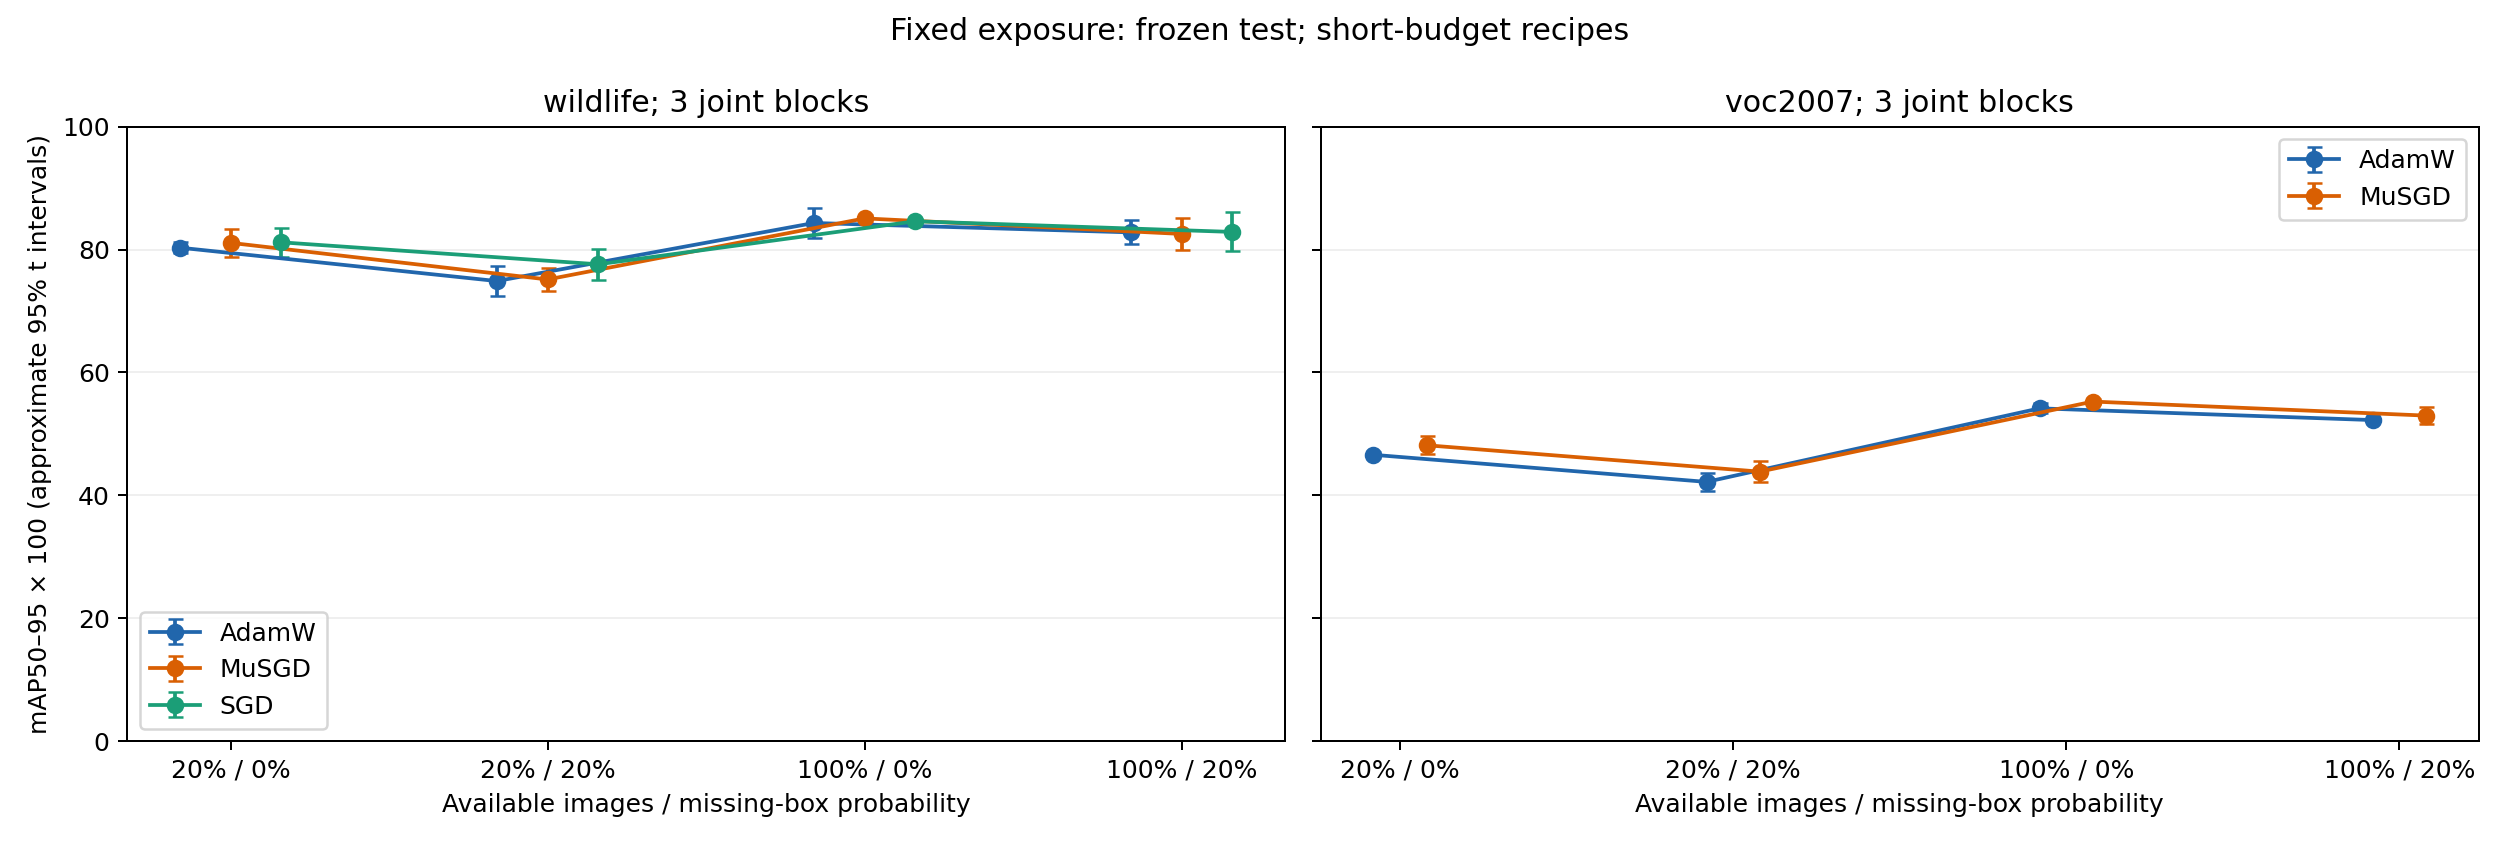

journal_validation.png


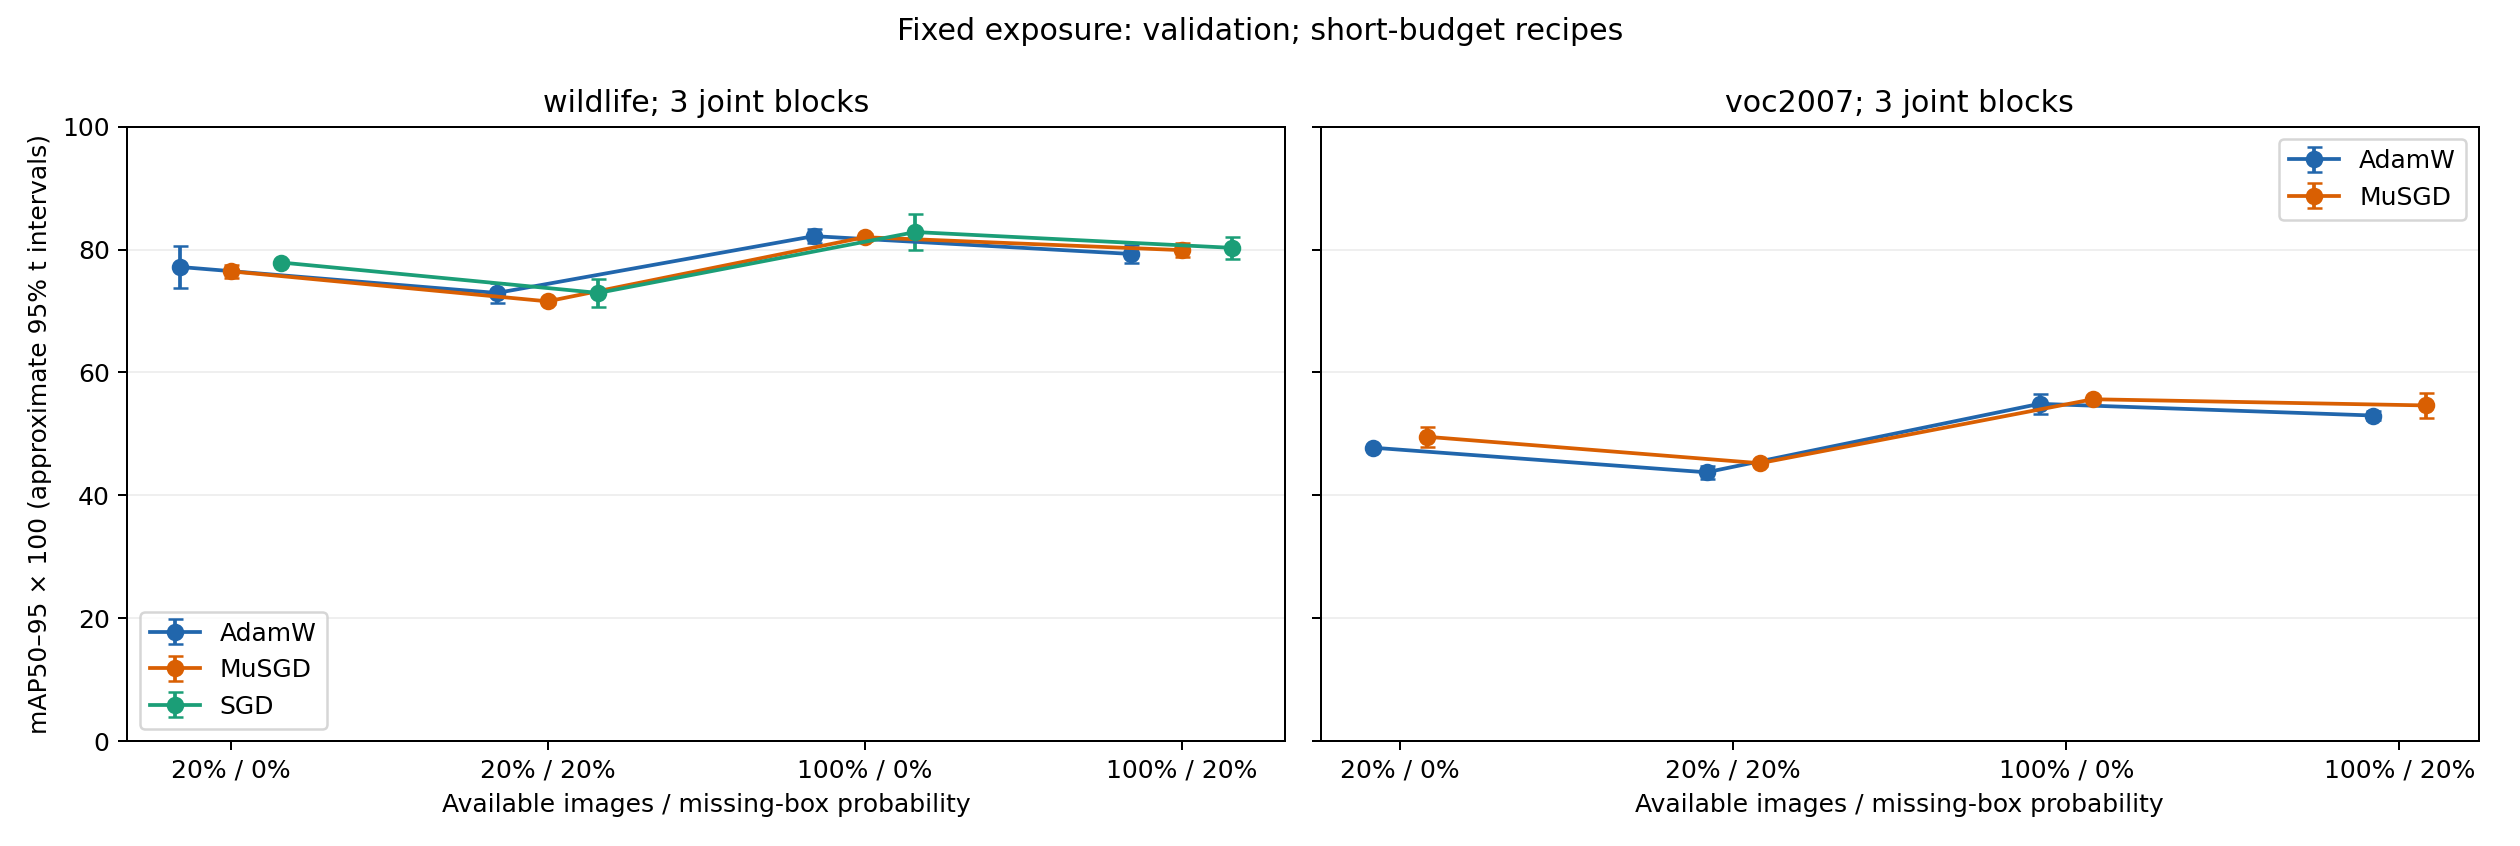

In [3]:
figures={'journal_frozen_test.png': '...', 'journal_validation.png': '...'}
for name,encoded in figures.items():
    print(name)
    display(Image(data=base64.b64decode(encoded)))
